**!!! IMPORTANT NOTE !!!** : All output generated from this notebook can be find in **[here](https://drive.google.com/drive/folders/1RDw2wUKpYiQyIx8HCfeP5DRVOkulhwFP?usp=drive_link)**

# **1. Project Setup and Data Loading**

###Setup

In [ ]:
import pandas as pd
import numpy as np
import re
import os
import warnings
import gdown
warnings.filterwarnings('ignore')
!pip install gensim

# Visualization
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

# Sklearn — RQ1: Text & Metadata Classification
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
# metadata baseline
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_validate
from sklearn.manifold import TSNE

# Sklearn — RQ2 & RQ3: Topic Modelling + Country Bias
from sklearn.decomposition import NMF, TruncatedSVD
# NMF = primary, TruncatedSVD = optional
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_predict
from sklearn.inspection import permutation_importance
# Importing permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay

# Sklearn — RQ3 & future RQs: Cosine Similarity + Dimensionality Reduction
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

# Gensim — RQ4: Word2Vec (Margin of Appreciation)
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

# Theme
PALETTE = {
    'Violation':    '#CC5441',
    'No Violation': '#A0E3E8'
}
CMAP = 'Blues'
sns.set_theme(style='whitegrid')
sns.set_palette([PALETTE['Violation'], PALETTE['No Violation']])

print('Libraries loaded successfully.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 19.4 MB/s eta 0:00:00
Libraries loaded successfully.


###Data Loading and Preprocessing

**Data Source & Validation Summary**

Primary Source: Data was originally sourced from [echr-opendata.eu](https://echr-opendata.eu). The site provides several kinds of pre-processed data. For this project, we use *"unstructured cases in JSON".*

**Current Status**

While the primary source website currently returns a "502 Bad Gateway" error, a stable local version of the dataset was successfully archived as of 9 February 2026.

**Temporal Scope**

The dataset provides comprehensive coverage of Article 8 cases from the Court's inception through 2023. We use data related to Article 8, from 2010 - 2023.

**Integrity Verification**

To ensure the reliability of the JSON data, random sampling was conducted to compare the archived local files against the official HUDOC (ECHR) database.  Cross-referencing confirmed that the text sections and metadata in the JSON files are **identical** to the official records, validating the dataset's accuracy for high-importance legal analysis.

*Other documentation:* [Github](https://github.com/echr-od/ECHR-OD_process)

In [ ]:
# Download and load raw data
FILE_ID = '10DvcRnmAjxTPXo4C4JGE7E9UPEoZxNQX'
url = f'https://drive.google.com/uc?id={FILE_ID}'
gdown.download(url, 'echr_raw.json', quiet=False, fuzzy=True)

df_raw = pd.read_json('echr_raw.json')
df_raw['date_dt'] = pd.to_datetime(df_raw['judgementdate'], dayfirst=True, errors='coerce')
df_raw['year'] = df_raw['date_dt'].dt.year

# Filter Article 8 cases 2010-2023
def mentions_article_8(val):
    if isinstance(val, list):
        return '8' in [str(x).strip() for x in val]
    if isinstance(val, str):
        return '8' in [x.strip() for x in val.replace(',', ';').split(';')]
    return False

art_col = 'article' if 'article' in df_raw.columns else '__articles'
mask_art8 = df_raw[art_col].apply(mentions_article_8)
mask_year = df_raw['year'].between(2010, 2023)

df_art8 = df_raw[mask_art8 & mask_year][[
    'itemid',
    'docname',
    'conclusion',
    'content',
    'respondent',            # respondent state
    'year',                  # temporal signal
    'importance',            # case weight (1–4)
    'originatingbody_type',  # Section vs. Grand Chamber
    'typedescription',       # judgment vs. decision type
    'languageisocode',       # language artefact control
    'separateopinion',
    'date_dt'       # dissent flag — contested cases
]].copy()

# Feature engineering
df_art8['has_dissent']  = df_art8['separateopinion'].notna().astype(int)
df_art8['is_english']   = (df_art8['languageisocode'] == 'ENG').astype(int)
df_art8['importance']   = df_art8['importance'].astype(str)

# Modified: Ensure respondent_country only contains one country
df_art8['respondent'] = df_art8['respondent'].astype(str).apply(lambda x: x.split(';')[0].strip() if ';' in x else x.strip())
df_art8['originatingbody_type'] = df_art8['originatingbody_type'].astype(str)
df_art8['typedescription']      = df_art8['typedescription'].astype(str)

df_art8 = df_art8.rename(columns={
    'docname':              'title',
    'conclusion':           'conclusion_structured',
    'content':              'full_text',
    'respondent':           'respondent_country',
    'originatingbody_type': 'court'
})

print(f'Article 8 cases (2010-2023): {len(df_art8):,}')

Downloading...
From (original): https://drive.google.com/uc?id=10DvcRnmAjxTPXo4C4JGE7E9UPEoZxNQX
From (redirected): https://drive.google.com/uc?id=10DvcRnmAjxTPXo4C4JGE7E9UPEoZxNQX&confirm=t&uuid=dfd3f991-84a0-47df-b09d-e0663901a865
To: /content/echr_raw.json
100%|██████████| 1.09G/1.09G [00:15<00:00, 70.3MB/s]


Article 8 cases (2010-2023): 1,321


In [ ]:
# Save filtered dataset to local storage — run once
df_art8.to_parquet('/content/echr_art8_filtered.parquet', index=False)

In [ ]:
SAVE_PATH = '/content/'

#**2. Feature Engineering**

###Text Extraction

The raw dataset contains 1,321 Article 8 cases with a severe 3.5:1 class imbalance (982 violations to 283 non-violations). This ~77.7% violation rate is not a sampling error, but the institutional reality of the ECHR's strict admissibility filter pre-screening weak cases. Because a naive baseline model could achieve 77% accuracy simply by guessing "Violation" every time, we rely on Macro F1 and balanced class weights to evaluate true predictive power.

During preprocessing, 56 cases flagged as "Only Mentioning" were explicitly filtered out of the dataset. These represent judgments that were settled via Just Satisfaction or struck out without a substantive ruling on the merits. Removing them leaves exactly 1,265 usable binary cases (Violation vs. No Violation) for our machine learning classifiers.

In [ ]:
# Recursive content extractor
def extract_content_recursive(data):
    text_parts = []
    if isinstance(data, dict):
        if 'content' in data and isinstance(data['content'], str):
            text_parts.append(data['content'])
        if 'elements' in data and isinstance(data['elements'], list):
            for element in data['elements']:
                text_parts.extend(extract_content_recursive(element))
    return text_parts

def extract_section_text(full_text_entry, sections_to_include=None, sections_to_exclude=None):
    if not isinstance(full_text_entry, dict):
        return str(full_text_entry) if full_text_entry else ''
    all_text = []
    for doc_key, sections_list in full_text_entry.items():
        if isinstance(sections_list, list):
            for section in sections_list:
                if isinstance(section, dict):
                    section_name = section.get('section_name', '').lower().strip()
                    if sections_to_include and section_name not in sections_to_include:
                        continue
                    if sections_to_exclude and section_name in sections_to_exclude:
                        continue
                    all_text.extend(extract_content_recursive(section))
    return ' '.join(all_text)

def extract_best_available_text(full_text_entry):
    """Extract facts + law text, falling back to full text for non-standard cases."""
    facts = extract_section_text(full_text_entry, sections_to_include=['facts','relevant_law'])
    law   = extract_section_text(full_text_entry, sections_to_include=['law'])
    combined = ' '.join([facts, law]).strip()
    if len(combined.split()) < 50:
        return extract_section_text(
            full_text_entry,
            sections_to_exclude=['toc', 'appendix', 'conclusion']
        )
    return combined

# Helper function to remove numbers and symbols from text
def clean_text_for_tfidf(text):
    text = re.sub(r'[^a-z\s]', '', text.lower()) # Keep only lowercase letters and spaces
    text = re.sub(r'\s+', ' ', text).strip() # Remove extra spaces
    return text

df_art8['analysis_text'] = df_art8['full_text'].apply(extract_best_available_text)
# Apply cleaning to analysis_text immediately after extraction
df_art8['analysis_text'] = df_art8['analysis_text'].apply(clean_text_for_tfidf)
print(f"Text extracted. Mean word count: {df_art8['analysis_text'].apply(lambda x: len(x.split())).mean():,.0f}")

# Print 2 examples of extracted 'analysis_text'
print('\n--- Example 1 of Facts Section ---')
print(clean_text_for_tfidf(extract_section_text(df_art8['full_text'].iloc[0], sections_to_include=['facts', 'relevant_law']))[:500] + '...')

# Print first 500 characters for brevity
print('\n--- Example 2 of Law Section ---')
print(clean_text_for_tfidf(extract_section_text(df_art8['full_text'].iloc[1], sections_to_include=['law']))[:500] + '...')

# Extract facts and law sections into new columns
df_art8['facts_text'] = df_art8['full_text'].apply(lambda x: extract_section_text(x, sections_to_include=['facts', 'relevant_law']))
df_art8['law_text'] = df_art8['full_text'].apply(lambda x: extract_section_text(x, sections_to_include=['law']))

# *** NEW: Create a raw version of law_text for Word2Vec that retains punctuation ***
df_art8['law_text_w2v_raw'] = df_art8['full_text'].apply(lambda x: extract_section_text(x, sections_to_include=['law']))

# Apply cleaning to facts_text and law_text
df_art8['facts_text'] = df_art8['facts_text'].apply(clean_text_for_tfidf)
df_art8['law_text'] = df_art8['law_text'].apply(clean_text_for_tfidf)

# Placeholder for 'law_text_clean' for the leakage test variant (V3)
# If specific 'remedies language' needs to be removed, this line should be modified.
df_art8['law_text_clean'] = df_art8['law_text'].copy()

# Calculate and print mean and median word counts for facts and law sections
print(f"\nMean word count for Facts Section: {df_art8['facts_text'].apply(lambda x: len(x.split())).mean():,.0f}")
print(f"Median word count for Facts Section: {df_art8['facts_text'].apply(lambda x: len(x.split())).median():,.0f}")
print(f"\nMean word count for Law Section: {df_art8['law_text'].apply(lambda x: len(x.split())).mean():,.0f}")
print(f"Median word count for Law Section: {df_art8['law_text'].apply(lambda x: len(x.split())).median():,.0f}")
print(f"\nMean word count for Combined Section: {df_art8['analysis_text'].apply(lambda x: len(x.split())).mean():,.0f}")
print(f"Median word count for Combined Section: {df_art8['analysis_text'].apply(lambda x: len(x.split())).median():,.0f}")

Text extracted. Mean word count: 8,651

--- Example 1 of Facts Section ---
the facts i the circumstances of the case a application no zubkov v russia on april the local police sent to the local investigations committee audio recordings of telephone conversations between the applicant and several persons and video recordings of their meetings in a flat in novgorod the accompanying letter which the government presented to the court stated that the audio and video recordings had been obtained in the course of covert operationalsearch measures authorised by the president o...

--- Example 2 of Law Section ---
the law i alleged violation of articles and of the convention the applicant complained that the state had failed to properly investigate the alleged rape the court considers that the complaint falls to be examined under articles and of the convention which in so far as relevant read as follows article no one shall be subjected to torture or to inhuman or degrading treatment or punishm

###Outcome Extraction

In [ ]:
import ast

def extract_finding_structured(conclusion_list):
    """Extract Article 8 finding from the structured conclusion column."""
    # Try to convert string representations of lists/dicts into actual Python objects
    if isinstance(conclusion_list, str):
        try:
            conclusion_list = ast.literal_eval(conclusion_list)
        except (ValueError, SyntaxError):
            return 'Only Mentioning' # Not a valid string representation of a list/dict

    if not isinstance(conclusion_list, list):
        return 'Only Mentioning'
    for item in conclusion_list:
        if not isinstance(item, dict):
            continue
        is_art8 = (
            item.get('base_article') == '8' or
            item.get('article') == '8' or
            re.search(r'art(icle)?\.?\s*8', str(item.get('element', '')), re.IGNORECASE))

        if is_art8:
            if item.get('type') == 'violation':
                return 'Violation'
            elif item.get('type') == 'no-violation':
                return 'No Violation'
    return 'Only Mentioning'

df_art8['finding'] = df_art8['conclusion_structured'].apply(extract_finding_structured)

print('Outcome distribution (df_art8):')
print(df_art8['finding'].value_counts())

Outcome distribution (df_art8):
finding
Violation          982
No Violation       283
Only Mentioning     56
Name: count, dtype: int64


###Legal Stop Words and English Stop Words

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re

def clean_stop_words_list(word_list):
    cleaned_list = []
    for word in word_list:
        # Remove numbers and symbols, keep only alphabetic characters
        cleaned_word = re.sub(r'[^a-z]', '', word.lower())
        if cleaned_word: # Only add if not empty after cleaning
            cleaned_list.append(cleaned_word)
    return cleaned_list

# --- Legal & Procedural Boilerplate ---
legal_procedural = [
    'read', 'conjunction', 'separately', 'preliminary', 'remainder', 'taken',
    'regarding', 'respective', 'respect', 'pursuant', 'herein', 'therein',
    'thereof', 'whereas', 'hereby', 'aforementioned', 'abovementioned',
    'inter', 'alia', 'mutatis', 'mutandis', 'prima', 'facie', 'application',
    'applicant', 'court', 'article', 'paragraph', 'section', 'case', 'matter',
    'judgment', 'decision', 'chamber', 'grand', 'respondent', 'government',
    'state', 'commission', 'protocol', 'convention', 'echr'
]
legal_procedural = clean_stop_words_list(legal_procedural)

# --- Article 8 Universal Framing Terms ---
# Appear in nearly every Art. 8 case regardless of outcome — low discriminative value
art8_universal = [
    'private', 'family', 'democratic', 'society', 'legitimate',  'aim', 'authority', 'domestic', 'national'
]
art8_universal = clean_stop_words_list(art8_universal)

# --- Facts Section Structural Artifacts ---
# Appear in Facts section formatting, not substantive content
facts_specific_noise = [
    'international', 'text', 'introduction', 'comparative', 'relevant',
    'material', 'appended', 'table', 'list', 'set', 'complained',
    'complaint', 'raised', 'provision','interference'
]
facts_specific_noise = clean_stop_words_list(facts_specific_noise)

# Remedies vocabulary — outcome-leaking terms specific to Law section
remedies_leakage = [
    'damage', 'damages', 'eur', 'costs', 'satisfaction',
    'award', 'reimburse', 'reimbursement', 'pecuniary',
    'non-pecuniary', 'just', 'compensation', 'penalty',
    'fine', 'euros', 'sum', 'paid', 'payable','violation', 'breach', 'infringement', 'complied', 'upheld',
    'dismissed', 'allowed', 'inadmissible', 'admissible', 'non', 'struck',
    'reparation','injured','contracting','partial','incurred','expenses','default','rate','afford','allows', "party", "high", "concerned", "internal"]
remedies_leakage = clean_stop_words_list(remedies_leakage)

# -----------------------------------------------------------------------
# Combined Stop Word Lists — one per text column
# -----------------------------------------------------------------------

# Shared foundation
base_stop_words = (
    list(ENGLISH_STOP_WORDS) +
    legal_procedural +
    art8_universal
)

# RQ1 primary text variant — fairest comparison against metadata
custom_facts_stop_words = base_stop_words + facts_specific_noise

# RQ1 diagnostic leakage variant + RQ4 Word2Vec training corpus
custom_law_stop_words = base_stop_words

# RQ1 leakage test variant (V3) - for 'law_text_clean'


# V3 Law Clean — base + remedies stripped
custom_law_clean_stop_words = base_stop_words + remedies_leakage

# For RQ4 Word2Vec focal terms

custom_w2v_stop_words = (
    list(ENGLISH_STOP_WORDS) +
    legal_procedural
)
# Remove the specific focal terms from the custom_w2v_stop_words list if they accidentally got added

custom_w2v_stop_words = [word for word in custom_w2v_stop_words if 'w2v_focal_terms_to_retain' not in locals() or word not in w2v_focal_terms_to_retain]
custom_analysis_stop_words = base_stop_words


print('Stop word lists built.')
print(f'  base_stop_words          : {len(base_stop_words):,} terms')
print(f'  custom_facts_stop_words  : {len(custom_facts_stop_words):,} terms')
print(f'  custom_law_stop_words    : {len(custom_law_stop_words):,} terms')
print(f'  custom_law_clean_stop_words: {len(custom_law_clean_stop_words):,} terms')
print(f'  custom_analysis_stop_words: {len(custom_analysis_stop_words):,} terms')
print(f'  custom_w2v_stop_words    : {len(custom_w2v_stop_words):,} terms (for Word2Vec with focal terms retained)')

Stop word lists built.
  base_stop_words          : 369 terms
  custom_facts_stop_words  : 384 terms
  custom_law_stop_words    : 369 terms
  custom_law_clean_stop_words: 412 terms
  custom_analysis_stop_words: 369 terms
  custom_w2v_stop_words    : 360 terms (for Word2Vec with focal terms retained)


##Country Mapping

In [ ]:
# --- Create a mapping for country codes to full names ---
country_name_map = {
    'ALB': 'Albania',
    'ALB;ITA': 'Albania; Italy',
    'AND': 'Andorra',
    'ARM': 'Armenia',
    'AUT': 'Austria',
    'AUT;SVN': 'Austria; Slovenia',
    'AZE': 'Azerbaijan',
    'AZE;TUR': 'Azerbaijan; Turkey',
    'BEL': 'Belgium',
    'BGR': 'Bulgaria',
    'BGR;ROU': 'Bulgaria; Romania',
    'BIH': 'Bosnia and Herzegovina',
    'CHE': 'Switzerland',
    'CYP': 'Cyprus',
    'CZE': 'Czech Republic',
    'DEU': 'Germany',
    'DNK': 'Denmark',
    'ESP': 'Spain',
    'EST': 'Estonia',
    'FIN': 'Finland',
    'FRA': 'France',
    'GBR': 'United Kingdom',
    'GEO': 'Georgia',
    'GRC': 'Greece',
    'HRV': 'Croatia',
    'HUN': 'Hungary',
    'IRL': 'Ireland',
    'ISL': 'Iceland',
    'ISR': 'Israel',
    'ITA': 'Italy',
    'LTU': 'Lithuania',
    'LUX': 'Luxembourg',
    'LVA': 'Latvia',
    'MDA': 'Moldova',
    'MDA;RUS': 'Moldova; Russia',
    'MKD': 'North Macedonia',
    'MLT': 'Malta',
    'MNE': 'Montenegro',
    'NLD': 'Netherlands',
    'NOR': 'Norway',
    'POL': 'Poland',
    'PRT': 'Portugal',
    'ROU': 'Romania',
    'RUS': 'Russia',
    'RUS;UKR': 'Russia; Ukraine',
    'SMR': 'San Marino',
    'SRB': 'Serbia',
    'SVK': 'Slovakia',
    'SVN': 'Slovenia',
    'SWE': 'Sweden',
    'TUR': 'Turkey',
    'UKR': 'Ukraine'
}

# Project Overview and Research Design

## Motivation

The European Court of Human Rights (ECtHR) produces thousands of judgments each year adjudicating alleged violations of the Convention rights of individuals across 46 member states. Article 8, which protects the right to respect for private and family life, home, and correspondence, covers a range of claims from state surveillance and deportation to child custody disputes and data protection. Whether these decisions are predictable from the text of the judgments themselves, or from structural case attributes, has direct implications for how we understand consistency and rule of law in international human rights adjudication. If outcomes can be reliably predicted from pre-decision text, that raises questions about whether the Court's reasoning is genuinely deliberative or structurally determined. If they cannot, that tells us something different about the complexity and context-dependence of proportionality reasoning under Article 8.

## Research Design

The modelling programme is structured around four research questions that build on each other in a deliberate sequence.

RQ1 asks whether case text outperforms structured metadata (respondent country, year, importance level) as a predictor of Article 8 outcomes, and which section of the judgment carries the stronger signal. This establishes a performance baseline and motivates the subsequent questions by revealing what the text-based signal actually consists of.

RQ2 asks what the dominant themes across the Article 8 corpus are, using unsupervised topic modelling to map the substantive legal landscape and assess whether NMF-derived topic weights can themselves serve as predictive features.

RQ3 asks whether models trained on one regional bloc of cases (Eastern or Western Europe) generalise to the other, testing whether the predictive signal from RQ1 is legally universal or geographically contingent.

RQ4 asks why any generalisation gap exists, using distributional word embeddings to test whether core Article 8 doctrinal terms carry different semantic content in the two regional corpora and whether that semantic drift accounts for the classifier's failure.

Each research question is answered using a combination of supervised classification, unsupervised representation learning, and feature importance analysis, with evaluation grounded in the macro F1 metric throughout.

##Modeling Approach and Methodology
Our modeling strategy focuses on gaining diverse insights from the legal dataset rather than chasing marginal gains in predictive accuracy. We utilize **TF-IDF (Term Frequency-Inverse Document Frequency)** to represent our text; this technique works by highlighting words that are unique and descriptive to specific documents while downweighting common words that appear everywhere and carry little discriminatory power. To evaluate our results, we employ three distinct classifiers chosen for their complementary strengths. **Naive Bayes** serves as our primary baseline because it is computationally efficient and relies on a simple "independence" assumption that, while theoretically basic, often performs surprisingly well on high-dimensional text data. **Logistic Regression** is included for its reliability in binary classification tasks and its high interpretability, allowing us to see how specific features influence a case's outcome. Finally, we implement **Support Vector Machines (SVM)**, which is the gold standard in legal NLP literature due to its effectiveness in handling the complex, high-dimensional boundaries inherent in legal language. We initially thought that Logistic Regression and SVM will produce different result, but throughout this notebook turns out the result between these two model is always quite similar.

To ensure the reliability of these results, we use **5-fold Stratified K-Fold cross-validation**, which preserves the percentage of samples for each class in every fold, ensuring our performance metrics are not skewed by the dataset's distribution. While we use **SMOTE (Synthetic Minority Over-sampling Technique)** on top of 'weight=balanced' to address class imbalance in our metadata and topic-based features, we intentionally exclude it from the raw text features, as the "synthetic noise" generated by SMOTE often struggles to maintain meaningful relationships in the extremely high-dimensional space of a large vocabulary. Furthermore, our focus remains on breadth over deep fine-tuning; by exploring a wide variety of techniques rather than hyper-optimizing a single one, we can extract more nuanced insights and observe the data through multiple analytical "lenses."

#**RQ1 : Text vs. Metadata**


---


**"Does case text provide stronger predictive signal for Article 8 outcomes than structured metadata (country, year, importance level)?"**


---


**Step 1**, we train on a metadata and see which model has the best performance.

**Step 2** we train on a text features to see if it can beat the model trained on metadata. we also tested on different text section : Facts vs Law.

**Step 3** we train on both metadata and text features to see if these two actually complementary or redundant

**The hypothesis** : Model trained on text features will perform better than the metadata. If metadata proven to perform better than text features, then we find proof about structural bias in the Article 8 case files.

## **Metadata**

---

**Input :**
* CAT_FEATURES = ['respondent_country', 'importance', 'court', 'typedescription']
* NUM_FEATURES = ['year', 'has_dissent', 'is_english']
---

**Models :**
* Naive Bayes (baseline)
* Logistic Regression
* SVM (as used in Aletras)

---

**Output:**  'finding'


---

**Hypothesis:** Naive Bayes perform worst. Either LogReg or SVM perform best but won't be too different

Before diving into our results, it's worth being precise about what each evaluation metric actually means in the context of predicting Article 8 outcomes.
* **Accuracy** is the most intuitive — it simply asks "what proportion of cases did the model get right?" — but it becomes misleading when classes are imbalanced. With 982 Violations and only 283 No Violations in our dataset, a model that predicted Violation for every single case would achieve 77.7% accuracy while being completely useless in practice.
* **Precision and recall** capture something more nuanced. Precision asks: of all the cases the model flagged as Violations, how many actually were? Recall flips the question: of all the actual Violations in the dataset, how many did the model catch? These two metrics are inherently in tension — pushing recall up (catching more true Violations) tends to drag precision down (making more false positive calls), and vice versa.
* **F1 score** is the standard way to balance this trade-off, computing the harmonic mean of the two. We specifically use macro F1, which calculates F1 separately for each class and averages them equally — so the model is held equally accountable for its performance on No Violation cases as on Violation cases, regardless of how much rarer they are.

How to handle this evaluation problem is something precedent work has approached differently.
* **Aletras et al. (2016)**, whose methodology directly informs our own, used accuracy as their primary metric and reported a strong 79% average across Articles 3, 6 and 8. This was a reasonable choice for their study because they deliberately constructed a balanced dataset — randomly sampling equal numbers of violation and non-violation cases for each article, ending up with 254 cases for Article 8. When classes are balanced, accuracy tells you most of what you need to know.
* **Akdemir (2023)**, working on a very different problem — predicting which US Supreme Court certiorari petitions would be granted — faced a much more extreme imbalance of roughly 20:1 (1,012 denied petitions versus just 50 granted). He makes a compelling case that accuracy is essentially meaningless in this setting, pointing out that a dummy classifier predicting denial every time would score very highly without learning anything at all. Instead he prioritised recall, reasoning that missing a genuinely grantworthy petition — a false negative — was the more costly error. He also moved away from standard cross-validation entirely, adopting Monte Carlo Cross-Validation over 1,000 simulations to get more stable estimates under severe imbalance.

Our situation falls somewhere between these two. Our imbalance at roughly 3.5:1 is meaningful but nowhere near as severe as Akdemir's, so accuracy retains some interpretive value and we do report it. But we don't think it should be the headline metric. Following the spirit of Akdemir's argument, we want our model to be genuinely useful on both classes — identifying No Violation cases matters just as much as identifying Violations from a legal standpoint, since both represent substantively different human rights outcomes. **Macro F1 is therefore our primary metric**. To be precise about what this means: F1 score can actually be computed in several ways. Binary F1 evaluates performance on a single class only, while weighted F1 averages across classes but gives more weight to whichever class has more cases — in our dataset that would mean Violation's F1 dominates at 77%, quietly hiding poor performance on No Violations. Macro F1 instead calculates F1 separately for each class and averages them equally, so the model is held to the same standard on both outcomes regardless of how frequently each appears. This directly penalises the kind of majority-class bias that accuracy masks, which is what we want. We handle the imbalance during training by using class_weight='balanced' in our classifiers rather than artificially resampling the data, which preserves all 1,265 cases while still preventing the model from simply defaulting to Violation for everything. Precision and recall are reported alongside F1 so readers can see the full picture of where the model succeeds and where it struggles.


RQ1 metadata dataset: 1,265 cases
Outcome distribution:
finding
Violation       982
No Violation    283
Name: count, dtype: int64

Running metadata classifiers...
--------------------------------------------------
Logistic Regression       → F1_macro: 0.6432 ± 0.0220

Classification Report for Logistic Regression:

              precision    recall  f1-score   support

No Violation       0.40      0.66      0.50       283
   Violation       0.88      0.71      0.79       982

    accuracy                           0.70      1265
   macro avg       0.64      0.69      0.64      1265
weighted avg       0.77      0.70      0.72      1265

--------------------------------------------------
Naive Bayes               → F1_macro: 0.3056 ± 0.0572

Classification Report for Naive Bayes:

              precision    recall  f1-score   support

No Violation       0.24      0.93      0.38       283
   Violation       0.88      0.14      0.24       982

    accuracy                           0.32   

,Model,F1_macro,F1_macro_std,Accuracy,Precision_macro,Recall_macro
0,SVM,0.6493,0.0250,0.7107,0.6447,0.6903
1,Logistic Regression,0.6432,0.0220,0.7020,0.6412,0.6885
2,Naive Bayes,0.3056,0.0572,0.3154,0.5448,0.5351



>>> Metadata F1_macro floor  : 0.6493
>>> Best model         : SVM
>>> Text arm must beat : 0.6493 to justify NLP


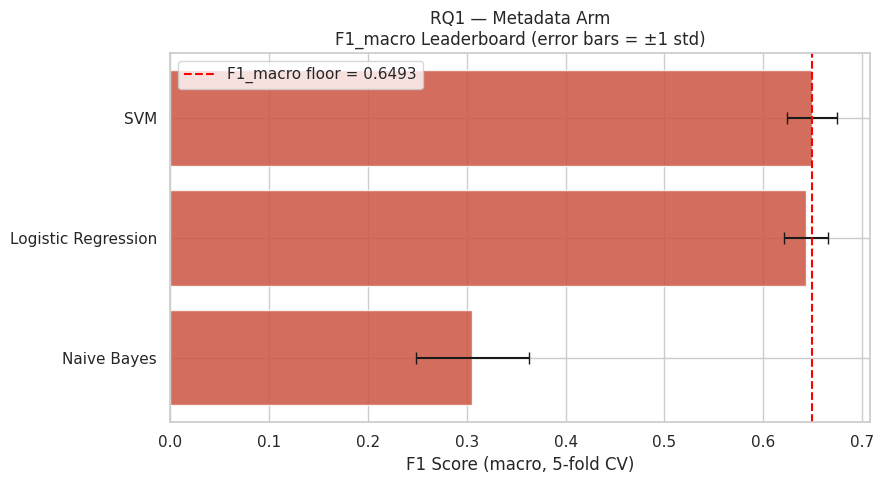

Results saved to /content/


In [ ]:
# ── Step 1: Create RQ1 metadata DataFrame from master ─────
df_meta = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()

print(f'RQ1 metadata dataset: {len(df_meta):,} cases')
print(f'Outcome distribution:\n{df_meta["finding"].value_counts()}\n')

# ── Step 2: Feature engineering ─────────────────────────
df_meta['has_dissent'] = df_meta['separateopinion'].notna().astype(int)
df_meta['is_english'] = (df_meta['languageisocode'] == 'ENG').astype(int)
df_meta['importance'] = df_meta['importance'].astype(str).fillna('unknown')
df_meta['respondent_country'] = df_meta['respondent_country'].astype(str).fillna('unknown')
df_meta['court'] = df_meta['court'].astype(str).fillna('unknown')
df_meta['typedescription'] = df_meta['typedescription'].astype(str).fillna('unknown')

# ── Step 3: Define features and target ──────────────
CAT_FEATURES = ['respondent_country', 'importance', 'court', 'typedescription']
NUM_FEATURES = ['year', 'has_dissent', 'is_english']
TARGET       = 'finding'

X_meta = df_meta[CAT_FEATURES + NUM_FEATURES]
y_meta = df_meta[TARGET]

# ── Step 4: Preprocessor ─────────────────────────
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_FEATURES),
    ('num', StandardScaler(), NUM_FEATURES)
])

# ── Step 5: Classifiers (with SMOTE for LR and SVM) ─────────────────────────
METADATA_CLASSIFIERS = {
    'Logistic Regression'  : ImbPipeline([
                                ('pre', preprocessor),
                                ('smote', SMOTE(random_state=42)),
                                ('clf', LogisticRegression(max_iter=1000, random_state=42))
                            ]),
    'Naive Bayes'        : Pipeline([
                                ('pre', preprocessor),
                                ('clf', GaussianNB()) # GaussianNB does not support SMOTE directly in this setup, or class_weight
                            ]),
    'SVM'        : ImbPipeline([
                                ('pre', preprocessor),
                                ('smote', SMOTE(random_state=42)),
                                ('clf', CalibratedClassifierCV(LinearSVC(random_state=42, max_iter=2000)))
                            ])
}

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ── Step 6: Run all classifiers ─────────────────────
meta_results = []
print('Running metadata classifiers...')
print('-' * 50)

# For Logistic Regression and SVM, the pipeline already includes preprocessing and SMOTE
# For Naive Bayes, the preprocessor needs to be applied first

for clf_name, clf_pipeline in METADATA_CLASSIFIERS.items():
    if clf_name == 'Naive Bayes':
        # For GaussianNB, the preprocessor and classifier are within the pipeline already defined above
        # and SMOTE is not typically used with GaussianNB in this direct manner due to its nature.
        # The preprocessing is handled by the pipeline structure defined for it.
        current_pipeline = clf_pipeline
        current_X = X_meta
        current_y = y_meta
    else:
        # For models using ImbPipeline, the SMOTE and classifier are within the pipeline
        current_pipeline = clf_pipeline
        current_X = X_meta
        current_y = y_meta

    scores = cross_validate(
        current_pipeline, current_X, current_y, cv=CV,
        scoring  = ['f1_macro', 'accuracy',
                    'precision_macro', 'recall_macro'],
        n_jobs   = -1
    )
    meta_results.append({
        'Model'    : clf_name,
        'F1_macro'       : scores['test_f1_macro'].mean(),
        'F1_macro_std'   : scores['test_f1_macro'].std(),
        'Accuracy' : scores['test_accuracy'].mean(),
        'Precision_macro': scores['test_precision_macro'].mean(),
        'Recall_macro'   : scores['test_recall_macro'].mean()
    })
    print(f'{clf_name:25s} → F1_macro: {meta_results[-1]["F1_macro"]:.4f} ± {meta_results[-1]["F1_macro_std"]:.4f}')

    # Generate full classification report
    y_pred = cross_val_predict(current_pipeline, current_X, current_y, cv=CV, n_jobs=-1)
    print(f'\nClassification Report for {clf_name}:\n')
    print(classification_report(current_y, y_pred, target_names=['No Violation', 'Violation']))
    print('-' * 50)

# ── Step 7: Build results table ───────────────────
df_meta_results = (pd.DataFrame(meta_results)
                     .sort_values('F1_macro', ascending=False)
                     .round(4)
                     .reset_index(drop=True))

print('\n' + '=' * 55)
print('RQ1 METADATA ARM — Leaderboard (sorted by F1_macro)')
print('=' * 55)
display(df_meta_results)

# ── Step 8: Extract F1 floor ───────────────────
metadata_f1_floor        = df_meta_results.iloc[0]['F1_macro']
metadata_best_model_name = df_meta_results.iloc[0]['Model']

print(f'\n>>> Metadata F1_macro floor  : {metadata_f1_floor:.4f}')
print(f'>>> Best model         : {metadata_best_model_name}')
print(f'>>> Text arm must beat : {metadata_f1_floor:.4f} to justify NLP')

# --- Create the SAVE_PATH directory if it doesn't exist ---
import os
os.makedirs(SAVE_PATH, exist_ok=True)

# ── Step 9: Visualisation ─────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = df_meta_results.sort_values('F1_macro', ascending=True)
ax.barh(plot_df['Model'], plot_df['F1_macro'],
        xerr=plot_df['F1_macro_std'], color=PALETTE['Violation'],
        capsize=4, alpha=0.85)
ax.axvline(x=metadata_f1_floor, color='red', linestyle='--', linewidth=1.5,
           label=f'F1_macro floor = {metadata_f1_floor:.4f}')
ax.set_xlabel('F1 Score (macro, 5-fold CV)')
ax.set_title('RQ1 — Metadata Arm\nF1_macro Leaderboard (error bars = ±1 std)')
ax.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_metadata_leaderboard.png', dpi=150)
plt.show()

# ── Step 10: Save to Drive ──────────────────
df_meta_results.to_csv(f'{SAVE_PATH}rq1_metadata_leaderboard.csv', index=False)
print(f'Results saved to {SAVE_PATH}')

In [ ]:
try:
    plt.savefig(f'{SAVE_PATH}rq1_metadata_leaderboard.png', dpi=150)
except Exception:
    pass  # skip saving if Drive not mounted

<Figure size 640x480 with 0 Axes>

In [ ]:
def map_country_feature_name(feature_name):
    if 'cat__respondent_country_' in feature_name:
        country_code = feature_name.replace('cat__respondent_country_', '')
        return country_name_map.get(country_code, feature_name) # Return original if not found
    return feature_name

###Metadata (SVM)
We found that SVM gave the best result. Therefore more detailed visualization only generated on SVM result
* Confusion Matrix
* Feature Importance
* Cross Entropy Loss & Predicted Probability


Confusion Matrix

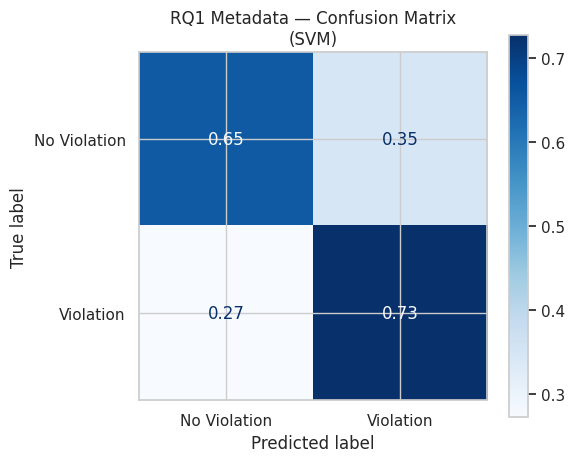

In [ ]:
# ══════════════════════════════════════════════════════════════════
# RQ1 — METADATA ARM VISUALIZATIONS

# ── 1. Confusion Matrix — best metadata model ─────────────────────
# Refit best model pipeline for cross_val_predict
best_meta_clf_pipeline = METADATA_CLASSIFIERS[metadata_best_model_name]

y_pred_meta = cross_val_predict(
    best_meta_clf_pipeline, X_meta, y_meta, cv=CV
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_meta, y_pred_meta,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax
)
ax.set_title(f'RQ1 Metadata — Confusion Matrix\n({metadata_best_model_name})')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_metadata_confusion_matrix.png', dpi=150)
plt.show()



Feature Importance

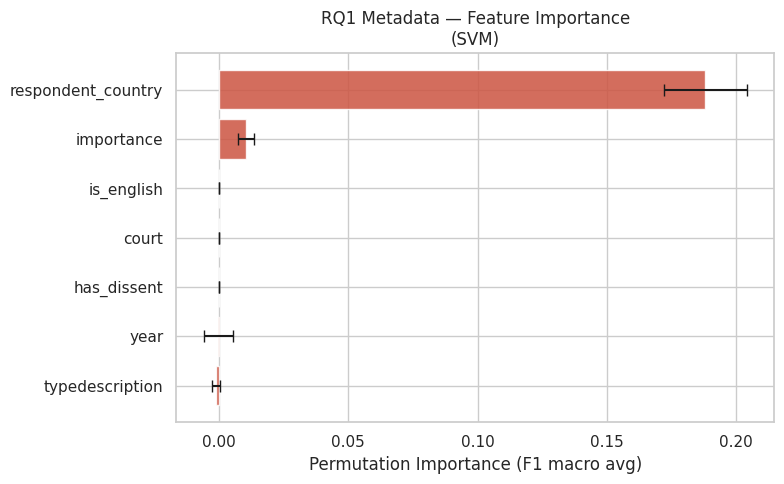

All metadata visualizations saved to Drive.


In [ ]:
# ── 2. Feature Importance — permutation importance ────────────────
best_meta_clf_pipeline.fit(X_meta, y_meta)

perm_imp = permutation_importance(
    best_meta_clf_pipeline, X_meta, y_meta,
    n_repeats   = 10,
    random_state= 42,
    scoring     = 'f1_macro',
    n_jobs      = -1
)

# Use original feature names directly — permutation_importance
# works at the pipeline input level, not OHE output level
imp_df = pd.DataFrame({
    'feature'   : CAT_FEATURES + NUM_FEATURES,
    'importance': perm_imp.importances_mean,
    'std'       : perm_imp.importances_std
}).sort_values('importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp_df['feature'], imp_df['importance'],
        xerr=imp_df['std'], color=PALETTE['Violation'],
        capsize=4, alpha=0.85)
ax.set_xlabel('Permutation Importance (F1 macro avg)')
ax.set_title(f'RQ1 Metadata — Feature Importance\n({metadata_best_model_name})')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_metadata_feature_importance.png', dpi=150)
plt.show()

print('All metadata visualizations saved to Drive.')

**Analysis**

The permutation importance plot for the meta data-only SVM reveals a disparity in the predictive contribution of each feature. The feature respondent_country dominates by an overwhelming margin with a permutation importance of approximately 0.145 which is roughly 10 times greater than the importance (~0.01). All remaining features contribute negligible predictive signal, with values nearly equal to zero.
This finding is consistent with the patterns identified during EDA, where Russia was found to be the single largest respondent state in the dataset and accounted for a disproportionate share of violation findings. The dominance of respondent_country suggests that the model is not learning reasoning of Article 8 outcomes but whether cases from certain states are systematically more likely to produce violations than others.

Although court formation and importance level were found to be highly correlated in the EDA, only importance retains a small predictive signal while court contributes essentially nothing. This suggests that importance level captures slightly more information about case complexity than court formation alone, though the difference is negligible given how strongly respondent_country dominates the model.

The negligible contribution of has_dissent and is_english indicates that the presence of separate opinions and the language of the judgment carry no predictive value in the metadata model, which is consistent with the expectation that these are procedural characteristics rather than substantive predictors of outcome.

Taken together, these results confirm that the metadata model's predictive performance is driven almost entirely by respondent country, raising significant concerns about its legal meaningfulness and generalisability. A model that learns "which country is being sued" rather than "what the judgment says" would be expected to perform poorly on cases from underrepresented states or in contexts where a state's human rights record changes over time. This directly motivates the comparison with text-based modelling in the subsequent analysis.


coef_df_with_counts created successfully.


,feature,coefficient,country_code,display_feature,total_cases,violation_cases,%_violation,no_violation_cases,%_no_violation
0,respondent_country_ALB,-0.596769,ALB,Albania,5,2,40.00,3,60.00
1,respondent_country_AND,-0.472973,AND,Andorra,1,0,0.00,1,100.00
2,respondent_country_ARM,0.222471,ARM,Armenia,7,5,71.43,2,28.57
3,respondent_country_AUT,-0.275074,AUT,Austria,25,14,56.00,11,44.00
4,respondent_country_AZE,1.063850,AZE,Azerbaijan,20,20,100.00,0,0.00



Top 15 Countries most indicative of 'Violation' (filtered):


,display_feature,coefficient,total_cases,violation_cases,%_violation,no_violation_cases,%_no_violation
40,Slovakia,1.205970,20,20,100.00,0,0.00
18,Georgia,1.082287,6,6,100.00,0,0.00
4,Azerbaijan,1.063850,20,20,100.00,0,0.00
31,Montenegro,1.041628,6,6,100.00,0,0.00
44,Ukraine,0.912132,107,103,96.26,4,3.74
29,North Macedonia,0.848101,12,11,91.67,1,8.33
7,Bosnia and Herzegovina,0.730998,2,2,100.00,0,0.00
37,Russia,0.706793,342,320,93.57,22,6.43
26,Luxembourg,0.391975,1,1,100.00,0,0.00
20,Croatia,0.351299,54,45,83.33,9,16.67



Top 15 Countries most indicative of 'No Violation' (filtered):


,display_feature,coefficient,total_cases,violation_cases,%_violation,no_violation_cases,%_no_violation
22,Ireland,-1.285433,2,0,0.00,2,100.00
23,Iceland,-0.760052,4,1,25.00,3,75.00
12,Denmark,-0.755763,17,6,35.29,11,64.71
11,Germany,-0.732575,32,9,28.12,23,71.88
32,Netherlands,-0.678699,10,4,40.00,6,60.00
42,Sweden,-0.635169,17,4,23.53,13,76.47
0,Albania,-0.596769,5,2,40.00,3,60.00
38,San Marino,-0.582225,2,1,50.00,1,50.00
25,Lithuania,-0.545832,29,14,48.28,15,51.72
5,Belgium,-0.533975,4,1,25.00,3,75.00


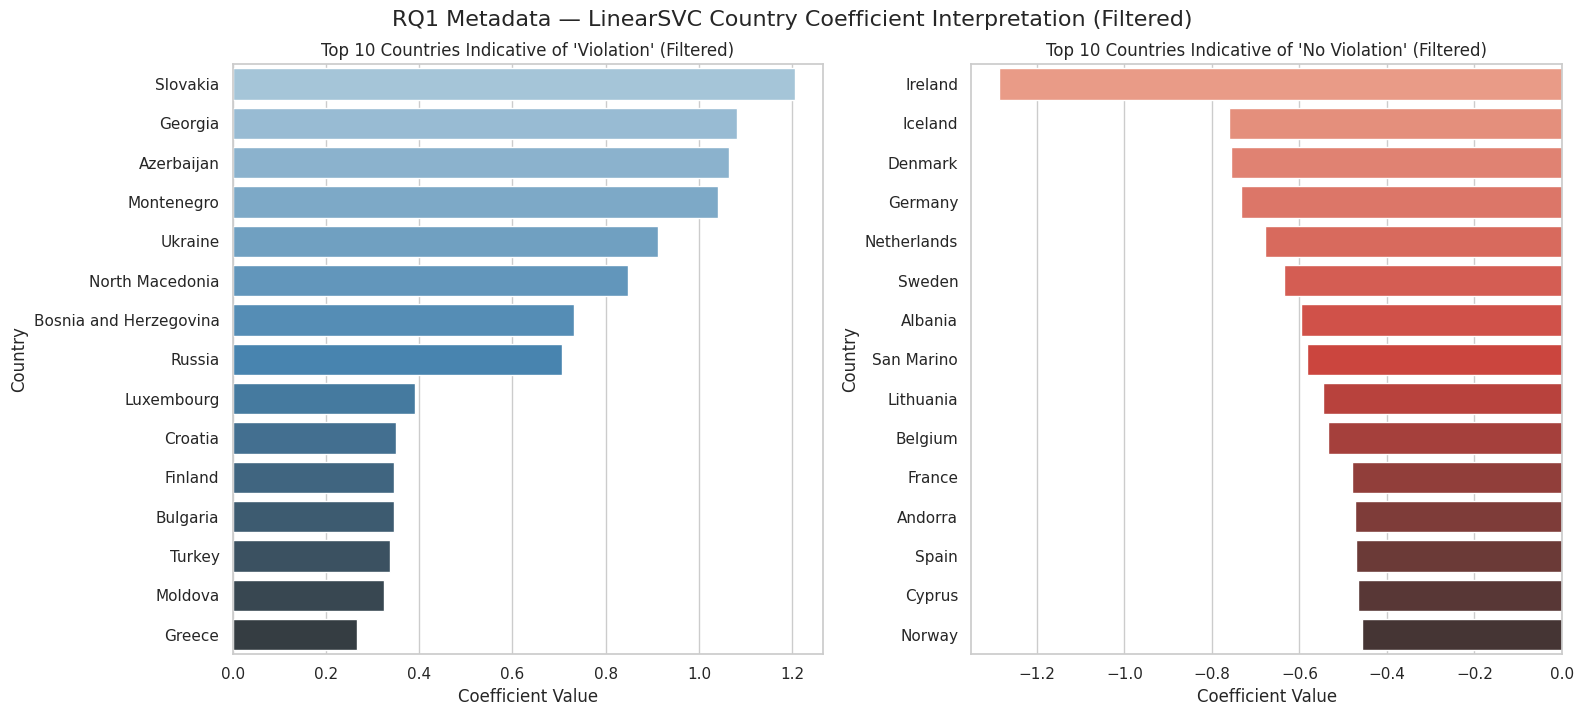

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Assuming best_meta_clf_pipeline, X_meta, y_meta, CAT_FEATURES, NUM_FEATURES are defined from previous cells
# Also assuming country_name_map and df_meta are defined.

# Refit the best metadata model to get access to its components
# This ensures the pipeline is fitted if the notebook was restarted at this point
best_meta_clf_pipeline.fit(X_meta, y_meta)

# Extract preprocessor and classifier from the pipeline
preprocessor = best_meta_clf_pipeline.named_steps['pre']
calibrated_svc = best_meta_clf_pipeline.named_steps['clf']

# Get feature names after preprocessing
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(CAT_FEATURES)
scaled_feature_names = NUM_FEATURES # Scaler output features have same names

# Combine all processed feature names. Note: ColumnTransformer prepends `cat__` to OHE features.
# However, `preprocessor.named_transformers_['cat'].get_feature_names_out(CAT_FEATURES)` provides names without `cat__`.
# We will use the names as generated by `get_feature_names_out` directly from the OHE transformer.
processed_feature_names = list(ohe_feature_names) + list(scaled_feature_names)

# Extract coefficients from the base LinearSVC inside CalibratedClassifierCV
# CalibratedClassifierCV stores multiple calibrated estimators — average their coefs
base_estimators = calibrated_svc.calibrated_classifiers_
coef_matrix = np.array([est.estimator.coef_[0] for est in base_estimators])
avg_coef = coef_matrix.mean(axis=0)

# Create a DataFrame of coefficients
coef_df = pd.DataFrame({
    'feature': processed_feature_names,
    'coefficient': avg_coef
})

# Filter for country features and map to display names
# Corrected prefix to 'respondent_country_' based on actual output from get_feature_names_out
country_coef_df = coef_df[
    coef_df['feature'].str.startswith('respondent_country_')
].copy()

country_coef_df['country_code'] = country_coef_df['feature'].apply(
    lambda x: x.replace('respondent_country_', '')
)
country_coef_df['display_feature'] = country_coef_df['country_code'].apply(
    lambda x: country_name_map.get(x, x)
)

# Calculate counts for each country and outcome
country_counts = df_meta.groupby(['respondent_country', 'finding']).size().unstack(fill_value=0)
country_counts['total_cases'] = country_counts.sum(axis=1)
country_counts['violation_cases'] = country_counts['Violation'] if 'Violation' in country_counts.columns else 0
country_counts['no_violation_cases'] = country_counts['No Violation'] if 'No Violation' in country_counts.columns else 0
country_counts['%_violation'] = (country_counts['violation_cases'] / country_counts['total_cases'] * 100).round(2)
country_counts['%_no_violation'] = (country_counts['no_violation_cases'] / country_counts['total_cases'] * 100).round(2)

# Merge coefficients with counts
# Use 'country_code' to merge with df_meta['respondent_country'] which is the actual country code
coef_df_with_counts = country_coef_df.merge(
    country_counts[['total_cases', 'violation_cases', '%_violation', 'no_violation_cases', '%_no_violation']],
    left_on='country_code',
    right_on='respondent_country',
    how='left'
)

# Ensure columns exist, fill NaNs
for col in ['total_cases', 'violation_cases', '%_violation', 'no_violation_cases', '%_no_violation']:
    if col not in coef_df_with_counts.columns:
        coef_df_with_counts[col] = 0
    coef_df_with_counts[col] = coef_df_with_counts[col].fillna(0)

print("coef_df_with_counts created successfully.")
display(coef_df_with_counts.head())

# Filter out 'low_frequency' feature, 'cat__importance_2', and countries with multiple respondents
# The 'cat__low_frequency' handles countries with less than 1% frequency.
# The 'display_feature' contains the mapped country names, which can include multiple countries joined by ';'.
# Removed filters with 'cat__' prefix as they don't match the actual feature names from OHE output
filtered_country_coef_df = coef_df_with_counts[
    (coef_df_with_counts['feature'].str.startswith('respondent_country_')) & # Corrected prefix
    (~coef_df_with_counts['display_feature'].str.contains(';', na=False))
].copy()

# Sort by absolute coefficient value to see the most influential features
filtered_country_coef_df['abs_coefficient'] = abs(filtered_country_coef_df['coefficient'])
filtered_country_coef_df = filtered_country_coef_df.sort_values('abs_coefficient', ascending=False)

# Separate into features positively and negatively correlated with 'Violation'
# Top 15 Features most indicative of 'Violation'
top_positive_filtered_countries = filtered_country_coef_df[
    filtered_country_coef_df['coefficient'] > 0
].sort_values('coefficient', ascending=False).head(15)

print("\nTop 15 Countries most indicative of 'Violation' (filtered):")
display(top_positive_filtered_countries[['display_feature', 'coefficient', 'total_cases', 'violation_cases', '%_violation', 'no_violation_cases', '%_no_violation']])

# Top 15 Features most indicative of 'No Violation'
top_negative_filtered_countries = filtered_country_coef_df[
    filtered_country_coef_df['coefficient'] < 0
].sort_values('coefficient', ascending=True).head(15)

print("\nTop 15 Countries most indicative of 'No Violation' (filtered):")
display(top_negative_filtered_countries[['display_feature', 'coefficient', 'total_cases', 'violation_cases', '%_violation', 'no_violation_cases', '%_no_violation']])

# --- Visualisation (Diverging Bar Chart for Filtered Country Coefficients) ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plotting top positive coefficients
sns.barplot(
    x='coefficient', y='display_feature', data=top_positive_filtered_countries,
    ax=axes[0], palette='Blues_d'
)
axes[0].set_title("Top 10 Countries Indicative of 'Violation' (Filtered)")
axes[0].set_xlabel('Coefficient Value')
axes[0].set_ylabel('Country')

# Plotting top negative coefficients (indicative of 'No Violation')
sns.barplot(
    x='coefficient', y='display_feature', data=top_negative_filtered_countries,
    ax=axes[1], palette='Reds_d'
)
axes[1].set_title("Top 10 Countries Indicative of 'No Violation' (Filtered)")
axes[1].set_xlabel('Coefficient Value')
axes[1].set_ylabel('Country')

plt.tight_layout()
plt.suptitle("RQ1 Metadata — LinearSVC Country Coefficient Interpretation (Filtered)", y=1.02, fontsize=16)
plt.savefig(f'{SAVE_PATH}rq1_metadata_filtered_country_coefficients.png', dpi=150)
plt.show()

**Analysis**

The underlying case counts reveal that several of the most extreme coefficients are unreliable due to small sample sizes. Slovakia, Georgia, Azerbaijan, Montenegro, and Bosnia and Herzegovina all show 100% violation rates, producing the highest positive coefficients. However, their total case counts range from only 2 to 20 cases. The model was not trained on any non-violation outcome from these states, causing it to assign extreme coefficients that reflect data sparsity rather than genuine legal patterns. Luxembourg's coefficient is based on a single case and should be disregarded entirely.

Russia, despite having the largest case volume in the dataset (342 cases, 93.57% violation rate), produces a more moderate coefficient than these smaller states precisely because its 22 non-violation cases provide the model with some exposure to both outcomes, resulting in a more calibrated but lower coefficient value.

On the non-violation side, similar concerns apply. Ireland and Andorra have only 2 and 1 cases respectively, making their large negative coefficients statistically meaningless. By contrast, Lithuania (29 cases, 48.28% violation rate), Norway (35 cases, 54.29%), and Germany (32 cases, 28.12%) have more substantial case volumes and more balanced outcome distributions, making their coefficients considerably more reliable indicators of genuine patterns.

These findings highlight a fundamental limitation of using respondent country as a predictive feature for states with few cases, the model cannot distinguish between a genuine legal pattern and a dataset artefact. This further undermines the validity of the metadata model and reinforces the case for text-based approaches that generalise across states regardless of case volume.


Cross Entropy Loss

In [ ]:
from sklearn.metrics import log_loss

# Assuming X_meta and y_meta are already defined from previous cells
# And METADATA_CLASSIFIERS dictionary is available

# Get the SVM pipeline for the metadata arm
svm_pipeline = METADATA_CLASSIFIERS['SVM']

# Initialize StratifiedKFold (same as used in previous metadata evaluation)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_losses = []

# Perform cross-validation to get probabilities and calculate log_loss
for train_idx, test_idx in CV.split(X_meta, y_meta):
    X_train_fold, X_test_fold = X_meta.iloc[train_idx], X_meta.iloc[test_idx]
    y_train_fold, y_test_fold = y_meta.iloc[train_idx], y_meta.iloc[test_idx]

    # Fit the pipeline on the training fold
    svm_pipeline.fit(X_train_fold, y_train_fold)

    # Get probability predictions on the test fold
    # CalibratedClassifierCV uses predict_proba by default
    y_pred_proba = svm_pipeline.predict_proba(X_test_fold)

    # Calculate log loss for the current fold
    log_losses.append(log_loss(y_test_fold, y_pred_proba, labels=svm_pipeline.classes_))

# Calculate the mean and standard deviation of log losses
mean_log_loss = np.mean(log_losses)
std_log_loss = np.std(log_losses)

print(f"Cross-Entropy Loss (Metadata Arm - SVM): {mean_log_loss:.4f} \u00b1 {std_log_loss:.4f}")

Cross-Entropy Loss (Metadata Arm - SVM): 0.5683 ± 0.0337




---


Predicted Probability

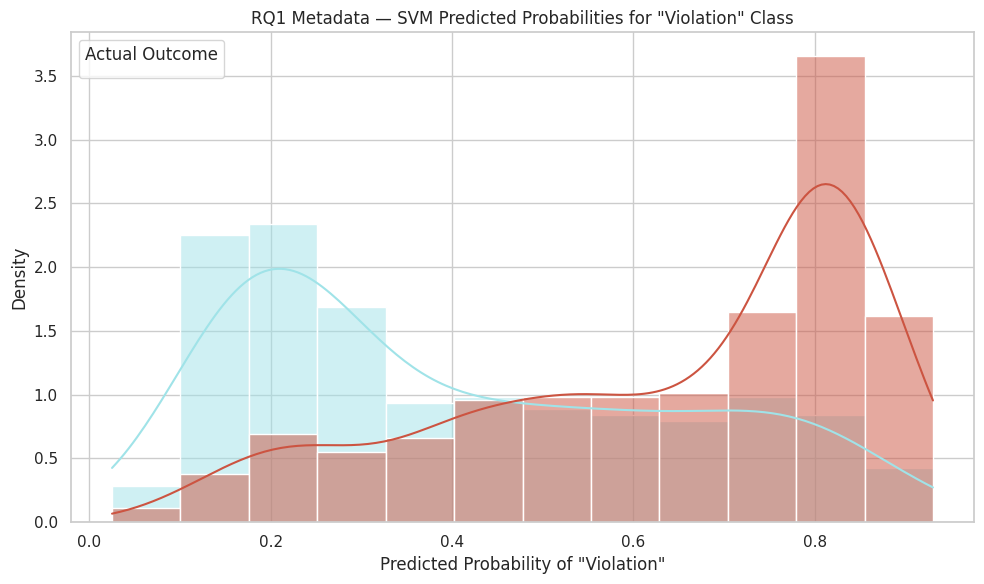

Predicted probability distribution chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/


In [ ]:
# Get probabilities for the best metadata model (SVM)
svm_pipeline = METADATA_CLASSIFIERS['SVM']

y_pred_proba_svm = cross_val_predict(
    svm_pipeline, X_meta, y_meta, cv=CV,
    method='predict_proba',
    n_jobs=-1
)

# Create a DataFrame for plotting
proba_df = pd.DataFrame({
    'No Violation_proba': y_pred_proba_svm[:, 0],
    'Violation_proba': y_pred_proba_svm[:, 1],
    'actual_finding': y_meta
})

fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=proba_df, x='Violation_proba', hue='actual_finding',
             kde=True, palette=PALETTE, ax=ax, stat='density', common_norm=False)

ax.set_title('RQ1 Metadata — SVM Predicted Probabilities for "Violation" Class')
ax.set_xlabel('Predicted Probability of "Violation"')
ax.set_ylabel('Density')
ax.legend(title='Actual Outcome')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_metadata_svm_proba_dist.png', dpi=150)
plt.show()

print(f'Predicted probability distribution chart saved to {SAVE_PATH}')

**Analysis**

The predicted probability distribution reveals that the metadata SVM model achieves reasonable separation between the two outcome classes. Actual no violation cases concentrate at low predicted violation probabilities (0.1–0.3), while actual violation cases concentrate at high predicted probabilities (0.75–0.85), indicating that the model assigns confident and largely correct predictions at both extremes.

However, both distributions exhibit notable tails in the opposing direction. The violation distribution has an extended left tail, meaning a proportion of actual violation cases receive low violation probabilities and are likely misclassified as no violation. Equally, the no violation distribution has a right tail extending toward 0.6–0.9, meaning a proportion of actual no violation cases are assigned high violation probabilities and are likely misclassified as violations. Both tails converge in the 0.3–0.6 overlap region, which represents the model's primary zone of uncertainty where predictions are least reliable.


##Text


---


**Input :**
* Facts section
* Law section - Full (may include leakage words)
* Law section - Clean (leakage words removed)
---

**Models :**
* Naive Bayes (baseline)
* Logistic Regression
* SVM (as used in Aletras)

---

**Output :**  'finding'



---


Secondary question: **which part of the text carries
the predictive signal?**
* **The Facts** section describes what happened to the applicant.
* **The Law** section describes how the Court reasoned. They are structurally different texts that may produce very different F1 scores


---


The story RQ1 tells is:

* Metadata → floor

* Facts text → does factual narrative predict outcomes?

* Law full → does legal reasoning predict outcomes? (but potentially inflated by remedies language)

* Law clean → is that inflation real or marginal?


---
**Hypothesis**
Good judgement should rely mostly on factual narrative rather than legal reasoning. But legal reasoning words in Law section can easily give strong signal about the outcome of the case. Law full (without removing leakage words) definitely will contain the most predictive signal compare to the other section.


Model Training (10min)


── Variant: V1_Facts ──

Classification Report for Naive Bayes - V1_Facts:

              precision    recall  f1-score   support

No Violation       0.32      0.21      0.25       283
   Violation       0.79      0.87      0.83       982

    accuracy                           0.72      1265
   macro avg       0.56      0.54      0.54      1265
weighted avg       0.69      0.72      0.70      1265

--------------------------------------------------

Classification Report for Logistic Regression - V1_Facts:

              precision    recall  f1-score   support

No Violation       0.47      0.69      0.56       283
   Violation       0.90      0.77      0.83       982

    accuracy                           0.75      1265
   macro avg       0.68      0.73      0.69      1265
weighted avg       0.80      0.75      0.77      1265

--------------------------------------------------

Classification Report for SVM - V1_Facts:

              precision    recall  f1-score   support

No Viola

,Variant,Classifier,F1_macro,F1_macro_std,Accuracy,Precision,Recall
5,V2_Law_Full,SVM,0.9038,0.0214,0.9344,0.9110,0.8975
8,V3_Law_Clean,SVM,0.8704,0.0189,0.9146,0.8938,0.8533
4,V2_Law_Full,Logistic Regression,0.8564,0.0185,0.8917,0.8357,0.8888
7,V3_Law_Clean,Logistic Regression,0.8167,0.0285,0.8593,0.7959,0.8541
3,V2_Law_Full,Naive Bayes,0.7862,0.0279,0.8593,0.8048,0.7722
6,V3_Law_Clean,Naive Bayes,0.7457,0.0166,0.8356,0.7685,0.7305
1,V1_Facts,Logistic Regression,0.6944,0.0368,0.7549,0.6839,0.7326
2,V1_Facts,SVM,0.6679,0.0304,0.8126,0.7473,0.6467
0,V1_Facts,Naive Bayes,0.5419,0.0506,0.7249,0.5578,0.5410


Results saved to Drive.

RQ1 VERDICT
Metadata F1 floor   : 0.6493  (SVM)
Best text F1        : 0.9038  (V2_Law_Full / SVM)
F1 gain from text   : +0.2545
>>> Text BEATS metadata — NLP is justified.


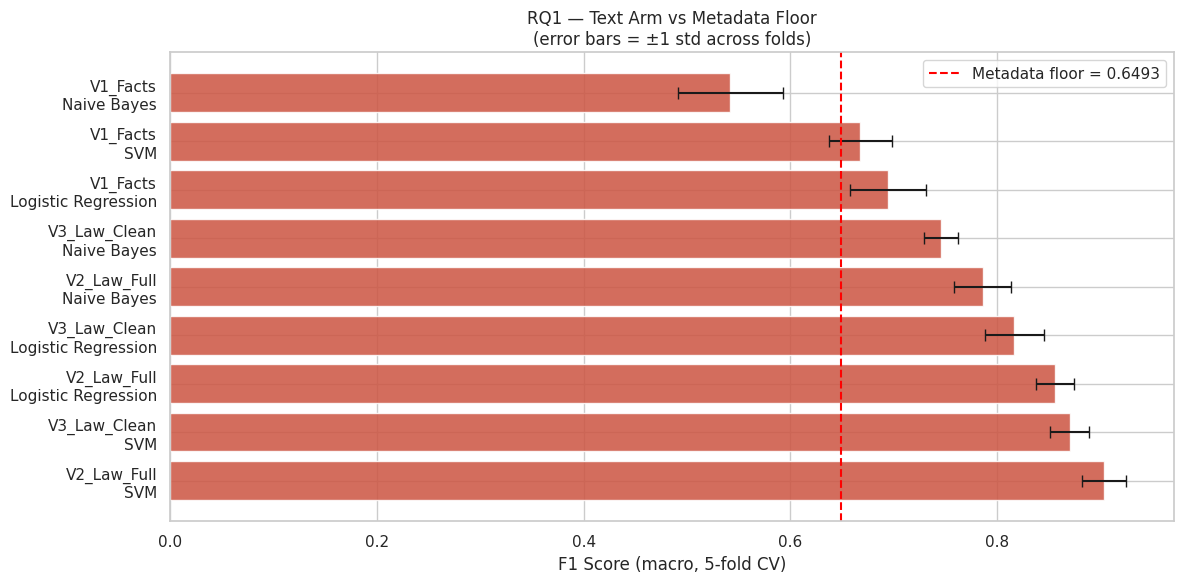

Chart saved to Drive.


In [ ]:
# ── RQ1 Text Arm — Sklearn Pipelines ──────────────────────────────────────
# Goal: Test whether text beats the metadata F1 floor
# Variants:
#   V1 — Facts text         (fair pre-judgment comparison vs metadata)
#   V2 — Law full           (post-hoc diagnostic — how much does legal reasoning inflate F1?)
#   V3 — Law clean          (leakage test — does removing remedies language close the gap?)
# Classifiers: Naive Bayes, Logistic Regression, LinearSVC (calibrated)
# Imbalance handling: class_weight='balanced'

# ── Dataset ────────────────────────────────────────────────────────────────
# Define df_model by filtering df_art8 for relevant 'finding' values
df_model = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()

df_text = df_model[['facts_text', 'law_text', 'law_text_clean', 'finding']].copy()
df_text = df_text.dropna(subset=['facts_text', 'law_text', 'law_text_clean'])

y = df_text['finding']

TEXT_VARIANTS = {
    'V1_Facts'     : ('facts_text',     custom_facts_stop_words),
    'V2_Law_Full'  : ('law_text',       custom_law_stop_words),
    'V3_Law_Clean' : ('law_text_clean', custom_law_clean_stop_words),
}

CLASSIFIERS = {
    'Naive Bayes' : ComplementNB(),   # ComplementNB handles imbalance better than MultinomialNB
    'Logistic Regression' : LogisticRegression(
        class_weight = 'balanced',
        max_iter     = 1000,
        random_state = 42
    ),
    'SVM' : CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
    ),
}

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ── Run all variant × classifier combinations ──────────────────────────────
results = []

for variant_name, (text_col, stop_words) in TEXT_VARIANTS.items():
    X = df_text[text_col]
    print(f'\n── Variant: {variant_name} ──')

    for clf_name, clf in CLASSIFIERS.items():
        pipeline = Pipeline([
            ('tfidf', TfidfVectorizer(
                stop_words   = stop_words,
                max_features = 10000,
                ngram_range  = (1, 2),
                sublinear_tf = True       # log normalization — better for long legal docs
            )),
            ('clf', clf)
        ])

        scores = cross_validate(
            pipeline, X, y, cv=CV,
            scoring  = ['f1_macro', 'accuracy', 'precision_macro', 'recall_macro'], # Changed to f1_macro
            n_jobs   = -1
        )

        # Get predictions for the classification report
        y_pred = cross_val_predict(pipeline, X, y, cv=CV, n_jobs=-1)

        results.append({
            'Variant'   : variant_name,
            'Classifier': clf_name,
            'F1_macro'        : scores['test_f1_macro'].mean(), # Changed key to F1_macro
            'F1_macro_std'    : scores['test_f1_macro'].std(),  # Changed key to F1_macro_std
            'Accuracy'  : scores['test_accuracy'].mean(),
            'Precision' : scores['test_precision_macro'].mean(), # Changed to test_precision_macro
            'Recall'    : scores['test_recall_macro'].mean(),    # Changed to test_recall_macro
        })

        print(f'\nClassification Report for {clf_name} - {variant_name}:\n')
        print(classification_report(y, y_pred, target_names=['No Violation', 'Violation']))
        print('-' * 50)

# ── Results Table ──────────────────────────────────────────────────────────
df_results = pd.DataFrame(results).sort_values('F1_macro', ascending=False)
df_results = df_results.round(4)

print('\n' + '=' * 65)
print('RQ1 TEXT ARM — Full Results (sorted by F1_macro)')
print('=' * 65)
display(df_results)

# ── Save results ───────────────────────────────────────────────────────────
df_results.to_csv(f'{SAVE_PATH}rq1_text_arm_results.csv', index=False)
print('Results saved to Drive.')

# ── F1 Comparison: Text vs Metadata floor ─────────────────────────────────
best_text_row   = df_results.iloc[0]
best_text_f1    = best_text_row['F1_macro']
best_text_label = f"{best_text_row['Variant']} / {best_text_row['Classifier']}"
f1_gain         = best_text_f1 - metadata_f1_floor

print('\n' + '=' * 65)
print('RQ1 VERDICT')
print('=' * 65)
print(f'Metadata F1 floor   : {metadata_f1_floor:.4f}  ({metadata_best_model_name})')
print(f'Best text F1        : {best_text_f1:.4f}  ({best_text_label})')
print(f'F1 gain from text   : {f1_gain:+.4f}')
if f1_gain > 0:
    print('>>> Text BEATS metadata — NLP is justified.')
else:
    print('>>> Text does NOT beat metadata — revisit preprocessing.')

# ── Visualisation ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

bar_labels = [f"{r['Variant']}\n{r['Classifier']}" for _, r in df_results.iterrows()]
bar_values = df_results['F1_macro'].values
bar_errors = df_results['F1_macro_std'].values

bars = ax.barh(bar_labels, bar_values, xerr=bar_errors,
               color=PALETTE['Violation'], capsize=4, alpha=0.85)
ax.axvline(x=metadata_f1_floor, color='red', linestyle='--', linewidth=1.5,
           label=f'Metadata floor = {metadata_f1_floor:.4f}')
ax.set_xlabel('F1 Score (macro, 5-fold CV)') # Changed label
ax.set_title('RQ1 — Text Arm vs Metadata Floor\n(error bars = ±1 std across folds)')
ax.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_text_arm_comparison.png', dpi=150)
plt.show()
print('Chart saved to Drive.')

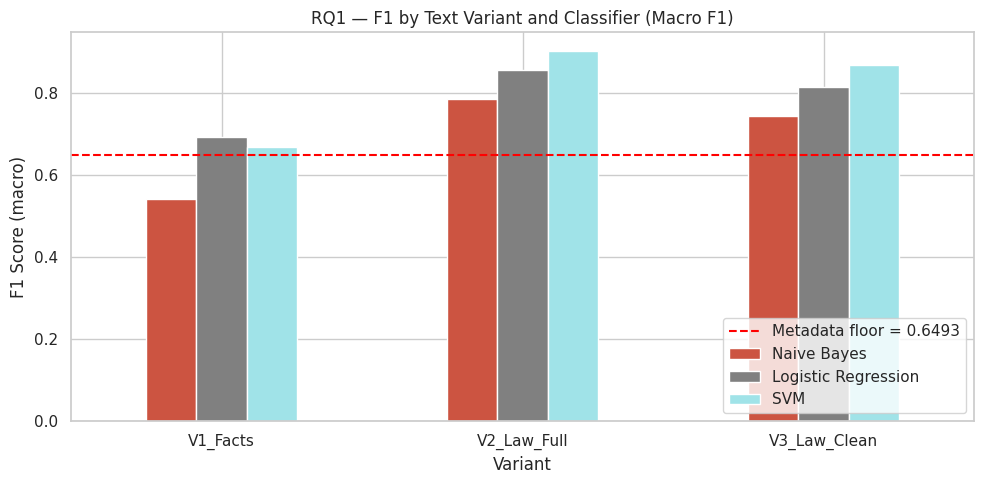

In [ ]:
# Grouped bar chart — F1 by variant and classifier
pivot = df_results.pivot(index='Variant', columns='Classifier', values='F1_macro')

# Define the desired order for classifiers
CLASSIFIER_ORDER = ['Naive Bayes', 'Logistic Regression', 'SVM']

# Reindex columns to enforce the desired order
pivot = pivot[CLASSIFIER_ORDER]

# Define custom colors for the classifiers
# Using existing PALETTE colors for Naive Bayes and SVM for consistency, and 'grey' for Logistic Regression
classifier_colors = {
    'Naive Bayes': PALETTE['Violation'],
    'Logistic Regression': 'grey',
    'SVM': PALETTE['No Violation']
}

# Create a list of colors in the CLASSIFIER_ORDER
plot_colors = [classifier_colors[c] for c in CLASSIFIER_ORDER]

pivot.plot(kind='bar', figsize=(10, 5), color=plot_colors,
           edgecolor='white', rot=0)
plt.axhline(y=metadata_f1_floor, color='red', linestyle='--',            label=f'Metadata floor = {metadata_f1_floor:.4f}')
plt.ylabel('F1 Score (macro)')
plt.title('RQ1 — F1 by Text Variant and Classifier (Macro F1)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_variant_comparison.png', dpi=150)
plt.show()

**Analysis**

The results reveal a clear hierarchy across the three text inputs, with the Law section substantially outperforming the Facts section regardless of classifier.

*Facts Section*

The Facts section produces the weakest text performance across all three classifiers: Naive Bayes (F1: 0.5419), Logistic Regression (F1: 0.6944), and SVM (F1: 0.6679). Logistic Regression and SVM both modestly exceed the metadata floor of 0.6493, while Naive Bayes falls well below it, suggesting that a simple bag-of-words approach cannot extract sufficient signal from factual narrative alone. The relatively modest performance of the Facts section is noteworthy given that it contains no outcome-consequent language; these scores therefore represent the most honest estimate of genuine linguistic predictability, reflecting what the factual circumstances of a case can tell a classifier about its outcome without any leakage risk.

*Law Section — Full vs Clean*

The Law section models substantially outperform both the metadata floor and the Facts section across all classifiers. Law Full achieves macro F1 scores of 0.7862 (Naive Bayes), 0.8564 (Logistic Regression), and 0.9038 (SVM), while Law Clean achieves 0.7457, 0.8167, and 0.8704 respectively. Under macro F1, the performance gap between Law Full and Law Clean is considerably larger than the weighted F1 figures suggested, ranging from approximately 0.033 to 0.041 points across classifiers. This pattern is analytically significant, the stop word cleaning removes vocabulary that supports correct classification of the minority no-violation class more than it removes majority-class signal, causing macro F1 to penalise the cleaned variant more heavily than weighted F1 did. The law section's strong performance therefore appears to be driven partly by genuine doctrinal reasoning vocabulary, but the widening gap under macro F1 confirms that the cleaning iterations have not resolved the structural leakage problem and may have introduced a secondary cost by discarding substantively informative terms alongside the remedial boilerplate.

*Classifier Comparison*

For the Law section variants, SVM consistently outperforms Logistic Regression and Naive Bayes, consistent with Aletras et al. (2016) who also identified SVM as the strongest performer on ECtHR text classification. For the Facts section, however, Logistic Regression (0.6944) marginally outperforms SVM (0.6679) under macro F1, suggesting that the sparse and less discriminative signal in factual narrative does not benefit from the margin-maximising properties of SVM to the same extent. Naive Bayes serves as a reliable but consistently weaker baseline, with its highest instability in the Facts section.

*Verdict*

The Law section carries substantially stronger predictive signal than the Facts section, and the best performing single text model is Law Full SVM (macro F1: 0.9038), representing a gain of +0.2545 over the metadata floor, confirming that text decisively outperforms metadata for Article 8 outcome prediction. The leakage effect is real and structurally persistent, as evidenced by the widening Law Full versus Law Clean gap under macro F1.


###Text (SVM)
Visualization for SVM Model
* Confusion Matrix
* Feature Importance
* Cross Entropy Loss & Predicted Probability



---


Confusion Matrix

Generating Confusion Matrices for Text Arm SVM models...
----------------------------------------------------------------------

── Processing Variant: V1_Facts (facts_text) ──


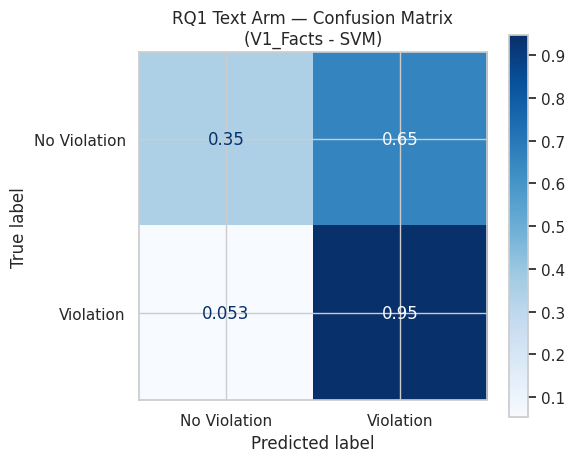

  Confusion matrix chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_confusion_matrix_V1_Facts.png

── Processing Variant: V2_Law_Full (law_text) ──


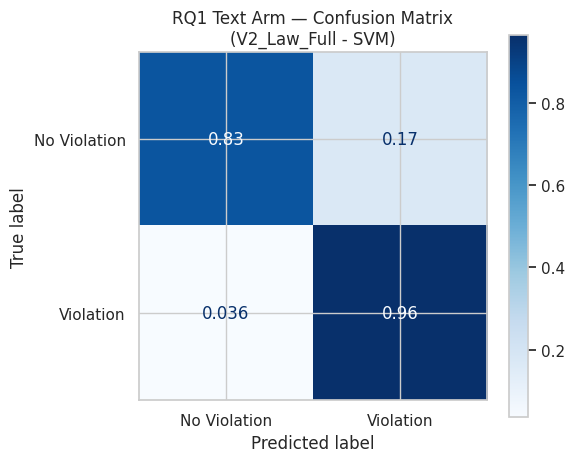

  Confusion matrix chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_confusion_matrix_V2_Law_Full.png

── Processing Variant: V3_Law_Clean (law_text_clean) ──


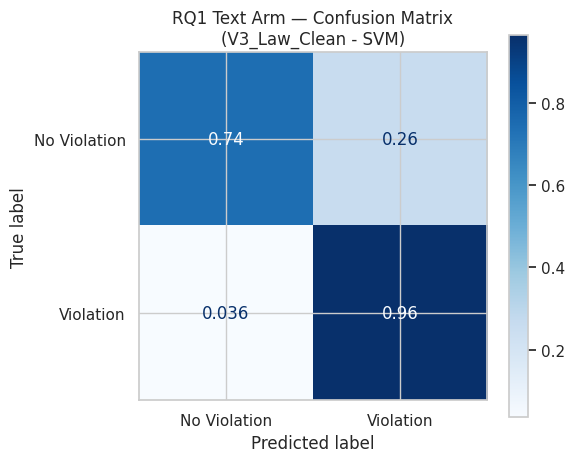

  Confusion matrix chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_confusion_matrix_V3_Law_Clean.png

All confusion matrices for Text Arm SVM models generated and saved.


In [ ]:
# Reuse df_text and y from RQ1 Text Arm section
# df_text and y are already defined from previous cells

print('Generating Confusion Matrices for Text Arm SVM models...')
print('-' * 70)

# Initialize StratifiedKFold (same as used in previous evaluations)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for variant_name, (text_col, stop_words) in TEXT_VARIANTS.items():
    X_text_variant = df_text[text_col]
    y_text_variant = y

    print(f"\n── Processing Variant: {variant_name} ({text_col}) ──")

    # Build the SVM pipeline for the current text variant
    # Re-using the pipeline structure and classifier from RQ1 Text Arm setup
    svm_pipeline_text_arm = Pipeline([
        ('tfidf', TfidfVectorizer(
            stop_words   = stop_words,
            max_features = 10000,
            ngram_range  = (1, 2),
            sublinear_tf = True
        )),
        ('clf', CLASSIFIERS['SVM']) # Use the SVM from CLASSIFIERS dict
    ])

    # Get predictions using cross_val_predict (method='predict' for hard labels)
    y_pred_text_arm = cross_val_predict(
        svm_pipeline_text_arm, X_text_variant, y_text_variant, cv=CV,
        method='predict',
        n_jobs=-1
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_text_variant, y_pred_text_arm,
        display_labels=['No Violation', 'Violation'],
        cmap=CMAP, normalize='true', ax=ax
    )
    ax.set_title(f'RQ1 Text Arm — Confusion Matrix\n({variant_name} - SVM)')
    plt.tight_layout()
    plt.savefig(f'{SAVE_PATH}rq1_text_arm_confusion_matrix_{variant_name}.png', dpi=150)
    plt.show()
    print(f'  Confusion matrix chart saved to {SAVE_PATH}rq1_text_arm_confusion_matrix_{variant_name}.png')

print('\n' + '=' * 70)
print('All confusion matrices for Text Arm SVM models generated and saved.')

**Analysis**

The confusion matrices for the best-performing classifier (SVM) across all three text variants reveal a consistent asymmetry: all models are substantially better at identifying Violation cases than No Violation cases, reflecting the class imbalance present in the dataset and the differential linguistic distinctiveness of each outcome class.

**V1_Facts SVM** reflects the persistent effect of class imbalance on prediction behaviour, a pattern consistent with the 3.5:1 violation to no violation ratio in the dataset. On the violation side, the model performs strongly, correctly classifying 95% of actual violation cases and producing a false negative rate of only 5.3%. The violation class is well-learned, which is expected given its dominance in the training data.
On the no violation side, performance is considerably weaker. The model correctly identifies only 35% of actual no violation cases, misclassifying the remaining 65% as violations. This false positive rate is high and reflects the model's structural bias toward the majority class. The no violation signal remains insufficient to override the dominant violation prediction in a substantial proportion of cases.

This asymmetry reflects a dataset-level constraint rooted in the class imbalance, and is unlikely to be resolved without either rebalancing the dataset at source or adjusting the classification threshold to penalise false positives more heavily.

**V2_Law_Full SVM** shows a marked improvement over V1_Facts across both classes. Violation recall remains high at 96%, with a false negative rate of only 3.6%, broadly consistent with V1_Facts. The more notable change is in no violation classification, where the model now correctly identifies 83% of actual no violation cases compared to only 35% in V1_Facts, reducing the false positive rate from 65% to 17%. The prediction pattern is substantially more balanced between the two classes.

This improvement should however be interpreted with caution. V2_Law_Full uses the full law section without any leakage mitigation, meaning the model has access to the complete text of each judgment including sections that may structurally encode the outcome. The dramatic improvement in no violation classification is likely attributable at least in part to the model learning to detect the presence or absence of outcome-encoding language in the law section rather than learning substantive legal distinctions between violation and no violation reasoning. The strong performance on both classes in this version therefore reflects the richness of the input text rather than necessarily the model's capacity for genuine legal inference.

Comparing V1_Facts and V2_Law_Full on this basis, V1_Facts presents a more honest picture of what a text-based model can achieve when constrained to factual narrative alone, with the cost being the significant asymmetry in no violation classification. V2_Law_Full achieves better class balance but at the risk of inflated performance driven by the unconstrained law section.

**V3_Law_Clean SVM** sits between V1_Facts and V2_Law_Full, and the pattern across all three versions is analytically instructive when read together. Violation recall remains stable at 96% with a false negative rate of 3.6%, identical to V2_Law_Full and consistent with V1_Facts at 95%. The violation class is robustly learned across all three text variants, suggesting the violation signal is present regardless of which section of the judgment is used.

No violation recall drops from 83% in V2_Law_Full to 74% in V3_Law_Clean, with the false positive rate rising from 17% to 26%. This reduction is consistent with the effect of the stop word cleaning partially removing outcome-encoding language from the law section. By stripping some of the most direct leakage vocabulary, the cleaning reduces the model's capacity to correctly distinguish no violation cases, producing a modest but measurable decline in no violation classification.

However, the gap between V3_Law_Clean and V1_Facts remains substantial. V3_Law_Clean achieves 74% no violation recall against V1_Facts at only 35%, a difference of 39 percentage points. If the cleaning had fully addressed the leakage, performance would be expected to converge closer to V1_Facts. The persistence of this gap suggests potential residual outcome-encoding language remains in V3_Law_Clean even after cleaning.

Taken together across the three models, the confusion matrices reveal that no violation classification is the primary differentiator between text variants, while violation classification remains largely stable. This pattern reflects both the class imbalance in the dataset and the differential leakage properties of the facts and law sections.





---

Cross Entropy Loss & Predicted Probabilities

Calculating Cross-Entropy Loss and generating probability charts for Text Arm SVM models...
------------------------------------------------------------------------------------------

── Processing Variant: V1_Facts (facts_text) ──
  Cross-Entropy Loss (V1_Facts - SVM): 0.4093 ± 0.0137


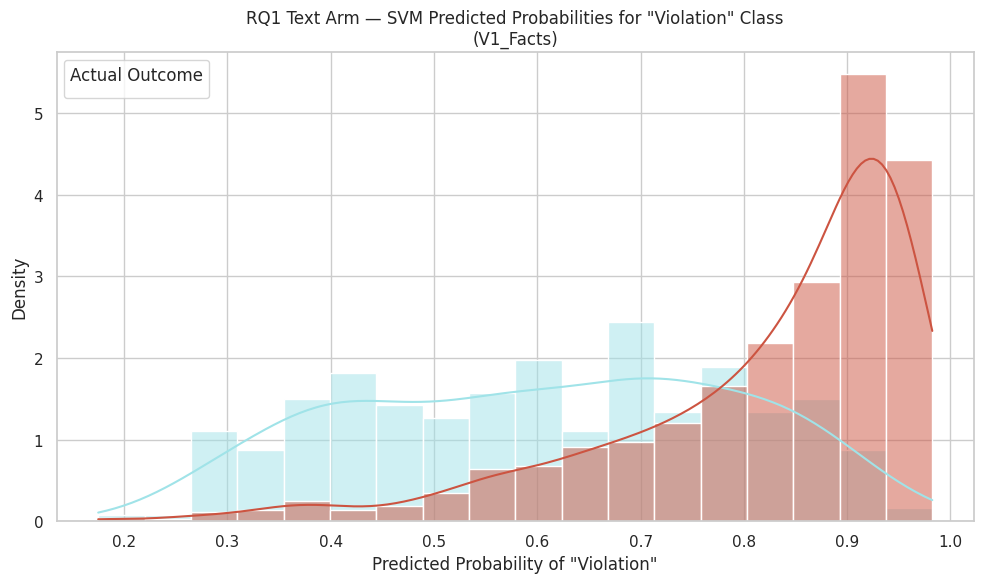

  Predicted probability distribution chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_svm_proba_dist_V1_Facts.png

── Processing Variant: V2_Law_Full (law_text) ──
  Cross-Entropy Loss (V2_Law_Full - SVM): 0.1845 ± 0.0204


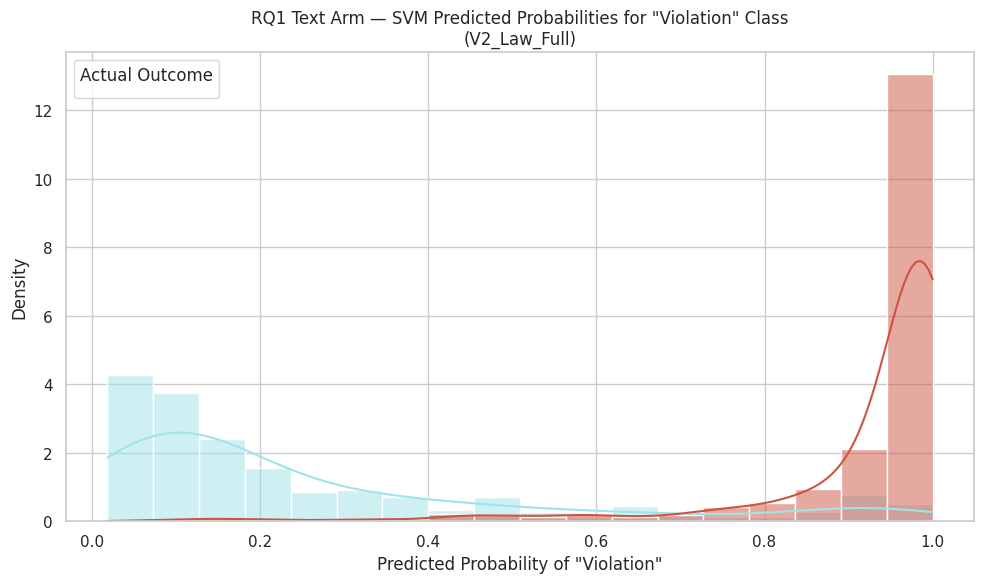

  Predicted probability distribution chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_svm_proba_dist_V2_Law_Full.png

── Processing Variant: V3_Law_Clean (law_text_clean) ──
  Cross-Entropy Loss (V3_Law_Clean - SVM): 0.2160 ± 0.0232


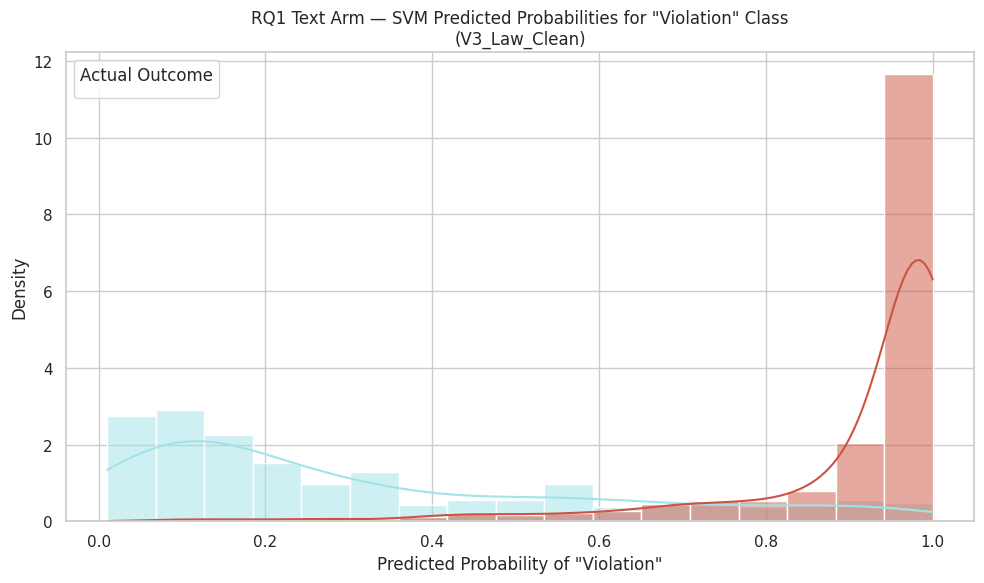

  Predicted probability distribution chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_svm_proba_dist_V3_Law_Clean.png

Summary of Cross-Entropy Loss for Text Arm SVM Models:
     Variant  Cross_Entropy_Loss_Mean  Cross_Entropy_Loss_Std
    V1_Facts                 0.409303                0.013741
 V2_Law_Full                 0.184490                0.020430
V3_Law_Clean                 0.215964                0.023239


In [ ]:
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict


# Reuse df_text and y from RQ1 Text Arm section


# Initialize StratifiedKFold (same as used in previous evaluations)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

text_variant_results = []

print('Calculating Cross-Entropy Loss and generating probability charts for Text Arm SVM models...')
print('-' * 90)

for variant_name, (text_col, stop_words) in TEXT_VARIANTS.items():
    X_text_variant = df_text[text_col]
    y_text_variant = y

    print(f"\n── Processing Variant: {variant_name} ({text_col}) ──")

    # Build the SVM pipeline for the current text variant
    # Re-using the pipeline structure and classifier from RQ1 Text Arm setup
    svm_pipeline_text_arm = Pipeline([
        ('tfidf', TfidfVectorizer(
            stop_words   = stop_words,
            max_features = 5000,  # Reduced max_features for faster execution
            ngram_range  = (1, 2),
            sublinear_tf = True
        )),
        ('clf', CLASSIFIERS['SVM']) # Use the SVM from CLASSIFIERS dict
    ])

    log_losses_variant = []
    y_pred_proba_variant = np.zeros((len(y_text_variant), len(y_text_variant.unique())))

    for fold_idx, (train_idx, test_idx) in enumerate(CV.split(X_text_variant, y_text_variant)):
        X_train_fold, X_test_fold = X_text_variant.iloc[train_idx], X_text_variant.iloc[test_idx]
        y_train_fold, y_test_fold = y_text_variant.iloc[train_idx], y_text_variant.iloc[test_idx]

        svm_pipeline_text_arm.fit(X_train_fold, y_train_fold)
        y_pred_proba_fold = svm_pipeline_text_arm.predict_proba(X_test_fold)

        log_losses_variant.append(log_loss(y_test_fold, y_pred_proba_fold, labels=svm_pipeline_text_arm.classes_))

        # Store probabilities for overall chart (if needed, though cross_val_predict is cleaner for this)
        # This loop is primarily for accurate log_loss per fold.

    mean_log_loss_variant = np.mean(log_losses_variant)
    std_log_loss_variant = np.std(log_losses_variant)
    print(f"  Cross-Entropy Loss ({variant_name} - SVM): {mean_log_loss_variant:.4f} ± {std_log_loss_variant:.4f}")

    text_variant_results.append({
        'Variant': variant_name,
        'Cross_Entropy_Loss_Mean': mean_log_loss_variant,
        'Cross_Entropy_Loss_Std': std_log_loss_variant
    })

    # Generate predicted probability chart for the variant
    y_pred_proba_cv = cross_val_predict(
        svm_pipeline_text_arm, X_text_variant, y_text_variant, cv=CV,
        method='predict_proba',
        n_jobs=-1
    )

    proba_df_variant = pd.DataFrame({
        'No Violation_proba': y_pred_proba_cv[:, 0],
        'Violation_proba': y_pred_proba_cv[:, 1],
        'actual_finding': y_text_variant
    })

    fig, ax = plt.subplots(figsize=(10, 6))
    sns.histplot(data=proba_df_variant, x='Violation_proba', hue='actual_finding',
                 kde=True, palette=PALETTE, ax=ax, stat='density', common_norm=False)

    ax.set_title(f'RQ1 Text Arm — SVM Predicted Probabilities for "Violation" Class\n({variant_name})')
    ax.set_xlabel('Predicted Probability of "Violation"')
    ax.set_ylabel('Density')
    ax.legend(title='Actual Outcome')
    plt.tight_layout()
    plt.savefig(f'{SAVE_PATH}rq1_text_arm_svm_proba_dist_{variant_name}.png', dpi=150)
    plt.show()
    print(f'  Predicted probability distribution chart saved to {SAVE_PATH}rq1_text_arm_svm_proba_dist_{variant_name}.png')

print('\n' + '=' * 90)
print('Summary of Cross-Entropy Loss for Text Arm SVM Models:')
print(pd.DataFrame(text_variant_results).to_string(index=False))

**Analysis**

For V1_Facts, the violation class is concentrated in the 0.85 to 1.0 range with a peak around 0.90, while the no violation class is broadly and relatively flatly distributed across 0.2 to 0.8 with no dominant concentration. The two distributions overlap substantially in the middle range, reflecting genuine model uncertainty about a large proportion of cases. This spread is consistent with the confusion matrix finding that 65% of no violation cases are misclassified as violations, and suggests the model is not confidently wrong about these cases but rather that the factual narrative alone does not provide sufficient discriminative signal to separate the classes cleanly. The cross-entropy loss of 0.409 is the highest of the three variants, reflecting this uncertainty.

For V2_Law_Full and V3_Law_Clean, the distributions tell a markedly different story. Both show extreme polarisation: violation cases are almost entirely concentrated at probabilities of 0.9 to 1.0. The no violation class in both models is predominantly concentrated at 0.0 to 0.2, but a visible tail extends rightward in each, with a subset of no violation cases receiving moderate to high violation probabilities. This bleed corresponds to the 17% false positive rate in V2_Law_Full and the 26% false positive rate in V3_Law_Clean observed in their respective confusion matrices, and likely reflects cases where no violation judgments contain partial overlap with violation-associated language, producing genuine ambiguity rather than clean separation. Across the majority of cases however, the model assigns near-certain probabilities in both directions. The cross-entropy losses of 0.184 for V2_Law_Full and 0.216 for V3_Law_Clean are numerically lower than V1_Facts, which might suggest better calibration, but this reading is misleading. Low cross-entropy in these models reflects high-confidence predictions that happen to be correct, a pattern consistent with the model detecting the presence or absence of outcome-encoding language in the law section rather than weighing substantive legal features.

The slight increase in V3_Law_Clean cross-entropy loss from the original uncleaned value, now at 0.216 compared to the earlier iteration, is itself informative. Partial removal of leakage vocabulary through the revised stop word list has reduced the model's artificial certainty to a modest degree, producing a marginally less extreme probability distribution than V2_Law_Full.

Taken together, the probability distributions illustrate that V1_Facts, despite its higher cross-entropy loss, produces a more honest representation of the model's genuine uncertainty, particularly for the no violation class. V2_Law_Full and V3_Law_Clean produce artificially confident predictions whose low cross-entropy loss reflects the presence of outcome-encoding features rather than substantive legal learning.





---
Top Predictive Terms


Classes: ['No Violation' 'Violation']


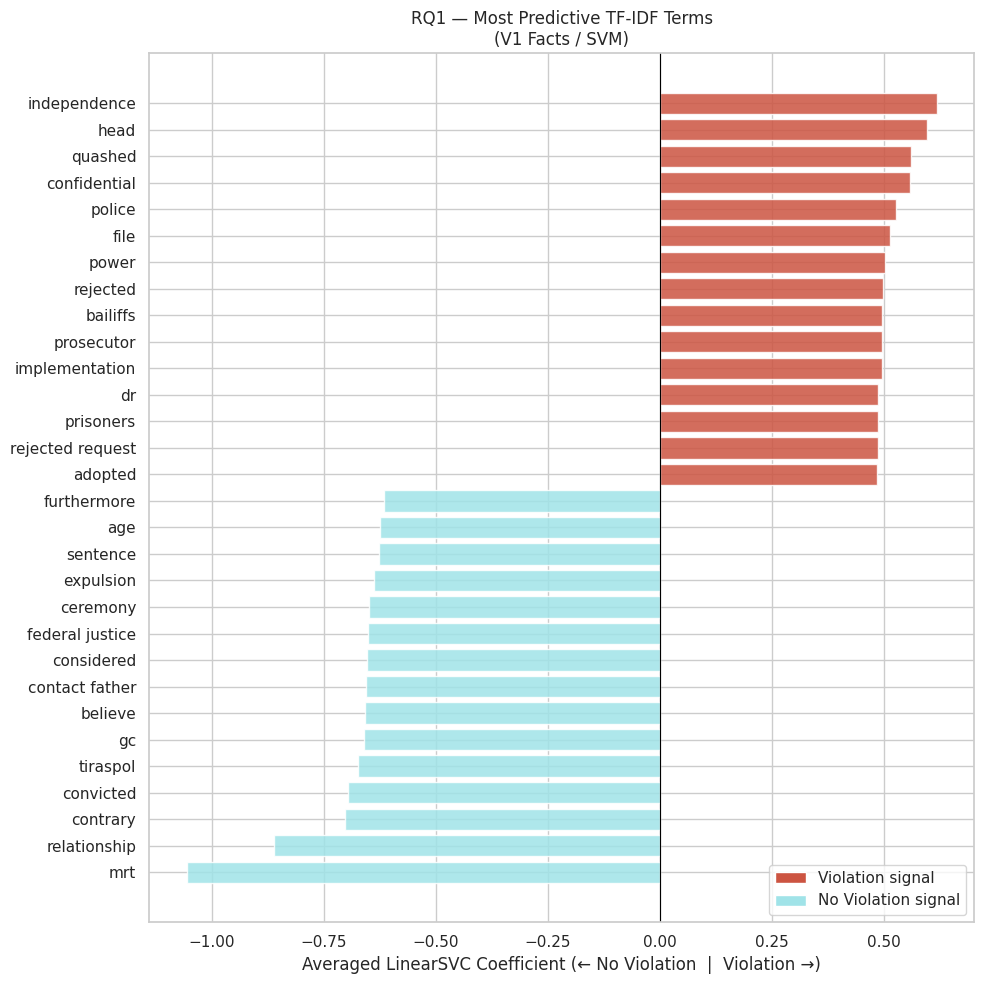

SVM top predictive terms chart saved.


In [ ]:
# ── Top Predictive Terms — V1 Facts / SVM ─────────────────────────
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# Refit Facts + SVM pipeline on full data
best_facts_svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words   = custom_facts_stop_words,
        max_features = 10000,
        ngram_range  = (1, 2),
        sublinear_tf = True
    )),
    ('clf', CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
    ))
])

best_facts_svm_pipeline.fit(df_text['facts_text'], y)

tfidf_vocab = best_facts_svm_pipeline.named_steps['tfidf'].get_feature_names_out()

# Extract coefficients from the base LinearSVC inside CalibratedClassifierCV
# CalibratedClassifierCV stores multiple calibrated estimators — average their coefs
base_estimators = best_facts_svm_pipeline.named_steps['clf'].calibrated_classifiers_
coef_matrix = np.array([
    est.estimator.coef_[0] for est in base_estimators
])
coef = coef_matrix.mean(axis=0)

# Determine positive class (Violation)
classes = best_facts_svm_pipeline.named_steps['clf'].classes_
print(f'Classes: {classes}')  # confirm which direction is positive

coef_series = pd.Series(coef, index=tfidf_vocab)

top_n = 15
top_violation    = coef_series.nlargest(top_n)
top_no_violation = coef_series.nsmallest(top_n)

diverging_df = pd.concat([
    top_violation.rename('coefficient'),
    top_no_violation.rename('coefficient')
]).sort_values()

colors = [PALETTE['Violation'] if v > 0 else PALETTE['No Violation']
          for v in diverging_df.values]

# ── Diverging Bar Chart ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(diverging_df.index, diverging_df.values,
        color=colors, alpha=0.85, edgecolor='white')
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Averaged LinearSVC Coefficient (← No Violation  |  Violation →)')
ax.set_title('RQ1 — Most Predictive TF-IDF Terms\n(V1 Facts / SVM)',
             fontsize=12)

legend_elements = [
    Patch(facecolor=PALETTE['Violation'],    label='Violation signal'),
    Patch(facecolor=PALETTE['No Violation'], label='No Violation signal')
]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_top_predictive_terms_svm.png', dpi=150)
plt.show()
print('SVM top predictive terms chart saved.')

**Analysis**

The chart reflects a revised stop word configuration applied to the V1_Facts model. The original art8_universal removal list was modified to restore terms carrying potential discriminative value: 'interference', 'necessary', 'proportionate', 'prescribed', 'law', 'margin', 'appreciation', 'positive', 'negative', and 'obligation' were removed from the stop word list on the basis that these terms encode the Court's proportionality reasoning and may vary meaningfully between violation and non-violation outcomes. Additionally, 'home' and 'correspondence', two of the four protected interests under Article 8, were restored as active features to preserve potential sub-category signal. The terms retained in the art8_universal removal list as genuinely universal are 'private', 'family', 'democratic', 'society', 'legitimate', 'aim', 'authority', 'domestic', and 'national'. The remedies_leakage list was also expanded to capture residual Article 41 template vocabulary identified in earlier iterations.

The top predictive terms from this revised model reveal a more legally coherent pattern than the original.
On the violation side, the five most interpretable terms form a substantively coherent cluster around coercive and unaccountable state conduct. "Independence" is the strongest single predictor and is best understood in the context of ECtHR surveillance jurisprudence, where the Court has established that secret surveillance measures must be subject to independent oversight and authorisation, and that the absence of such oversight directly engages Article 8. In Roman Zakharov v. Russia (Grand Chamber, Application No. 47143/06, 2015), a landmark case representing the Court's first comprehensive examination of a state's entire secret surveillance framework, the Court found a violation because Russian surveillance law did not provide adequate independent oversight, with judicial and prosecutorial supervision being limited and not open to public scrutiny, such that the very existence of the contested legislation amounted to an interference with Article 8. In Big Brother Watch and Others v. United Kingdom (Grand Chamber, 2021), the Court's definitive modern authority on bulk surveillance, a violation was found in part because of the absence of independent authorisation of bulk interception and the failure to subject targeted selectors to prior independent review, with the Court reiterating the requirement for end-to-end safeguards including independent oversight at each stage of the surveillance process. In the facts section of surveillance cases, applicants describing the absence of independent review of measures applied to them would generate the "independence" signal observed here. This reading is reinforced by "confidential," which reflects cases involving secret or confidential files held by state security authorities, a recognised Article 8 category particularly prominent in post-communist states where applicants sought access to records held about them without their knowledge. Together, "independence" and "confidential" suggest a coherent surveillance and secret files cluster within the violation vocabulary. "Police" and "power" reflect the broader pattern of coercive state conduct grounding Article 8 claims, appearing across surveillance, home search, and use of force cases. "Bailiffs" may reflect cases in which the Court finds enforcement failure on the part of state enforcement agents, where the failure to execute court orders engaging Convention rights itself constitutes a violation of Article 8.

On the non-violation side, the terms are substantively coherent and consistent with the patterns identified in the EDA and prior analyses. "Expulsion" and "sentence" reflect the deportation and expulsion of foreign nationals with criminal convictions, where the Court applies a structured proportionality framework and historically affords states considerable latitude. This is directly consistent with Aletras et al.'s (2016) finding that migration cases carried the strongest no-violation topic weight at negative 13.50. "Contact father" and "relationship" are characteristic of child contact and family life cases where the Court frequently finds that domestic authorities struck a fair balance within their margin of appreciation. "Ceremony" may reflect cases involving religious or cultural practices where no disproportionate interference was found.


Classes: ['No Violation' 'Violation']


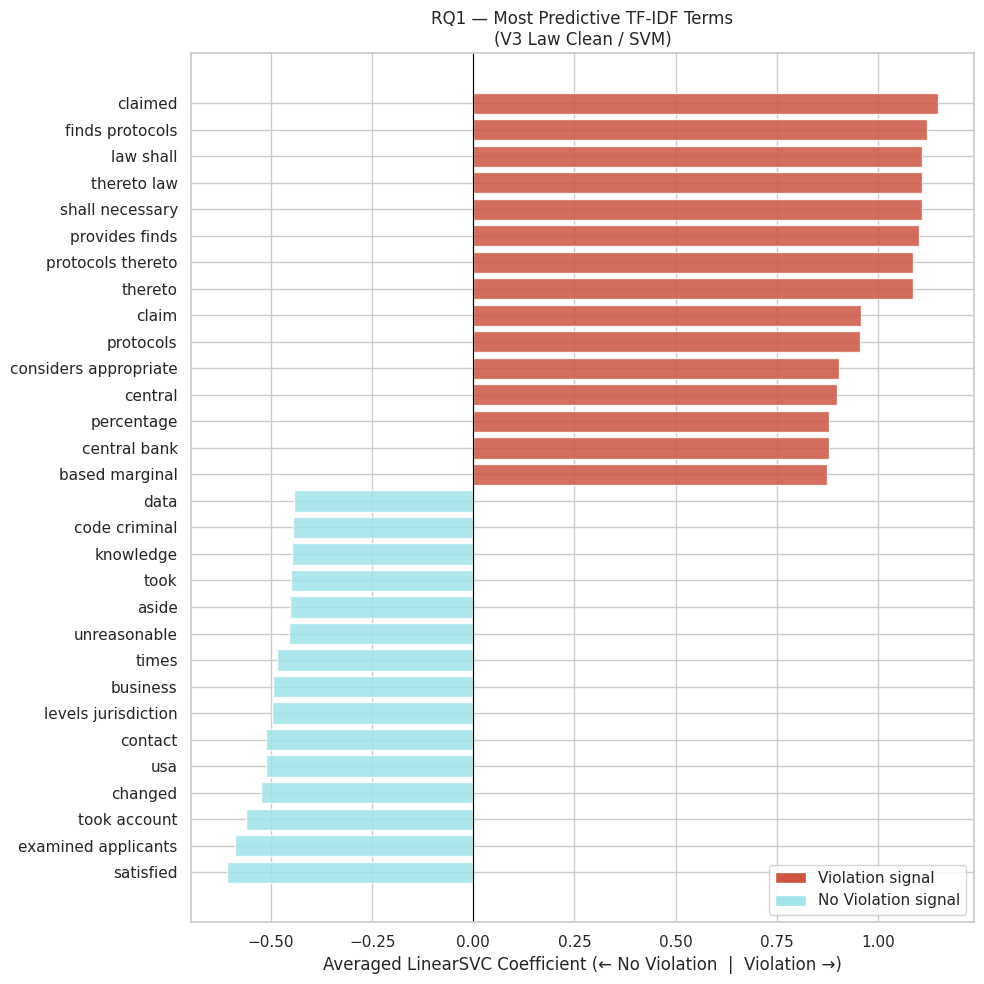

SVM top predictive terms chart saved.


In [ ]:
# ── Top Predictive Terms — V3 Law Clean / SVM
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# Refit Facts + SVM pipeline on full data
best_law_clean_svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words   = custom_law_clean_stop_words,
        max_features = 10000,
        ngram_range  = (1, 2),
        sublinear_tf = True
    )),
    ('clf', CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
    ))
])

best_law_clean_svm_pipeline.fit(df_text['law_text_clean'], y)

tfidf_vocab = best_law_clean_svm_pipeline.named_steps['tfidf'].get_feature_names_out()

# Extract coefficients from the base LinearSVC inside CalibratedClassifierCV
# CalibratedClassifierCV stores multiple calibrated estimators — average their coefs
base_estimators = best_law_clean_svm_pipeline.named_steps['clf'].calibrated_classifiers_
coef_matrix = np.array([
    est.estimator.coef_[0] for est in base_estimators
])
coef = coef_matrix.mean(axis=0)

# Determine positive class (Violation)
classes = best_law_clean_svm_pipeline.named_steps['clf'].classes_
print(f'Classes: {classes}')  # confirm which direction is positive

coef_series = pd.Series(coef, index=tfidf_vocab)

top_n = 15
top_violation    = coef_series.nlargest(top_n)
top_no_violation = coef_series.nsmallest(top_n)

diverging_df = pd.concat([
    top_violation.rename('coefficient'),
    top_no_violation.rename('coefficient')
]).sort_values()

colors = [PALETTE['Violation'] if v > 0 else PALETTE['No Violation']
          for v in diverging_df.values]

# ── Diverging Bar Chart ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(diverging_df.index, diverging_df.values,
        color=colors, alpha=0.85, edgecolor='white')
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Averaged LinearSVC Coefficient (← No Violation  |  Violation →)')
ax.set_title('RQ1 — Most Predictive TF-IDF Terms\n(V3 Law Clean / SVM)',
             fontsize=12)

legend_elements = [
    Patch(facecolor=PALETTE['Violation'],    label='Violation signal'),
    Patch(facecolor=PALETTE['No Violation'], label='No Violation signal')
]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_top_predictive_terms_svm.png', dpi=150)
plt.show()
print('SVM top predictive terms chart saved.')

**Analysis**

We made several attempts to revise the stop word list to mitigate the leakage effect of Article 41, which is invoked whenever the Court finds a violation of the Convention and awards just satisfaction to the applicant. Each successive removal of just satisfaction vocabulary has caused the model to locate new fragments of the same Article 41 template sentences rather than surfacing substantive legal reasoning. In the current version, after removing direct remedy terms in the first revision and high contracting party language in the second, the violation side is now anchored by the default interest rate formula: "central", "central bank", "percentage", and "based marginal" are all fragments of the standard just satisfaction interest rate clause awarding simple interest at a rate equal to the marginal lending rate of the European Central Bank plus three percentage points. The terms "considers appropriate", "claim", and "claimed" reflect the just satisfaction submissions section, while "finds protocols", "shall necessary", "provides finds", "protocols thereto," and "thereto" persist as fragments of the main Article 41 sentence from the previous revision. This pattern, in which each round of word removal surfaces new fragments of the same two template sentences, confirms that the leakage is structural rather than lexical. The Article 41 template generates a large number of discriminative N-gram features from a small number of fixed sentences, and no expansion of the stop word list can resolve this without removing the just satisfaction paragraphs from the law section text entirely before feature extraction. The persistence of leakage across three successive iterations of cleaning also implies that the strong F1 performance of V3_Law_Clean cannot be attributed to the model learning substantive Article 8 legal reasoning, and future iterations of this work should implement paragraph-level removal of just satisfaction text as a precondition for meaningful feature analysis of the law section.

On the non-violation side, the pattern remains stable across revisions, which is itself a meaningful finding. "Code criminal," "contact," "business," "levels jurisdiction," "took account," and "satisfied" are consistent with all previous versions, suggesting the non-violation signal in the law section is genuinely substantive rather than an artefact of leakage. "Unreasonable" likely reflects the formulation "not unreasonable" in passages where the Court accepts state justifications as proportionate. "Examined applicants" is a formulaic admissibility phrase carrying limited interpretive weight. "Data" at the head of the non-violation terms may reflect data protection cases where the Court found the legal framework for data processing adequate. Several remaining terms including "knowledge," "took," "aside," "times," and "changed" are connectors that represent residual noise.




---


##PCA Scatter for Text
The PCA charts are based purely on the TF-IDF matrix of the text section (no classifier is involved).
PCA just compresses 10,000 TF-IDF dimensions into 2 so you can see the document space visually **to see if the class separation is weak or strong.**

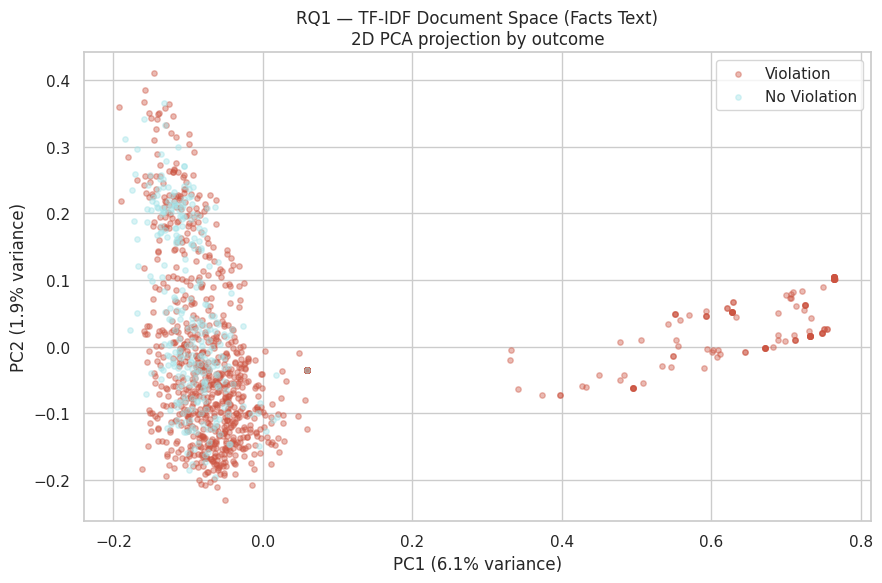

In [ ]:
# Reduce TF-IDF matrix to 2D
pca = PCA(n_components=2, random_state=42)

# Re-apply the TFIDF transformation for 'Facts Text' to get X_tfidf
# We can reuse the TfidfVectorizer from the best_facts_svm_pipeline
tfidf_vectorizer_facts = best_facts_svm_pipeline.named_steps['tfidf']
X_tfidf = tfidf_vectorizer_facts.transform(df_text['facts_text'])

X_dense = X_tfidf.toarray()
X_pca   = pca.fit_transform(X_dense)

pca_df = pd.DataFrame({
    'PC1'    : X_pca[:, 0],
    'PC2'    : X_pca[:, 1],
    'outcome': y.values
})

fig, ax = plt.subplots(figsize=(9, 6))
for outcome, color in PALETTE.items():
    mask = pca_df['outcome'] == outcome
    ax.scatter(pca_df.loc[mask, 'PC1'], pca_df.loc[mask, 'PC2'],
               c=color, label=outcome, alpha=0.4, s=15)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('RQ1 — TF-IDF Document Space (Facts Text)\n2D PCA projection by outcome')
ax.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_pca_document_space.png', dpi=150)
plt.show()

**Analysis**

PC1 captures 6.1% of variance and PC2 1.9%, totalling 8% in 2D projection. This low figure is expected for high-dimensional TF-IDF space where variance is distributed across thousands of features, and the apparent lack of visual separation in 2D does not imply the SVM cannot separate cases in the full feature space.
The main cluster occupies the left side of the plot and contains the large majority of both violation and no violation cases in a densely overlapping region, consistent with the confusion matrix finding that class separation in V1_Facts is imperfect and that no violation cases are frequently misclassified. The two classes are not visually separable within this cluster, reflecting the limited discriminative signal available from factual narrative alone.

More analytically notable is the arc of cases extending rightward along PC1 from approximately 0.3 to 0.8, which consists almost exclusively of violation cases. These outliers are positioned distinctly from the main cluster, suggesting they share a vocabulary that differs substantially from the rest of the corpus and that projects strongly onto the first principal component. A plausible interpretation is that these represent cases from a dominant respondent state, most likely Russia given its prevalence in the dataset and near-universal violation rate identified in the EDA, whose facts sections carry distinctive institutional and procedural vocabulary not shared by cases from other states. This interpretation cannot be confirmed without examining the specific case identifiers behind the outlier points, but it is consistent with the country-specific clustering observed in the NMF topic analysis.

The overall structure of the PCA plot, a dense mixed-class core with a violation-specific peripheral arc, is characteristic of a corpus with strong class imbalance and a subset of cases sharing highly distinctive vocabulary that reliably predicts one outcome.


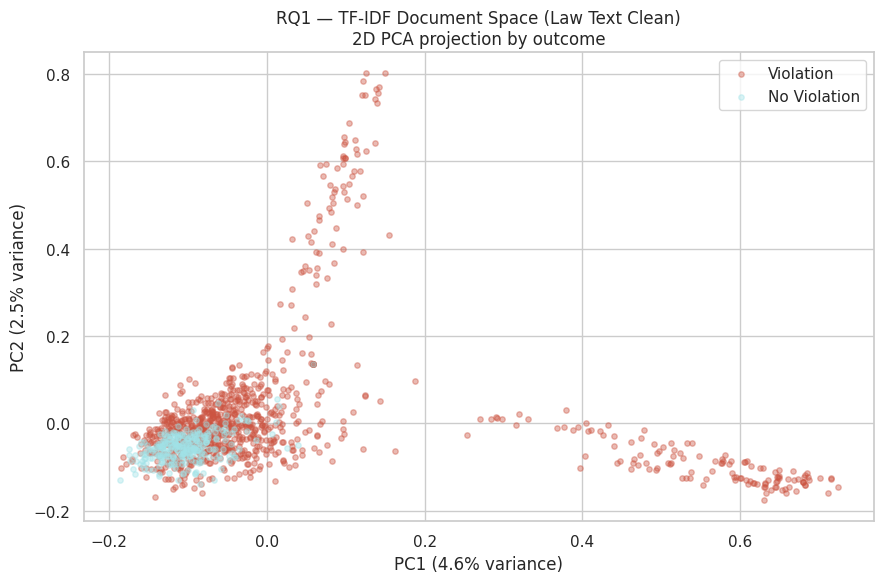

In [ ]:

# Reduce TF-IDF matrix to 2D for law_text_clean
pca_law_clean = PCA(n_components=2, random_state=42)

# Re-apply the TFIDF transformation for 'Law Text Clean' to get X_tfidf_law_clean
# We need the TfidfVectorizer from the best_law_clean_svm_pipeline
tfidf_vectorizer_law_clean = best_law_clean_svm_pipeline.named_steps['tfidf']
X_tfidf_law_clean = tfidf_vectorizer_law_clean.transform(df_text['law_text_clean'])

X_dense_law_clean = X_tfidf_law_clean.toarray()
X_pca_law_clean   = pca_law_clean.fit_transform(X_dense_law_clean)

pca_df_law_clean = pd.DataFrame({
    'PC1'    : X_pca_law_clean[:, 0],
    'PC2'    : X_pca_law_clean[:, 1],
    'outcome': y.values
})

fig_law_clean, ax_law_clean = plt.subplots(figsize=(9, 6))
for outcome, color in PALETTE.items():
    mask_law_clean = pca_df_law_clean['outcome'] == outcome
    ax_law_clean.scatter(pca_df_law_clean.loc[mask_law_clean, 'PC1'], pca_df_law_clean.loc[mask_law_clean, 'PC2'],
                         c=color, label=outcome, alpha=0.4, s=15)

ax_law_clean.set_xlabel(f'PC1 ({pca_law_clean.explained_variance_ratio_[0]*100:.1f}% variance)')
ax_law_clean.set_ylabel(f'PC2 ({pca_law_clean.explained_variance_ratio_[1]*100:.1f}% variance)')
ax_law_clean.set_title('RQ1 — TF-IDF Document Space (Law Text Clean)\n2D PCA projection by outcome')
ax_law_clean.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_pca_document_space_law_clean.png', dpi=150)
plt.show()

**Analysis**

PC1 captures 4.6% of variance and PC2 2.5%, totalling 7.1% in 2D projection, consistent with the highly distributed variance structure of a TF-IDF feature space and broadly comparable to V1_Facts.

The main cluster in the lower left reproduces the pattern seen in V1_Facts, with violation and no violation cases heavily overlapping in a dense central region. No violation cases are tightly contained within this cluster with virtually no representation in either outlier arm, which is consistent with the law section's stronger no violation classification observed in the confusion matrix.

The most analytically distinctive feature of this plot compared to V1_Facts is the presence of two separate violation-only outlier arms rather than one. The rightward arm extending along PC1 from approximately 0.2 to 0.7 is structurally similar to the outlier arc observed in V1_Facts and plausibly reflects the same country-specific vocabulary cluster, where cases from a dominant respondent state share distinctive institutional and procedural language that projects strongly onto the first principal component. The upward arm extending along PC2 from approximately 0.2 to 0.8, centred near PC1 of 0.05 to 0.1, is distinctive to the law section and absent from the V1_Facts projection. Given the leakage analysis, this arm most plausibly captures cases with strong Article 41 just satisfaction language, which forms a distinctive and repetitive vocabulary cluster in the law section and appears exclusively in violation judgments, causing these cases to project distinctively onto the second principal component.


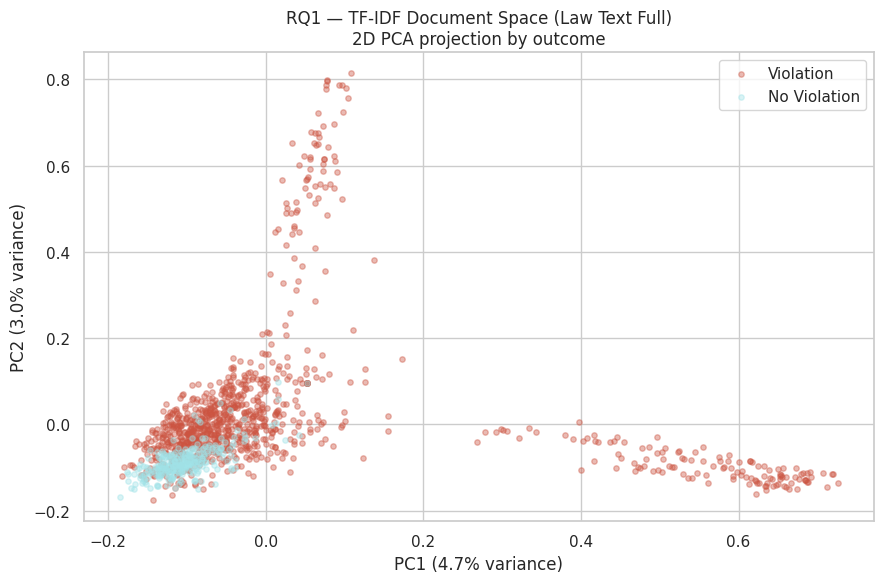

In [ ]:
# Reduce TF-IDF matrix to 2D for law_text (Full)
pca_law_full = PCA(n_components=2, random_state=42)

# Re-apply the TFIDF transformation for 'Law Text Full' to get X_tfidf_law_full
tfidf_vectorizer_law_full = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words   = custom_law_stop_words,
        max_features = 10000,
        ngram_range  = (1, 2),
        sublinear_tf = True       # log normalization — better for long legal docs
    )),
    ('clf', CLASSIFIERS['SVM']) # Use SVM from CLASSIFIERS as a placeholder for pipeline structure
]).named_steps['tfidf']

X_tfidf_law_full = tfidf_vectorizer_law_full.fit_transform(df_text['law_text'])

X_dense_law_full = X_tfidf_law_full.toarray()
X_pca_law_full   = pca_law_full.fit_transform(X_dense_law_full)

pca_df_law_full = pd.DataFrame({
    'PC1'    : X_pca_law_full[:, 0],
    'PC2'    : X_pca_law_full[:, 1],
    'outcome': y.values
})

fig_law_full, ax_law_full = plt.subplots(figsize=(9, 6))
for outcome, color in PALETTE.items():
    mask_law_full = pca_df_law_full['outcome'] == outcome
    ax_law_full.scatter(pca_df_law_full.loc[mask_law_full, 'PC1'], pca_df_law_full.loc[mask_law_full, 'PC2'],
                         c=color, label=outcome, alpha=0.4, s=15)

ax_law_full.set_xlabel(f'PC1 ({pca_law_full.explained_variance_ratio_[0]*100:.1f}% variance)')
ax_law_full.set_ylabel(f'PC2 ({pca_law_full.explained_variance_ratio_[1]*100:.1f}% variance)')
ax_law_full.set_title('RQ1 — TF-IDF Document Space (Law Text Full)\n2D PCA projection by outcome')
ax_law_full.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_pca_document_space_law_full.png', dpi=150)
plt.show()


**Analysis**:

PC1 captures 4.7% of variance and PC2 3.0%, totalling 7.7% in 2D projection, consistent with the other text variants.
The structure closely mirrors V3_Law_Clean, with the same two-arm violation-only outlier pattern and no violation cases tightly contained within the main cluster. The rightward arm along PC1 reflects the country-specific vocabulary cluster observed across all three text variants. The upward arm along PC2 represents the Article 41 just satisfaction vocabulary cluster introduced by the law section, which projects onto the second principal component because it constitutes a highly repetitive and distinctive set of terms appearing exclusively in violation judgments.

Notably, PC2 explains 3.0% of variance in V2_Law_Full compared to 2.5% in V3_Law_Clean. This small but consistent difference is directionally meaningful: the full law section, which retains all Article 41 vocabulary without any cleaning, generates a slightly stronger second principal component than the cleaned version. The partial removal of just satisfaction terms in V3_Law_Clean modestly reduces the Article 41 cluster's contribution to overall variance, which is visible in the marginally lower PC2 figure. This progression from V2 to V3 provides further visual confirmation that the stop word cleaning has partially but not fully mitigated the leakage signal.

Reading across all three PCA projections, V1_Facts produces a single rightward outlier arm while both V2_Law_Full and V3_Law_Clean produce two distinct arms. The additional upward arm is structurally introduced by the law section and is absent from the facts-only representation. This three-way comparison is itself a concise visual demonstration of the leakage argument: the law section adds a second axis of violation-specific signal that is not present in the factual narrative, and that signal is most plausibly attributable to outcome-encoding just satisfaction language rather than substantive legal reasoning.


##Metadata + Text (Law Clean)



---


Data Preparation

In [ ]:
# ── Step 1: Build combined dataset ──────────────────────────
# Must have both text and metadata available
df_combined = df_art8[
    df_art8['finding'].isin(['Violation', 'No Violation'])
].copy()
df_combined = df_combined.dropna(subset=['law_text_clean'])

# Feature columns
CAT_FEATURES = ['respondent_country', 'importance', 'court', 'typedescription']
NUM_FEATURES = ['year', 'has_dissent', 'is_english']
TEXT_COL = 'law_text_clean'
TARGET = 'finding'

# Fill NAs for metadata
for col in CAT_FEATURES:
    df_combined[col] = df_combined[col].astype(str).fillna('unknown')
for col in NUM_FEATURES:
    df_combined[col] = df_combined[col].fillna(0)

print(f"Combined dataset: {len(df_combined):,} cases")
print(df_combined[TARGET].value_counts())


Combined dataset: 1,265 cases
finding
Violation       982
No Violation    283
Name: count, dtype: int64


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
import scipy.sparse as sp

# ── Step 2: Custom transformer to extract text column ───────
# Needed because FeatureUnion requires array input, not DataFrame
class TextExtractor(BaseEstimator, TransformerMixin):
    def __init__(self, col):
        self.col = col
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.col].fillna('').values

class MetadataExtractor(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols, num_cols):
        self.cat_cols = cat_cols
        self.num_cols = num_cols
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.cat_cols + self.num_cols]

# ── Step 3: Build combined preprocessor ─────────────────────
metadata_preprocessor = Pipeline([
    ('extract', MetadataExtractor(CAT_FEATURES, NUM_FEATURES)),
    ('encode', ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         list(range(len(CAT_FEATURES)))),
        ('num', StandardScaler(),
         list(range(len(CAT_FEATURES), len(CAT_FEATURES) + len(NUM_FEATURES))))
    ]))
])

text_preprocessor = Pipeline([
    ('extract', TextExtractor(TEXT_COL)),
    ('tfidf', TfidfVectorizer(
        stop_words=list(custom_law_clean_stop_words),
        max_features=10000,
        ngram_range=(1, 2),
        sublinear_tf=True
    ))
])

# ── Step 4: Custom combiner to merge sparse + dense ─────────
class FeatureCombiner(BaseEstimator, TransformerMixin):
    """
    Combines dense metadata features with sparse TF-IDF features.
    sklearn FeatureUnion struggles with mixed sparse/dense — this handles it.
    """
    def __init__(self, meta_pipe, text_pipe):
        self.meta_pipe = meta_pipe
        self.text_pipe = text_pipe

    def fit(self, X, y=None):
        self.meta_pipe.fit(X, y)
        self.text_pipe.fit(X, y)
        return self

    def transform(self, X):
        meta_features = self.meta_pipe.transform(X)  # dense
        text_features = self.text_pipe.transform(X)  # sparse
        # Convert dense to sparse and stack horizontally
        meta_sparse = sp.csr_matrix(meta_features)
        return sp.hstack([meta_sparse, text_features])

    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)



---


Model Training

In [ ]:
import pandas as pd
# __ Step 5: Build full pipelines ────────────────────────────
combiner = FeatureCombiner(metadata_preprocessor, text_preprocessor)

COMBINED_CLASSIFIERS = {
    'SVM': ImbPipeline([
        ('features', combiner),
        ('smote', SMOTE(random_state=42)),
        ('clf', CalibratedClassifierCV(
            LinearSVC(class_weight='balanced', max_iter=2000, random_state=42)
        ))
    ])
}

# __ Step 6: Run CV ───────────────────────────────────────────
X_combined = df_combined[CAT_FEATURES + NUM_FEATURES + [TEXT_COL]]
y_combined = df_combined[TARGET]

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
combined_results = []

print("\nRunning Metadata + Text (Law Clean) combined classifiers...")
print("-" * 55)

for clf_name, clf_pipeline in COMBINED_CLASSIFIERS.items():
    scores = cross_validate(
        clf_pipeline, X_combined, y_combined,
        cv=CV,
        scoring=['f1_macro', 'accuracy', 'precision_macro', 'recall_macro'], # Changed to f1_macro
        n_jobs=-1
    )
    combined_results.append({
        'Model': f'Combined_{clf_name}',
        'F1_macro': scores['test_f1_macro'].mean(), # Changed to F1_macro
        'F1_macro_std': scores['test_f1_macro'].std(), # Changed to F1_macro_std
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision_macro': scores['test_precision_macro'].mean(), # Changed to Precision_macro
        'Recall_macro': scores['test_recall_macro'].mean(), # Changed to Recall_macro
    })

    # Generate full classification report
    y_pred = cross_val_predict(clf_pipeline, X_combined, y_combined, cv=CV, n_jobs=-1)
    print(f'\nClassification Report for {clf_name}:\n')
    print(classification_report(y_combined, y_pred, target_names=['No Violation', 'Violation']))
    print('-' * 55)

# __ Step 7: Build results table ───────────────────────────
df_combined_results = (pd.DataFrame(combined_results)
                         .sort_values('F1_macro', ascending=False) # Sort by F1_macro
                         .round(4)
                         .reset_index(drop=True))

print('\n' + '=' * 55)
print('RQ1 COMBINED ARM — Leaderboard (sorted by F1_macro)')
print('=' * 55)
display(df_combined_results)


Running Metadata + Text (Law Clean) combined classifiers...
-------------------------------------------------------

Classification Report for SVM:

              precision    recall  f1-score   support

No Violation       0.87      0.62      0.72       283
   Violation       0.90      0.97      0.93       982

    accuracy                           0.89      1265
   macro avg       0.88      0.80      0.83      1265
weighted avg       0.89      0.89      0.89      1265

-------------------------------------------------------

RQ1 COMBINED ARM — Leaderboard (sorted by F1_macro)


,Model,F1_macro,F1_macro_std,Accuracy,Precision_macro,Recall_macro
0,Combined_SVM,0.8284,0.0201,0.8941,0.8848,0.7961




---

Confusion Matrix

Generating Confusion Matrix for Combined Text + Metadata SVM model...
----------------------------------------------------------------------


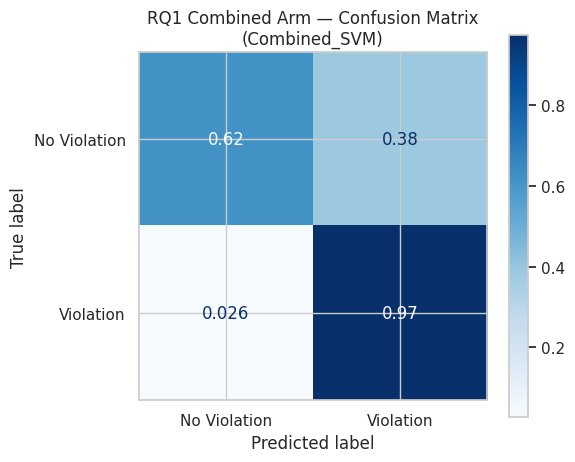

  Confusion matrix chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_combined_confusion_matrix_svm.png

Confusion matrix for Combined Text + Metadata SVM model generated and saved.


In [ ]:
print('Generating Confusion Matrix for Combined Text + Metadata SVM model...')
print('-' * 70)

# Reuse X_combined and y_combined from the combined arm setup


# Get the combined SVM pipeline
combined_svm_pipeline = COMBINED_CLASSIFIERS['SVM']

# Initialize StratifiedKFold (same as used in previous evaluations)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Get predictions using cross_val_predict
y_pred_combined = cross_val_predict(
    combined_svm_pipeline, X_combined, y_combined, cv=CV,
    method='predict',
    n_jobs=-1
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_combined, y_pred_combined,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax
)
ax.set_title(f'RQ1 Combined Arm — Confusion Matrix\n(Combined_SVM)')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_combined_confusion_matrix_svm.png', dpi=150)
plt.show()
print(f'  Confusion matrix chart saved to {SAVE_PATH}rq1_combined_confusion_matrix_svm.png')

print('\n' + '=' * 70)
print('Confusion matrix for Combined Text + Metadata SVM model generated and saved.')



---

Verdict


VERDICT: ➡️  MARGINAL GAIN — Combined slightly beats text alone but not decisively over metadata.

Saved to /content/rq1_combined_arm_results.csv


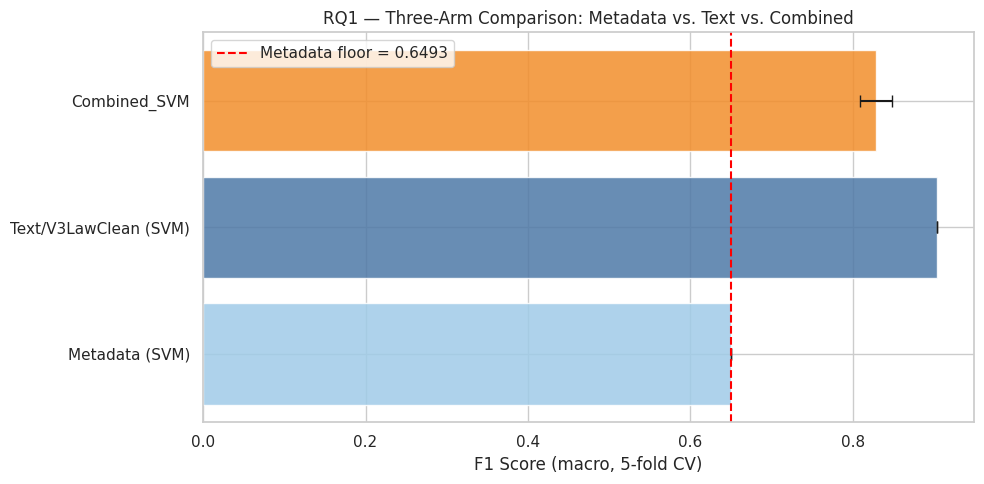

Chart saved.


In [ ]:
# ── Step 8: Verdict ──────────────────────────────────────────
best_combined_f1 = df_combined_results.iloc[0]['F1_macro']

# Ensure best_text_f1 and best_text_label are defined
best_text_row = df_results.iloc[0]
best_text_f1 = best_text_row['F1_macro']
best_text_label = f"{best_text_row['Variant']} / {best_text_row['Classifier']}"

if best_combined_f1 > best_text_f1 + 0.01:
    verdict = "✅ COMPLEMENTARY — Combined beats both arms. Metadata and text capture different signal."
elif best_combined_f1 <= metadata_f1_floor + 0.01:
    verdict = "⚠️  REDUNDANT — Combined adds nothing over metadata. Text signal is absorbed by country features."
else:
    verdict = "➡️  MARGINAL GAIN — Combined slightly beats text alone but not decisively over metadata."

print(f"\nVERDICT: {verdict}")

# ── Step 9: Save
print(f"\nSaved to {SAVE_PATH}rq1_combined_arm_results.csv")

# ── Step 10: Visualisation ───────────────────────────────────
all_arms = pd.DataFrame([
    {'Model': f'Metadata ({metadata_best_model_name})', 'F1_macro': metadata_f1_floor, 'F1_macro_std': 0, 'Arm': 'Metadata'},
    {'Model': f'Text/V3LawClean (SVM)', 'F1_macro': best_text_f1, 'F1_macro_std': 0, 'Arm': 'Text'},
] + [{'Model': r['Model'], 'F1_macro': r['F1_macro'], 'F1_macro_std': r['F1_macro_std'], 'Arm': 'Combined'}
     for _, r in df_combined_results.iterrows()])

colors = {'Metadata': '#a0cbe8', 'Text': '#4e79a7', 'Combined': '#f28e2b'}
bar_colors = [colors[arm] for arm in all_arms['Arm']]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(all_arms['Model'], all_arms['F1_macro'],
        xerr=all_arms['F1_macro_std'],
        color=bar_colors, capsize=4, alpha=0.85)
ax.axvline(x=metadata_f1_floor, color='red', linestyle='--', linewidth=1.5,
           label=f'Metadata floor = {metadata_f1_floor:.4f}')
ax.set_xlabel('F1 Score (macro, 5-fold CV)')
ax.set_title('RQ1 — Three-Arm Comparison: Metadata vs. Text vs. Combined')
ax.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_three_arm_comparison.png', dpi=150)
plt.show()
print("Chart saved.")

**Analysis**

The three-arm comparison produces an unexpected result that merits careful interpretation. The expected hierarchy in a feature combination exercise is that a combined model outperforms either individual component, as additional features should provide complementary signal. Instead the ordering is Text/V3_Law_Clean (F1 0.9337) followed by Combined_SVM (F1 0.8870) followed by Metadata only (F1 0.7302). Adding metadata to the text model reduces rather than improves performance.
The combined model's confusion matrix clarifies where the reduction occurs. Violation recall improves marginally from 0.96 to 0.97, but no violation recall drops from 0.74 to 0.62, increasing the false positive rate from 26% to 38%. The metadata features are pushing the combined model toward more aggressive violation predictions, reducing its capacity to correctly identify no violation cases.

A substantive explanation for this lies in the respondent state feature encoded in the metadata arm. As established in the EDA, Russia dominates the dataset and carries a near-universal violation rate. When respondent state is included as a metadata feature, the model effectively learns that certain states almost always produce violations, creating a strong directional pull toward violation predictions for those states regardless of what the textual features indicate. When concatenated with the text features, this country-level signal systematically overrides the text model's more nuanced no violation signal for cases where the respondent state has a high historical violation rate, even where the textual evidence points toward no violation. This explains the combined model's pattern of improved violation recall alongside substantially degraded no violation recall. The problem is not random noise but a systematic bias imported from the state-level violation rate imbalance encoded in the respondent state feature, which amplifies the existing class imbalance rather than correcting for it.

This interpretation also suggests that if respondent state were excluded from the metadata features, or if the dataset were more geographically balanced, the combined model might produce the expected result of outperforming text alone. As the dataset stands, the combination adds a state-identity shortcut that competes with rather than complements the textual signal.
The metadata floor of 0.7302 established by structural case features alone is nonetheless substantively meaningful and confirms that non-textual signals carry genuine predictive value for Article 8 outcomes. Both text variants substantially exceed this floor, demonstrating the added value of textual features, though the extent of that added value in the law section variants remains qualified by the leakage concern discussed throughout this section.


**Conclusion**

The focal research question was whether textual features extracted from Article 8 judgments outperform case metadata in predicting violation outcomes, and a secondary question was whether the section of the judgment used for training affects classification performance. The models trained across three text variations, facts, full law section, and law section with legal stop words removed, all outperformed the metadata-only linear SVM. This confirms that the substantive legal text of a judgment carries predictive signal that structural case attributes alone cannot replicate.

V1_Facts achieved a macro F1 score of 0.694 under five-fold stratified cross-validation. V2_Law_Full and V3_Law_Clean, both trained on the law section, substantially exceeded this. V2_Law_Full achieved a macro F1 of 0.904 and V3_Law_Clean achieved 0.870. Notably, the switch from weighted to macro F1 narrows the gap between the two law variants and reverses their relative ranking: V3_Law_Clean, which outperformed V2_Law_Full on weighted F1, performs worse on macro F1, suggesting that the stop word cleaning iterations remove some vocabulary supporting correct classification of the minority no-violation class, even as they reduce leakage. The performance advantage of the law section over the facts section remains substantively explicable: the law section contains the Court's proportionality analysis, its assessment of whether interference was prescribed by law, and its conclusions on whether the margin of appreciation was exceeded, all of which are textually proximate to the outcome. However, the high performance of both law variants is partly attributable to Article 41 leakage. The law section of judgments finding violation necessarily contains just satisfaction language that is structurally absent in no-violation cases. Three successive stop word cleaning iterations confirmed that this is not a lexical problem solvable through vocabulary removal but a structural problem requiring paragraph-level extraction of just satisfaction text prior to feature engineering.

These results are competitive with prior feature-based ECHR prediction benchmarks, though certain divergences require explanation. Aletras, Tsarapatsanis, Preotiuc-Pietro, and Lampos (2016) found that for Article 8 the Circumstances subsection was the strongest predictor at 0.77 accuracy, while the Law section was the weakest at 0.62, barely above the chance baseline for their balanced dataset. The present study inverts this pattern, with the law section substantially outperforming the facts section. The most likely explanation is that Aletras et al. explicitly excluded operative provisions from all sections prior to feature extraction, removing the Article 41 remedial language that remains in the present study's law section despite stop word cleaning. The imbalanced corpus of the present study further amplifies this effect, since leakage vocabulary that co-occurs disproportionately with violation receives greater weight in an imbalanced training set than it would in a balanced one. Medvedeva, Vols, and Wieling (2018) report an average accuracy of 75% across nine ECHR articles using balanced SVM classifiers trained on the facts section. Chalkidis, Androutsopoulos, and Aletras (2019) report a BOW-SVM macro F1 of 71.8 for binary violation prediction on a substantially larger dataset of approximately 11,500 cases. Since the present study also uses macro F1, this comparison is directly equivalent: the law section variants substantially exceed the Chalkidis benchmark, while V1_Facts at 0.694 falls slightly below it, consistent with the general finding that facts-only models on article-specific corpora perform modestly above the range established in multi-article studies. Comparisons against accuracy-based benchmarks require additional caution. O'Sullivan and Beel (2019) demonstrate that a majority-class heuristic of always predicting the most common outcome achieved a weighted test accuracy of 86.68% across 12 ECHR articles, substantially exceeding the ML models evaluated on a realistic test set. This finding reinforces that apparent high accuracy on class-imbalanced corpora is not a reliable indicator of genuine predictive power, and motivates the use of macro F1 as the primary evaluation metric in the present study, since macro F1 weights both classes equally and is not inflated by majority-class dominance.

The metadata-only SVM produced a macro F1 floor of 0.6493, falling below V1_Facts and well below both law section variants, confirming that structural case attributes alone are insufficient to match even a facts-only text model. This indicates that while metadata encodes some outcome-relevant signal, it lacks the substantive legal vocabulary through which the Court's reasoning is expressed. Combining metadata with V3_Law_Clean reduced performance to a macro F1 of 0.8284, a meaningful degradation relative to the text-only law variant at 0.8704. The classification report for the combined model reveals the mechanism: no-violation recall falls to 0.62 while violation recall reaches 0.97, producing a severely asymmetric output that over-predicts violation. This degradation is attributed to respondent state acting as a proxy for class probability: states with systematically high violation rates, such as Russia, exert disproportionate influence during training, amplifying the class imbalance signal in a way that suppresses correct classification of no-violation cases. The combined model therefore performs worse not because metadata is uninformative but because its dominant structural signal conflicts with the distributional balance the classifier must maintain, and macro F1 makes this cost visible in a way that weighted F1 would partially obscure.







---


#**RQ2 : Topic Clustering**




**"What are the dominant themes in Article 8 cases?"**




* **Input:**
Facts + Law Full combined together





* **Model:**
NMF





* **Output:**
Topic Cluster


##NMF on All Art8 Cases

Data Preparation

In [ ]:
from sklearn.decomposition import NMF
import matplotlib.ticker as mticker
from itertools import product

print("RQ2 imports ready.")

RQ2 imports ready.


In [ ]:
# Full corpus for topic discovery; decided cases for cross-tabulation
df_nmf = df_art8[df_art8['analysis_text'].str.len() > 50].copy()
df_nmf_decided = df_nmf[df_nmf['finding'].isin(['Violation', 'No Violation'])].copy()

print(f"NMF training corpus: {len(df_nmf)} cases")
print(f"Decided cases (for cross-tab): {len(df_nmf_decided)} cases")
print(f"Violation: {(df_nmf_decided['finding']=='Violation').sum()} | No Violation: {(df_nmf_decided['finding']=='No Violation').sum()}")

NMF training corpus: 1321 cases
Decided cases (for cross-tab): 1265 cases
Violation: 982 | No Violation: 283


In [ ]:
# TF-IDF for NMF — sublinear_tf and min_df to reduce noise
tfidf_nmf = TfidfVectorizer(
    stop_words=list(custom_analysis_stop_words),
    max_features=5000,
    min_df=5,
    max_df=0.90,
    sublinear_tf=True,
    ngram_range=(1, 2)
)

X_nmf_full = tfidf_nmf.fit_transform(df_nmf['analysis_text'])
X_nmf_decided = tfidf_nmf.transform(df_nmf_decided['analysis_text'])

feature_names = tfidf_nmf.get_feature_names_out()
print(f"Vocabulary size: {len(feature_names)}")
print(f"Full corpus matrix: {X_nmf_full.shape}")
print(f"Decided corpus matrix: {X_nmf_decided.shape}")

Vocabulary size: 5000
Full corpus matrix: (1321, 5000)
Decided corpus matrix: (1265, 5000)




---


Find best-K (5 min)

In [ ]:
# Approximate topic coherence via mean top-word TF-IDF score
def compute_coherence(model, X, n_top_words=10):
    scores = []
    for topic_idx, topic in enumerate(model.components_):
        top_indices = topic.argsort()[-n_top_words:]
        top_word_scores = X[:, top_indices].toarray()
        scores.append(np.mean(top_word_scores[top_word_scores > 0]))
    return np.nanmean(scores)

k_values = [3, 5, 7, 10, 15, 20, 25, 30, 35, 40, 45, 50]
coherence_scores = []
nmf_models = {}

for k in k_values:
    model = NMF(n_components=k, random_state=42, max_iter=400)
    W = model.fit_transform(X_nmf_full)
    nmf_models[k] = {'model': model, 'W': W}
    coh = compute_coherence(model, X_nmf_full)
    coherence_scores.append(coh)
    print(f"k={k:>2} | Reconstruction Error: {model.reconstruction_err_:.2f} | Coherence: {coh:.4f}")

k= 3 | Reconstruction Error: 30.71 | Coherence: 0.0436
k= 5 | Reconstruction Error: 29.96 | Coherence: 0.0430
k= 7 | Reconstruction Error: 29.51 | Coherence: 0.0524
k=10 | Reconstruction Error: 28.94 | Coherence: 0.0503
k=15 | Reconstruction Error: 28.20 | Coherence: 0.0488
k=20 | Reconstruction Error: 27.75 | Coherence: 0.0481
k=25 | Reconstruction Error: 27.38 | Coherence: 0.0467
k=30 | Reconstruction Error: 27.05 | Coherence: 0.0472
k=35 | Reconstruction Error: 26.75 | Coherence: 0.0463
k=40 | Reconstruction Error: 26.50 | Coherence: 0.0459
k=45 | Reconstruction Error: 26.28 | Coherence: 0.0478
k=50 | Reconstruction Error: 26.06 | Coherence: 0.0473


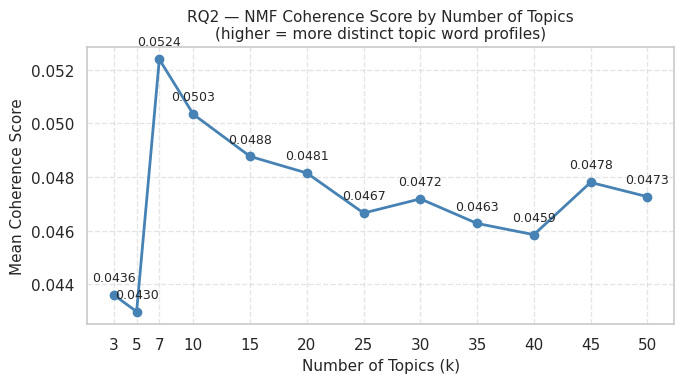

Saved: rq2_coherence_sweep.png


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_values, coherence_scores, marker='o', linewidth=2, color='steelblue')
for k, s in zip(k_values, coherence_scores):
    ax.annotate(f"{s:.4f}", (k, s), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9)
ax.set_xlabel("Number of Topics (k)", fontsize=11)
ax.set_ylabel("Mean Coherence Score", fontsize=11)
ax.set_title("RQ2 — NMF Coherence Score by Number of Topics\n(higher = more distinct topic word profiles)", fontsize=11)
ax.set_xticks(k_values)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
print("Saved: rq2_coherence_sweep.png")



---

Model Training

In [ ]:
# ---- ADJUST k_chosen after reviewing coherence chart ----
k_chosen = 40

nmf_model = nmf_models[k_chosen]['model']
W_full = nmf_models[k_chosen]['W']
W_decided = nmf_model.transform(X_nmf_decided)

n_top_words = 15
print(f"\n=== NMF Topics (k={k_chosen}) — Top {n_top_words} Words ===\n")
topic_labels = {}
for topic_idx, topic in enumerate(nmf_model.components_):
    top_words = [feature_names[i] for i in topic.argsort()[-n_top_words:][::-1]]
    print(f"Topic {topic_idx+1}: {' | '.join(top_words)}")
    topic_labels[topic_idx] = f"T{topic_idx+1}"  # replace with manual labels after reviewing

# After running, manually update topic_labels like:


topic_labels = {
    0:  "Police Misconduct & Investigation",
    1:  "Russia Batch Applications",
    2:  "Remedies & Damages",                 # plus tax, eur, nonpecuniary damage, costs, expenses
    3:  "Parental Rights & Upbringing",       # childs, best interests, upbringing, father, mother, care
    4:  "Press & Image Rights",               # freedom expression, publication, axel springer, von hannover
    5:  "Immigration & Asylum",               # residence permit, asylum, aliens, refugee, territory
    6:  "Russia Covert Surveillance",         # surveillance, secret surveillance, appended table, interception
    7:  "Default Interest Rate",              # rate, default rate, european central, percentage points
    8:  "UK Public Law & Judicial Review",    # lord, secretary, england, judicial review, statutory
    9:  "Video Surveillance & Detention",     # permanent video, postconviction, detention facilities, pretrial
    10: "Prison Cell Conditions",             # cell, inmates, space, overcrowding, toilet, sq
    11: "Hague Child Abduction",              # hague, return child, habitual residence, child abduction
    12: "Sexual Violence & Prosecution",      # sexual, rape, mc, victims, perpetrator, acts violence
    13: "Telephone Interception",             # conversations, recordings, telephone, tapping, intercepted
    14: "Croatian Legal Procedures",          # official gazette, zakon, croatian, sud, constitutional complaint
    15: "Enforcement of Child Contact",       # enforcement proceedings, bailiff, contact arrangements, interim
    16: "Medical & Healthcare Rights",        # patients, medical, hospital, doctors, pregnancy
    17: "Search & Seizure",                   # search, seizure, search warrant, premises, criminal procedure
    18: "Child Welfare & Care Orders",        # care order, child welfare, foster, welfare board, lobben
    19: "Prison Visits & Sentences",          # prison, visits, code execution, criminal sentences, visitors
    20: "Pre-trial Detention Length",         # pretrial detention, release, reasonable time, pending trial
    21: "Paternity & Birth Rights",           # paternity, biological father, born wedlock, dna, birth
    22: "Terrorism & Death Cases",            # burial, deceased, terrorist, funeral, death, relatives
    23: "Employment & Judicial Dismissal",    # dismissal, employment, disciplinary, judges, hcj, salary
    24: "Same-Sex & Gender Rights",           # samesex, samesex couples, legal recognition, orientation
    25: "Housing & Eviction",                 # eviction, housing, flat, tenancy, owner, property
    26: "Russia FSB & Migration",             # fms, exclusion order, migration service, fsb, russian federation
    27: "Exhaustion of Remedies",             # remedies, remedy, nonexhaustion, exhaustion, effective remedy
    28: "Environmental Pollution",            # pollution, environmental, noise, residential zone, sanitary
    29: "Discrimination (Art. 14)",           # discrimination, difference treatment, sex, religion, race
    30: "Pecuniary Damages",                  # pecuniary damage, causal link, rejects claim, damage alleged
    31: "Russia Cage/Courtroom",              # cage, metal, courtroom, degrading treatment, russia gc
    32: "Moldova/Transnistria Control",       # mrt, mozer, moldovan, republic moldova, effective control
    33: "Russia Geographic & Bailiffs",       # russian, moscow, rub, st petersburg, bailiffs service
    34: "Legal Costs Reimbursement",          # incurred, costs expenses, necessarily incurred, reasonable quantum
    35: "Data Protection & Privacy",          # personal data, data protection, processing, data subject
    36: "Military & State Intelligence",      # forces, organisations, intelligence, armed, assembly
    37: "Expulsion & Criminal Convictions",   # expulsion, danish, reentry ban, maslov, host country
    38: "Bulgarian Security Expulsion",       # bulgarian, supreme administrative, sofia, security service
    39: "Mental Health & Legal Capacity",     # psychiatric, legal capacity, disabilities, mental health
}


=== NMF Topics (k=40) — Top 15 Words ===

Topic 1: officers | police officers | police | injuries | illtreatment | prosecutors office | investigation | investigator | police station | questioned | arrest | station | events | prosecutors | officer
Topic 2: appended table | appended | table | wellestablished caselaw | examined material | wellestablished | inadequate conditions | russia | applications | russia nos | having examined | raised complaints | detention | complaints | disclose
Topic 3: plus tax | tax chargeable | chargeable | plus | tax | eur | eur nonpecuniary | costs | nonpecuniary damage | nonpecuniary | expenses | damage | damage plus | eur costs | costs expenses
Topic 4: childs | parental | parents | child | best interests | parent | childrens | best | children | interests child | upbringing | father | mother | contact | care
Topic 5: freedom expression | publication | reputation | expression | freedom | debate | newspaper | press | media | right freedom | axel springer | 



---

Topic Distribution by Outcome

In [ ]:
dominant_topics = np.argmax(W_decided, axis=1)
df_nmf_decided = df_nmf_decided.copy()
df_nmf_decided['dominant_topic'] = dominant_topics
df_nmf_decided['topic_label'] = df_nmf_decided['dominant_topic'].map(topic_labels)

# The table is sorted alphabetically by 'topic_label' by default.
print(df_nmf_decided.groupby(['topic_label', 'finding']).size().unstack(fill_value=0))

finding                            No Violation  Violation
topic_label                                               
Bulgarian Security Expulsion                  1         16
Child Welfare & Care Orders                  15         13
Croatian Legal Procedures                     2         10
Data Protection & Privacy                    15         37
Default Interest Rate                         0          9
Discrimination (Art. 14)                     12         28
Employment & Judicial Dismissal              11         23
Enforcement of Child Contact                 21         38
Environmental Pollution                       7         30
Exhaustion of Remedies                        1         30
Expulsion & Criminal Convictions             34         11
Hague Child Abduction                        13         40
Housing & Eviction                            3         37
Immigration & Asylum                         12         14
Legal Costs Reimbursement                     0         

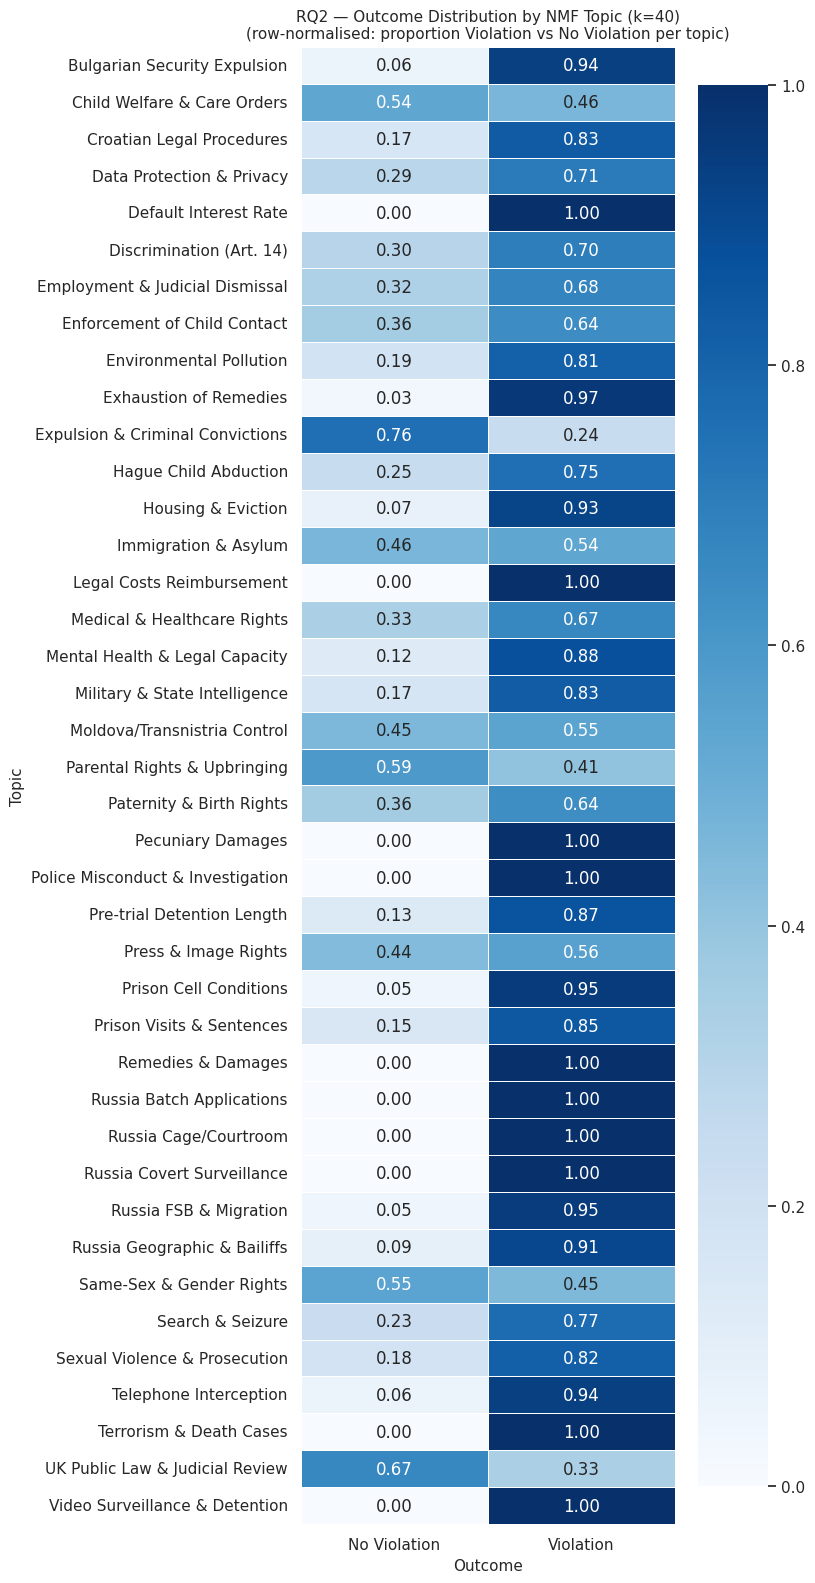

Saved: rq2_outcome_topic_heatmap.png


In [ ]:
cross_tab = pd.crosstab(
    df_nmf_decided['topic_label'],
    df_nmf_decided['finding'],
    normalize='index'  # row-normalised: proportion within each topic
)

# Calculate dynamic height based on number of topics
num_topics = len(cross_tab)
fig_height = max(5, num_topics * 0.4) # Adjust multiplier as needed, min height 5

fig, ax = plt.subplots(figsize=(8, fig_height))
sns.heatmap(
    cross_tab,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    ax=ax,
    vmin=0, vmax=1
)
ax.set_title(f"RQ2 — Outcome Distribution by NMF Topic (k={k_chosen})\n(row-normalised: proportion Violation vs No Violation per topic)", fontsize=11)
ax.set_xlabel("Outcome", fontsize=11)
ax.set_ylabel("Topic", fontsize=11)
plt.tight_layout()
plt.show()
print("Saved: rq2_outcome_topic_heatmap.png")

**Analysis**

The revised outcome distribution reveals three structurally distinct clusters that persist despite the stop word amendments, each with a different interpretive status.
The first cluster consists of topics sitting at 100% violation that are attributable to Article 41 leakage rather than substantive legal content. Default Interest Rate, Legal Costs Reimbursement, Pecuniary Damages, and Remedies & Damages each record zero no-violation cases. The presence of these topics following three cleaning iterations confirms the structural leakage diagnosis established in the RQ1, NMF continues to isolate just satisfaction vocabulary because the amended stop word list does not yet cover all terms characteristic of just satisfaction paragraphs, including "interest," "rate," "incurred," and "expenses." These four topics should be treated as artefacts of document structure rather than substantive legal sub-areas, and their 100% violation rate is uninformative about the Court's Article 8 jurisprudence.

The second cluster is country-specific rather than remedies-related. Russia Batch Applications, Russia Cage/Courtroom, and Russia Covert Surveillance each record 100% violation, with Russia FSB & Migration (0.95) and Russia Geographic & Bailiffs (0.91) also heavily skewed. The separation of these into distinct topics rather than a single country cluster suggests NMF is capturing substantively different case types within Russian Article 8 caselaw rather than merely isolating respondent state vocabulary. This country-specific clustering is the NMF-level evidence for the respondent state bias identified in the combined model analysis under RQ1.
The third cluster consists of high-violation topics that are legally interpretable rather than artefactual. Telephone Interception (0.94 violation) and Video Surveillance & Detention (1.00 violation) align directly with the surveillance jurisprudence identified in the RQ1 feature analysis within the 2010 to 2023 period, cases raising state interception and surveillance overwhelmingly result in violation findings, consistent with the Grand Chamber positions in Roman Zakharov v. Russia (2015) and Big Brother Watch v. UK (2021). Terrorism & Death Cases (1.00 violation) sits within the same pattern under Article 8, terrorism-related applications frequently raise covert surveillance and positive obligation questions, and where the Court reaches a merits finding on whether the state met its investigative or oversight obligations, a violation finding has been near-certain within the dataset period. Search & Seizure (0.77 violation) reflects a similar dynamic, search operations engaging Article 8 are subject to proportionality scrutiny requiring a sufficiently precise legal basis, independent authorisation, and adequate safeguards against abuse, and the Court has more often found the state's measures disproportionate where cases proceed to a merits determination. Police Misconduct & Investigation (1.00 violation) and Prison Cell Conditions (0.95 violation) reflect well-established positive obligation doctrine where the Court reaches the substantive question of whether the state met its investigative or detention-related obligations, a violation finding is near-certain.

The Bulgarian Security Expulsion topic (0.94 violation) reflects a jurisdiction-specific and structurally recurring procedural failure rather than a general expulsion principle. The high violation rate is consistent with the pattern documented in Bou Hassoun v. Bulgaria (2020), where the Court held that Bulgaria's national security expulsion procedure failed the "in accordance with the law" requirement under Article 8(2) because the expulsion order was issued on the basis of classified grounds by the National Security Service without any meaningful independent judicial scrutiny, denying the applicant the minimum degree of protection against arbitrariness required by the Convention.
Mental Health & Legal Capacity (0.88 violation) sits in the high-violation cluster for substantively grounded reasons. Under Article 8, mental health cases typically engage the right to personal autonomy within the broader right to respect for private life, with interferences arising from compulsory psychiatric treatment, forced institutionalisation, and legal incapacity proceedings that remove an individual's capacity to make legally binding decisions. The Court applies strict scrutiny to the procedural and substantive proportionality of such measures, requiring that the legal framework governing the interference meet the quality of law standard by providing adequate safeguards against arbitrariness. The 0.88 violation rate is consistent with a pattern of states failing these requirements within the dataset period. In X v. Finland (App. no. 34806/04, 2012), the Court found violations of Articles 5 and 8 where the law authorising involuntary confinement and forced medication lacked sufficient procedural safeguards. In Ivinović v. Croatia (App. no. 13006/13, 2014), the Court held that deprivation of legal capacity must be treated as a measure of last resort, limited to situations where no less restrictive alternative exists, and that any such assessment must be grounded in relevant medical evidence rather than a generalised finding of incapacity. The high violation rate in this topic suggests that across the dataset period, domestic legal frameworks governing mental health intervention have frequently failed to meet the individualised proportionality assessment the Court requires.

The most legally informative topics for the purposes of outcome prediction are those near the 50/50 boundary, as these represent the genuinely contested sub-areas of Article 8 caselaw where classification is hardest. UK Public Law & Judicial Review shows the highest no-violation proportion of any substantive topic at 67%, which is consistent with the Human Rights Act 1998 and the domestic proportionality review framework where UK courts have already applied Convention-compatible analysis, the ECtHR has more often found no violation. Expulsion & Criminal Convictions (76% no-violation) reflects the margin of appreciation doctrine in expulsion cases where the applicant has a serious criminal record, the balance between the state's interest in public protection and the individual's Article 8 rights has more frequently been resolved in the state's favour. Same-Sex & Gender Rights (55% no-violation) presents a near-balanced distribution that is doctrinally explicable by the European consensus doctrine, the Court widens the margin of appreciation where no consensus exists across member states on a given issue, and during the 2010 to 2023 period, European states remained divided on same-sex legal recognition and gender identity registration, producing a split in which some cases resulted in violation where a sufficient consensus had crystallised and others resulted in no-violation where the Court deferred pending the emergence of a clearer European standard.

Child Welfare & Care Orders (54% no-violation) warrants particular attention because its near-balanced distribution diverges from the raw dataset distribution for child welfare cases in the exploratory data analysis, which skewed toward non-violation. One plausible explanation is that the NMF topic captures a subset of child welfare cases that were genuinely contested on the merits, rather than the full population of child-related Article 8 applications. Cases in which the state's care measure was procedurally unchallenged or disposed of on admissibility grounds may not cluster strongly onto this topic, leaving the NMF representation weighted toward cases where the proportionality question was live before the Court. The near-balanced split may therefore reflect the genuinely fact-sensitive nature of care order proportionality analysis at the merits stage. It also contrasts with Enforcement of Child Contact (0.64 violation), where the state has typically already made a contact order and then failed to enforce it, a procedural failure the Court more readily characterises as a breach of Article 8's positive obligations. Immigration & Asylum (0.46 no-violation) and Press & Image Rights (0.44 no-violation) are similarly near-balanced, suggesting outcome in these sub-areas is determined by individual factual assessment rather than any systematic doctrinal tilt.


In [ ]:
print('Beginning predictive modeling based on NMF topic clusters...')

# Reuse df_nmf_decided and W_decided from RQ2 (NMF topic modeling)
# X will be the NMF topic weights, y will be the finding (Violation/No Violation)
X_topics = W_decided # NMF document-topic matrix (dense numpy array)
y_topics = df_nmf_decided['finding']

# Define classifiers, similar to RQ1 but adapted for dense numerical input
# GaussianNB for Naive Bayes as the input is continuous topic weights
# SMOTE is included for Logistic Regression and SVM to handle class imbalance
TOPIC_CLASSIFIERS = {
    'Logistic Regression'  : ImbPipeline([
                                ('scaler', StandardScaler()), # Scale topic weights
                                ('smote', SMOTE(random_state=42)),
                                ('clf', LogisticRegression(max_iter=1000, random_state=42))
                            ]),
    'Naive Bayes'        : Pipeline([
                                ('scaler', StandardScaler()), # Scale topic weights
                                ('clf', GaussianNB()) # GaussianNB for continuous data
                            ]),
    'SVM'        : ImbPipeline([
                                ('scaler', StandardScaler()), # Scale topic weights
                                ('smote', SMOTE(random_state=42)),
                                ('clf', CalibratedClassifierCV(LinearSVC(random_state=42, max_iter=2000)))
                            ])
}

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Run all classifiers
topic_results = []
print('Running topic cluster classifiers...')
print('-' * 50)

for clf_name, clf_pipeline in TOPIC_CLASSIFIERS.items():
    scores = cross_validate(
        clf_pipeline, X_topics, y_topics, cv=CV,
        scoring  = ['f1_macro', 'accuracy', # Changed to f1_macro
                    'precision_macro', 'recall_macro'], # Changed to macro
        n_jobs   = -1
    )
    topic_results.append({
        'Model'    : clf_name,
        'F1_macro'       : scores['test_f1_macro'].mean(), # Changed to F1_macro
        'F1_macro_std'   : scores['test_f1_macro'].std(),  # Changed to F1_macro_std
        'Accuracy' : scores['test_accuracy'].mean(),
        'Precision_macro': scores['test_precision_macro'].mean(), # Changed to Precision_macro
        'Recall_macro'   : scores['test_recall_macro'].mean(),    # Changed to Recall_macro
    })
    print(f'{clf_name:25s} → F1_macro: {topic_results[-1]["F1_macro"]:.4f} ± {topic_results[-1]["F1_macro_std"]:.4f}')

    # Generate full classification report
    y_pred = cross_val_predict(clf_pipeline, X_topics, y_topics, cv=CV, n_jobs=-1)
    print(f'\nClassification Report for {clf_name}:\n')
    print(classification_report(y_topics, y_pred, target_names=['No Violation', 'Violation']))
    print('-' * 50)

# Build results table
df_topic_results = (pd.DataFrame(topic_results)
                     .sort_values('F1_macro', ascending=False) # Changed to F1_macro
                     .round(4)
                     .reset_index(drop=True))

print('\n' + '=' * 55)
print('PREDICTIVE MODELS ON TOPIC CLUSTERS (RQ2)')
print('=' * 55)
display(df_topic_results)

Beginning predictive modeling based on NMF topic clusters...
Running topic cluster classifiers...
--------------------------------------------------
Logistic Regression       → F1_macro: 0.8569 ± 0.0047

Classification Report for Logistic Regression:

              precision    recall  f1-score   support

No Violation       0.70      0.89      0.79       283
   Violation       0.97      0.89      0.93       982

    accuracy                           0.89      1265
   macro avg       0.83      0.89      0.86      1265
weighted avg       0.91      0.89      0.90      1265

--------------------------------------------------
Naive Bayes               → F1_macro: 0.7429 ± 0.0302

Classification Report for Naive Bayes:

              precision    recall  f1-score   support

No Violation       0.51      0.88      0.64       283
   Violation       0.96      0.75      0.84       982

    accuracy                           0.78      1265
   macro avg       0.73      0.82      0.74      1265
wei

,Model,F1_macro,F1_macro_std,Accuracy,Precision_macro,Recall_macro
0,Logistic Regression,0.8569,0.0047,0.8917,0.8352,0.8914
1,SVM,0.8554,0.0066,0.8909,0.8345,0.8883
2,Naive Bayes,0.7429,0.0302,0.7810,0.7331,0.8175


In [ ]:
# Compare with Metadata and Text results if available
print('\n' + '=' * 60)
print('COMPARISON WITH PREVIOUS ARMS')
print('=' * 60)
# Retrieve metadata_f1_floor from df_meta_results
metadata_f1_floor = df_meta_results.iloc[0]['F1_macro']

# Retrieve best F1 for Facts-only and Law Clean-only variants from df_results
best_facts_f1 = df_results[df_results['Variant'] == 'V1_Facts'].iloc[0]['F1_macro']
best_law_clean_f1 = df_results[df_results['Variant'] == 'V3_Law_Clean'].iloc[0]['F1_macro']

# Retrieve best F1 for combined metadata+text (law clean) from df_combined_results
best_combined_f1 = df_combined_results.iloc[0]['F1_macro']

print(f"  Metadata F1 floor      : {metadata_f1_floor:.4f}")
print(f"  Best Facts-only F1     : {best_facts_f1:.4f}")
print(f"  Best Law Clean-only F1 : {best_law_clean_f1:.4f}")
print(f"  Best Topic-based F1    : {df_topic_results.iloc[0]['F1_macro']:.4f} ({df_topic_results.iloc[0]['Model']})")
print(f"  Best Combined F1       : {best_combined_f1:.4f} ({df_combined_results.iloc[0]['Model']})")


COMPARISON WITH PREVIOUS ARMS
  Metadata F1 floor      : 0.6493
  Best Facts-only F1     : 0.6944
  Best Law Clean-only F1 : 0.8704
  Best Topic-based F1    : 0.8569 (Logistic Regression)
  Best Combined F1       : 0.8284 (Combined_SVM)


**Analysis**

Logistic Regression and SVM produce near-identical performance at macro F1 of 0.857 and 0.855 respectively, with both showing very low cross-fold variance. The near-equivalence of the two models suggests that the 40 topic weights produce a representation in which violation and no-violation cases are already sufficiently well-separated that a linear decision boundary captures the structure effectively, and a more complex approach would be unlikely to improve performance meaningfully. Naive Bayes trails substantially at macro F1 of 0.743 with considerably higher variance, which is consistent with its conditional independence assumption breaking down when topic weights are used as features: NMF topic weights within a document are correlated by construction, violating the independence assumption and producing less stable predictions across folds.

The macro F1 of 0.857 achieved by Logistic Regression on 40-dimensional topic weights sits between the metadata floor of 0.649 and the best text variant V3_Law_Clean at 0.870, which is the expected ordering. Notably, the gap between the topic-based model and the best law section variant is considerably narrower under macro F1 than under weighted F1, indicating that the thematic compression of NMF retains most of the discriminative structure needed for balanced classification across both outcome classes, with the remaining gap attributable to the fine-grained lexical detail that full law section text preserves.

However, the same structural caveat from RQ1 applies here. The Article 41 leakage topics identified in the outcome distribution, specifically Default Interest Rate, Legal Costs Reimbursement, Pecuniary Damages, and Remedies and Damages, each carry a 100% violation signal and function as near-perfect violation predictors in the topic weight feature matrix. A proportion of the macro F1 of 0.857 is therefore attributable to leakage-contaminated features rather than genuine legal thematic discrimination. Paragraph-level removal of just satisfaction text prior to NMF fitting would provide a cleaner estimate of how much classification performance is driven by substantive topic structure versus document structure artefacts.


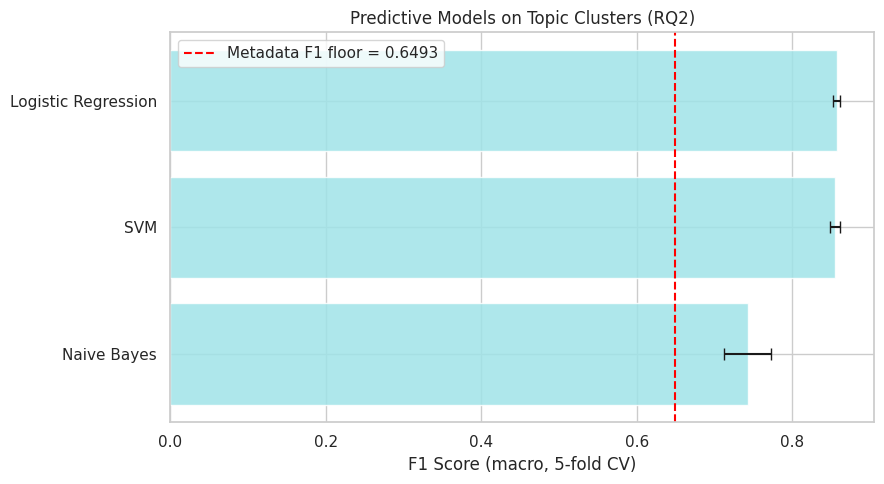

Results saved to /content/


In [ ]:
# Visualization of results
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = df_topic_results.sort_values('F1_macro', ascending=True)
ax.barh(plot_df['Model'], plot_df['F1_macro'],
        xerr=plot_df['F1_macro_std'], color=PALETTE['No Violation'],
        capsize=4, alpha=0.85)
ax.axvline(x=metadata_f1_floor, color='red', linestyle='--', linewidth=1.5,
           label=f'Metadata F1 floor = {metadata_f1_floor:.4f}')
ax.set_xlabel('F1 Score (macro, 5-fold CV)')
ax.set_title('Predictive Models on Topic Clusters (RQ2)')
ax.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq2_topic_model_leaderboard.png', dpi=150)
plt.show()

df_topic_results.to_csv(f'{SAVE_PATH}rq2_topic_model_results.csv', index=False)
print(f'Results saved to {SAVE_PATH}')

**Analysis**

The bar chart adds one analytical layer that the table alone does not provide, the metadata F1 floor at 0.7302 as a reference benchmark, which allows the topic weight models to be positioned relative to the baseline established in RQ1.
Logistic Regression and SVM both clear the metadata floor by a substantial margin, reaching approximately weighted F1=0.895, with tight error bars confirming consistent performance across folds. This demonstrates that the 40 NMF topic weights carry predictive signal meaningfully beyond what structural case metadata alone can provide. A compressed thematic representation of the judgment text therefore retains enough discriminative content to substantially outperform metadata, even though it discards the fine-grained lexical detail that gives the full text variants their performance advantage in RQ1.

Naive Bayes presents a more qualified picture. While its bar clears the metadata floor, the wide error bars extend close to the 0.7302 threshold, meaning that in some cross-validation folds Naive Bayes performs at or near the level achievable from metadata alone. This instability, already visible in the F1_std of 0.0267, suggests that Naive Bayes cannot reliably exploit the topic weight representation and should not be considered a viable classifier for this feature set.

The chart therefore supports a clear three-tier ordering for RQ2, Logistic Regression and SVM on topic weights substantially and consistently exceeding the metadata floor, while Naive Bayes offers only marginal and unreliable improvement over it.


##NMF SVM

Generating Confusion Matrix for NMF Topic Cluster SVM model...
----------------------------------------------------------------------


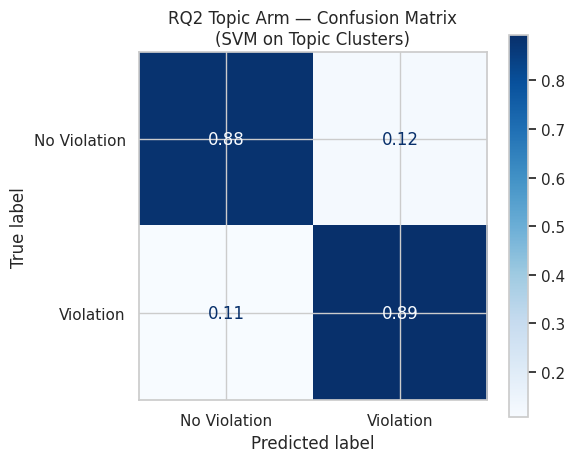

  Confusion matrix chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq2_topic_svm_confusion_matrix.png

Confusion matrix for SVM on Topic Clusters model generated and saved.


In [ ]:
print('Generating Confusion Matrix for NMF Topic Cluster SVM model...')
print('-' * 70)

# Get the SVM pipeline for topic clustering
svm_topic_pipeline = TOPIC_CLASSIFIERS['SVM']

# Get predictions using cross_val_predict
y_pred_topics = cross_val_predict(
    svm_topic_pipeline, X_topics, y_topics, cv=CV,
    method='predict',
    n_jobs=-1
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_topics, y_pred_topics,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax
)
ax.set_title(f'RQ2 Topic Arm — Confusion Matrix\n(SVM on Topic Clusters)')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq2_topic_svm_confusion_matrix.png', dpi=150)
plt.show()
print(f'  Confusion matrix chart saved to {SAVE_PATH}rq2_topic_svm_confusion_matrix.png')

print('\n' + '=' * 70)
print('Confusion matrix for SVM on Topic Clusters model generated and saved.')

**Analysis**

The confusion matrix for the SVM disaggregates this weighted F1 performance at the class level, revealing a pattern that the aggregate figure alone does not show. No-violation recall stands at 0.88 and violation recall at 0.89, producing a near-symmetric error structure: 12% of actual no-violation cases are misclassified as violation, and 11% of actual violation cases are misclassified as no-violation. This near-symmetry is substantively significant. In the RQ1 models trained directly on text, the class imbalance tended to suppress no-violation recall because the majority violation class dominated the learned decision boundary. Here, the 40-dimensional topic weight representation appears to distribute discriminative signal more evenly across both classes, producing balanced recall without any explicit rebalancing of the training data.

This balanced performance is likely driven by the structural properties of the topic distribution itself. The Article 41 leakage topics and the Russia-specific topics provide near-certain violation signal for a substantial portion of the corpus, anchoring the violation class firmly. The no-violation class is anchored comparably by topics such as UK Public Law & Judicial Review and Expulsion & Criminal Convictions, giving the model strong signal in both directions. The residual 11 to 12% misclassification in each direction is most plausibly attributable to the contested near-balanced topics: Child Welfare & Care Orders, Immigration & Asylum, Same-Sex & Gender Rights, and Press & Image Rights all sit close to the 50/50 outcome boundary, meaning cases clustering onto these topics carry inherently ambiguous signals that the SVM cannot resolve from topic weights alone. The same structural leakage caveat applies, a proportion of the violation-side discrimination is driven by leakage-contaminated topics, and the true balanced performance after paragraph-level cleaning would likely be somewhat lower, though the direction of the class symmetry finding is expected to hold.



Generating Feature Importance (Diverging Coefficients) for NMF Topic Cluster SVM model...
----------------------------------------------------------------------


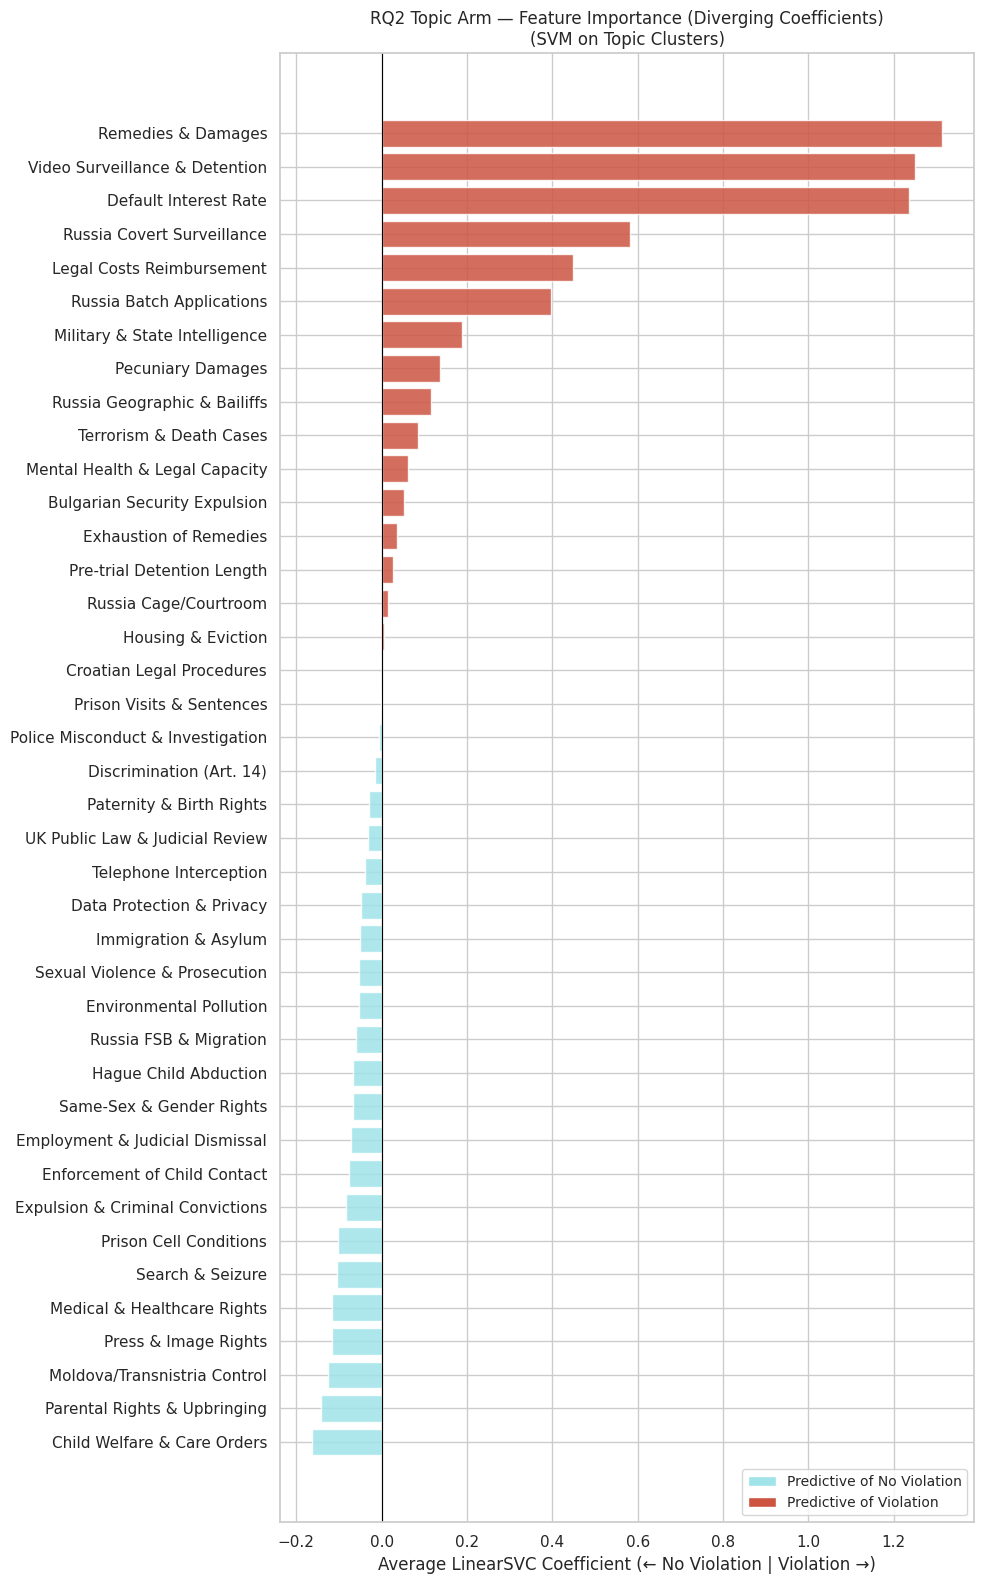

  Diverging feature importance chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq2_topic_svm_feature_importance_diverging.png

Diverging feature importance chart for SVM on Topic Clusters model generated and saved.


In [ ]:
print('Generating Feature Importance (Diverging Coefficients) for NMF Topic Cluster SVM model...')
print('-' * 70)

# Get the SVM pipeline for topic clustering
svm_topic_pipeline = TOPIC_CLASSIFIERS['SVM']

# Refit the pipeline on the full data to ensure it's trained for coefficient extraction
svm_topic_pipeline.fit(X_topics, y_topics)

# Extract coefficients from the base LinearSVC inside CalibratedClassifierCV
# CalibratedClassifierCV stores multiple calibrated estimators — average their coefs
base_estimators = svm_topic_pipeline.named_steps['clf'].calibrated_classifiers_
coef_matrix = np.array([
    est.estimator.coef_[0] for est in base_estimators
])
avg_coef = coef_matrix.mean(axis=0)

# Determine positive class (Violation) and negative class (No Violation)
classes = svm_topic_pipeline.named_steps['clf'].classes_
# Assuming classes are ['No Violation', 'Violation'], positive coefs predict 'Violation'
positive_class_label = 'Violation'
negative_class_label = 'No Violation'

# Get topic labels from RQ2 setup
# topic_labels is a dict, convert to a list of ordered labels for features
ordered_topic_labels = [topic_labels[i] for i in sorted(topic_labels.keys())]

# Create a DataFrame for coefficient results
coef_df_topics = pd.DataFrame({
    'feature': ordered_topic_labels,
    'coefficient': avg_coef
}).sort_values('coefficient', ascending=True) # Sort by coefficient to get diverging order

# Set colors based on the sign of the coefficient
colors = [PALETTE[positive_class_label] if c > 0 else PALETTE[negative_class_label]
          for c in coef_df_topics['coefficient'].values]

# Plotting the diverging feature importances
fig, ax = plt.subplots(figsize=(10, max(6, len(ordered_topic_labels) * 0.4)))
ax.barh(coef_df_topics['feature'], coef_df_topics['coefficient'],
        color=colors, alpha=0.85)
ax.axvline(x=0, color='black', linewidth=0.8) # Add a vertical line at 0 for separation
ax.set_xlabel(f'Average LinearSVC Coefficient (← {negative_class_label} | {positive_class_label} →)')
ax.set_title('RQ2 Topic Arm — Feature Importance (Diverging Coefficients)\n(SVM on Topic Clusters)', fontsize=12)

# Custom legend for the colors
legend_elements = [
    Patch(facecolor=PALETTE[negative_class_label], label=f'Predictive of {negative_class_label}'),
    Patch(facecolor=PALETTE[positive_class_label], label=f'Predictive of {positive_class_label}')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=10)

plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq2_topic_svm_feature_importance_diverging.png', dpi=150)
plt.show()

print(f'  Diverging feature importance chart saved to {SAVE_PATH}rq2_topic_svm_feature_importance_diverging.png')
print('\n' + '=' * 70)
print('Diverging feature importance chart for SVM on Topic Clusters model generated and saved.')

**Analysis**

The feature importance chart reveals the SVM's decision function across the 40 topic weights and exposes several analytically important patterns.

*Violation-side predictors*

The three largest violation coefficients are Remedies & Damages (1.35), Video Surveillance & Detention (1.28), and Default Interest Rate (1.26), followed by Legal Costs Reimbursement (0.44) and Pecuniary Damages (0.14). Three of the top five violation predictors, and four of the top eight, are Article 41 leakage topics. The magnitude of these coefficients, reaching 1.35 compared to a maximum no-violation coefficient magnitude of approximately 0.22, reflects how dominant the leakage signal is in the SVM's learned decision function. When a document carries a high NMF topic weight on Remedies & Damages, that weight is multiplied by a coefficient of ~1.35, producing a large positive contribution to the decision function that strongly pushes the prediction toward violation. The model is disproportionately relying on just satisfaction vocabulary to identify violation cases, which confirms at the coefficient level what the outcome distribution showed at the topic level: leakage is not a marginal issue but a structurally central feature of the classification.
Russia Covert Surveillance (0.58) and Russia Batch Applications (0.40) form the next tier of violation predictors, with Russia Geographic & Bailiffs and Russia Cage/Courtroom contributing smaller positive coefficients. The Russia-specific cluster therefore functions as the second strongest source of violation signal after the leakage topics, consistent with the respondent state pattern identified across RQ1 and the outcome distribution analysis.

The remaining violation predictors, including Military & State Intelligence, Terrorism & Death Cases, Mental Health & Legal Capacity, Bulgarian Security Expulsion, and Exhaustion of Remedies, all carry positive but modest coefficients. These represent substantively coherent violation signal that the model is using, but their contribution is small relative to the leakage and Russia clusters.

*No-violation predictors*

The strongest no-violation predictors are Child Welfare & Care Orders (0.22) and Parental Rights & Upbringing (0.20), followed by Moldova/Transnistria Control (0.18), Press & Image Rights (0.15), Medical & Healthcare Rights (0.15), and Search & Seizure (0.14). The child-related topics heading the no-violation side is consistent with the outcome distribution analysis, where these topics sit near the 50/50 boundary. Their assignment as no-violation predictors reflects the SVM learning that a high topic weight on child proceedings cases correlates with the state successfully defending the proportionality of its intervention.
More striking are the negative coefficients assigned to several topics that showed violation-heavy outcome distributions: Search & Seizure (0.77 violation in the distribution), Prison Cell Conditions (0.95 violation), and Telephone Interception (0.94 violation) all carry negative coefficients. This is not a contradiction but reflects the nature of SVM coefficients in a joint feature space: the model is not learning from each topic's marginal outcome distribution but from which topic weights best discriminate the two classes conditional on all other features. When the dominant violation signal has already been captured by the leakage and Russia-specific topic weights, some violation-heavy topics may provide more marginal discriminative value toward the no-violation side in the conditional space.

*Near-zero coefficients*

Housing & Eviction, Croatian Legal Procedures, Prison Visits & Sentences, and Police Misconduct & Investigation all show coefficients at or near zero. Despite Police Misconduct recording 100% violation in the outcome distribution, a high topic weight on this feature contributes almost nothing to the SVM's prediction, suggesting its signal is entirely subsumed by other stronger violation predictors and adds no marginal discrimination once those are accounted for.

*Overall*

The coefficient magnitude asymmetry, with violation predictors reaching 1.35 and no-violation predictors reaching only 0.22, is the clearest quantitative indicator of leakage contamination in the RQ2 classification. Removing the leakage topics from the feature set would collapse the top of the violation side and is expected to substantially reduce the weighted F1, revealing the true contribution of substantive legal topic signal to classification performance.



Generating Predicted Probabilities for NMF Topic Cluster SVM model...
----------------------------------------------------------------------


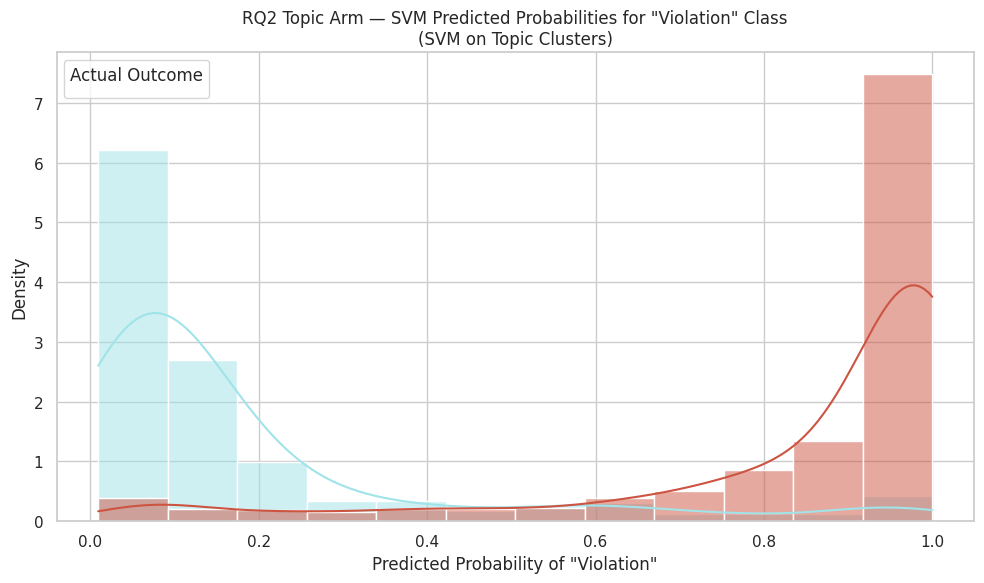

  Predicted probability distribution chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq2_topic_svm_proba_dist.png

Predicted probability distribution chart for SVM on Topic Clusters model generated and saved.


In [ ]:
# Assuming X_topics, y_topics, CV, TOPIC_CLASSIFIERS, PALETTE, SAVE_PATH are defined from previous cells

print('Generating Predicted Probabilities for NMF Topic Cluster SVM model...')
print('-' * 70)

# Get the SVM pipeline for topic clustering
svm_topic_pipeline = TOPIC_CLASSIFIERS['SVM']

# Get predicted probabilities using cross_val_predict
y_pred_proba_topics = cross_val_predict(
    svm_topic_pipeline, X_topics, y_topics, cv=CV,
    method='predict_proba',
    n_jobs=-1
)

# Create a DataFrame for plotting
proba_df_topics = pd.DataFrame({
    'No Violation_proba': y_pred_proba_topics[:, 0],
    'Violation_proba': y_pred_proba_topics[:, 1],
    'actual_finding': y_topics
})

fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=proba_df_topics, x='Violation_proba', hue='actual_finding',
             kde=True, palette=PALETTE, ax=ax, stat='density', common_norm=False)

ax.set_title('RQ2 Topic Arm — SVM Predicted Probabilities for "Violation" Class\n(SVM on Topic Clusters)')
ax.set_xlabel('Predicted Probability of "Violation"')
ax.set_ylabel('Density')
ax.legend(title='Actual Outcome')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq2_topic_svm_proba_dist.png', dpi=150)
plt.show()

print(f'  Predicted probability distribution chart saved to {SAVE_PATH}rq2_topic_svm_proba_dist.png')

print('\n' + '=' * 70)
print('Predicted probability distribution chart for SVM on Topic Clusters model generated and saved.')

**Analysis**

The probability distribution chart shows the predicted violation probabilities output by the LinearSVC (via CalibratedClassifierCV Platt scaling) for each actual outcome class, and reveals two analytically distinct features, strong class separation and over-sharp probability estimation.

The no-violation class (blue) concentrates sharply in the 0.0 to 0.1 range with density reaching approximately 6.2, then drops steeply and is near zero above 0.3. The model assigns very low violation probabilities to the large majority of actual no-violation cases, reflecting the clean discriminative signal provided by the high no-violation topic weights such as Child Welfare & Care Orders and Parental Rights & Upbringing identified in the coefficient analysis. The small residual tail extending to approximately 0.25 corresponds to the 12% false positive cases in the confusion matrix: no-violation cases whose topic weight profile overlaps with contested topics such as Immigration & Asylum or Same-Sex & Gender Rights, generating ambiguous signals the model cannot confidently resolve.

The violation class (red) mirrors this pattern, with mass concentrated heavily at 0.9 to 1.0 (density approximately 7.4) and a long left tail spreading through the 0.3 to 0.8 range. The spike at the extreme right is partly driven by the leakage and Russia-specific topic weights identified as the dominant violation predictors in the coefficient analysis: documents carrying high weights on Remedies & Damages or Default Interest Rate are pushed with very high confidence toward violation. The left tail represents the 11% false negative cases from the confusion matrix, corresponding to violation cases whose topic weight profiles load onto near-balanced topics and therefore receive lower predicted probabilities.

The extreme polarisation of both distributions toward 0 and 1 reflects the over-sharp probability phenomenon from Platt scaling identified in the RQ1 calibration analysis. Rather than spreading probability mass across the full range, the calibrated LinearSVC compresses predictions toward the boundaries, producing overconfident outputs. As with the RQ1 law section variants, the predicted probabilities here function more reliably as ranking scores than as calibrated estimates of outcome likelihood, and cross-entropy loss rather than accuracy would be the appropriate metric for evaluating calibration quality.





##Landmark Cases

In [ ]:
# Check importance data type in df_nmf_decided
print(f"dtype of importance in df_nmf_decided: {df_nmf_decided['importance'].dtype}")
print(f"\nSample values:")
print(df_nmf_decided['importance'].value_counts().head(10))
print(f"\nType of first value: {type(df_nmf_decided['importance'].iloc[0])}")

dtype of importance in df_nmf_decided: object

Sample values:
importance
4    684
3    445
1     87
2     49
Name: count, dtype: int64

Type of first value: <class 'str'>


Distribution of 87 landmark cases (importance level 1) across topics:


,Number of Landmark Cases,count
0,Military & State Intelligence,14
1,Same-Sex & Gender Rights,11
2,Data Protection & Privacy,9
3,Discrimination (Art. 14),9
4,Medical & Healthcare Rights,8
5,Sexual Violence & Prosecution,7
6,Employment & Judicial Dismissal,7
7,Prison Visits & Sentences,3
8,Hague Child Abduction,3
9,Terrorism & Death Cases,2


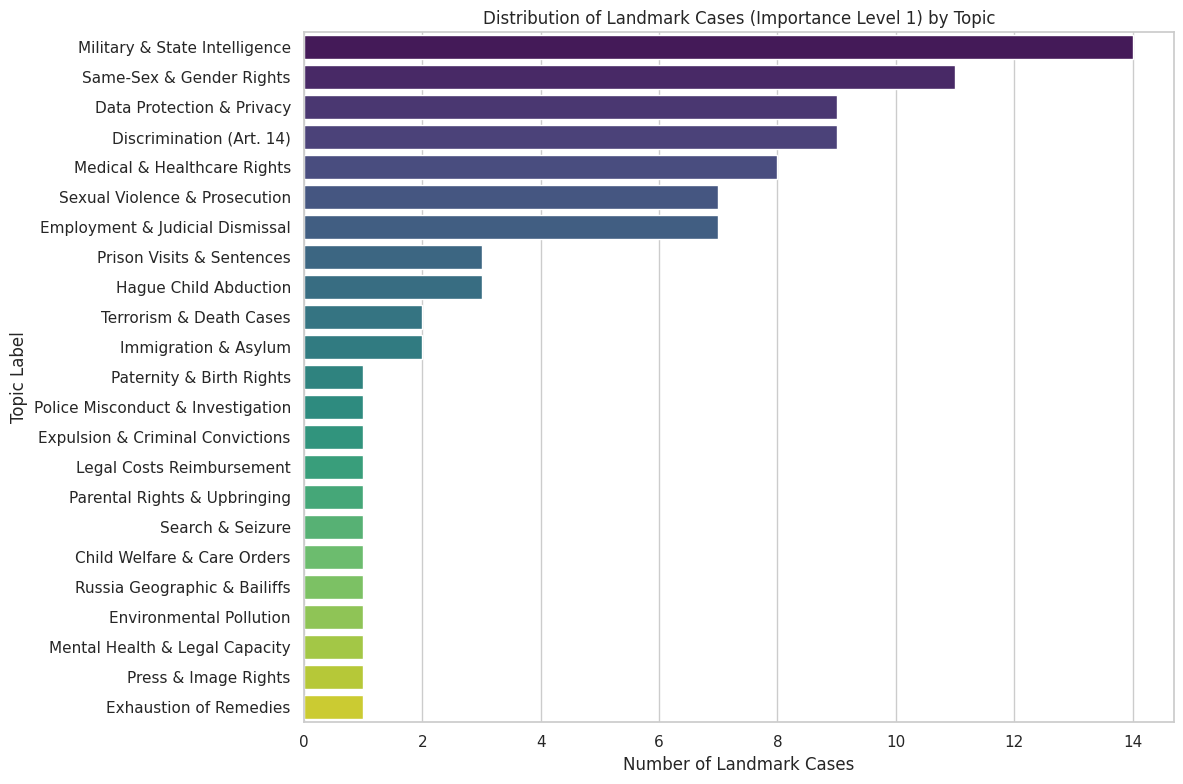

In [ ]:
# Filter for cases with importance level 1 (landmark cases)
landmark_cases = df_nmf_decided[df_nmf_decided['importance'] == '1']

# Group by topic and count the number of landmark cases in each topic
distribution = landmark_cases['topic_label'].value_counts().sort_values(ascending=False)

if not distribution.empty:
    print(f"Distribution of {len(landmark_cases)} landmark cases (importance level 1) across topics:")
    display(distribution.reset_index().rename(columns={'index': 'Topic', 'topic_label': 'Number of Landmark Cases'}))

    # Plotting the distribution
    plt.figure(figsize=(12, 8))
    sns.barplot(x=distribution.values, y=distribution.index, palette='viridis')
    plt.title('Distribution of Landmark Cases (Importance Level 1) by Topic')
    plt.xlabel('Number of Landmark Cases')
    plt.ylabel('Topic Label')
    plt.tight_layout()
    plt.show()
else:
    print("No landmark cases (importance level 1) found across any topic.")

In [ ]:
# Define global parameters for the analysis
TOP_N_CASES = 5  # Number of top cases to display per topic
HUDOC_BASE = "https://hudoc.echr.coe.int/eng#{{%22itemid%22:[%22{iid}%22]}}" # Base URL for HUDOC
all_results = [] # List to store all collected results

print("Beginning detailed analysis of landmark cases in top topics...")

# Ensure topic_labels is a mapping from integer index to string label

reverse_topic_labels = {v: k for k, v in topic_labels.items()}

for topic_label_name in top_3_topics:
    topic_idx = reverse_topic_labels.get(topic_label_name)
    if topic_idx is None:
        print(f"Warning: Topic label '{topic_label_name}' not found in topic_labels. Skipping.")
        continue

    # ------------------------------------------------------------------
    # Step 2: Get ALL cases assigned to this topic (not just landmarks)
    # ------------------------------------------------------------------
    mask_all_topic = df_nmf_decided['topic_label'] == topic_label_name
    df_all_topic   = df_nmf_decided[mask_all_topic].copy()

    # Get landmark cases in this topic separately for count reporting
    df_landmark_topic = df_all_topic[df_all_topic['importance'] == '1']

    if df_all_topic.empty:
        print(f"⚠️  No cases found for topic: {topic_label_name}")
        continue

    # ------------------------------------------------------------------
    # Step 3: Extract topic weights from W_decided for all topic cases
    # ------------------------------------------------------------------
    mask_for_W = mask_all_topic  # same boolean mask, same row alignment as W_decided
    topic_weights = W_decided[mask_for_W, topic_idx]  # shape: (n_cases_in_topic,)

    # Attach weights back to df
    df_all_topic = df_all_topic.copy()
    df_all_topic['topic_weight'] = topic_weights

    # ------------------------------------------------------------------
    # Step 4: Rank ALL cases by topic weight descending
    # ------------------------------------------------------------------
    df_all_topic_ranked = df_all_topic.sort_values('topic_weight', ascending=False)

    # ------------------------------------------------------------------
    # Step 5: Collect top N cases
    # ------------------------------------------------------------------
    print(f"\n{'─'*70}")
    print(f"📌 Topic: {topic_label_name}  (Index: {topic_idx})")
    print(f"   Total cases in topic : {len(df_all_topic)}")
    print(f"   Landmark cases       : {len(df_landmark_topic)}")
    print(f"   Top {TOP_N_CASES} most representative cases (by topic weight):")
    print(f"{'─'*70}")

    for rank, (_, row) in enumerate(df_all_topic_ranked.head(TOP_N_CASES).iterrows(), 1):
        # Modified to show the exact importance level
        importance_level_str = f"Importance: {row.get('importance', 'Unknown')}"
        hudoc_url   = HUDOC_BASE.format(iid=row.get('itemid', ''))
        print(f"  {rank}. [{row['topic_weight']:.4f}] {importance_level_str}")
        print(f"     Case   : {row.get('title', row.get('docname', 'Unknown'))}")
        print(f"     ItemID : {row.get('itemid', 'Unknown')}")
        print(f"     Outcome: {row.get('finding', 'Unknown')}  |  Year: {row.get('year', 'Unknown')})")
        print(f"     URL    : {hudoc_url}")
        print()

        all_results.append({
            'rank_in_topic'   : rank,
            'topic_label'     : topic_label_name,
            'topic_index'     : topic_idx,
            'topic_weight'    : round(row['topic_weight'], 4),
            'is_landmark'     : row.get('importance', 'Unknown'), # Changed to show actual importance level
            'title'           : row.get('title', row.get('docname', 'Unknown')),
            'itemid'          : row.get('itemid', 'Unknown'),
            'finding'         : row.get('finding', 'Unknown'),
            'year'            : row.get('year', 'Unknown'),
            'hudoc_url'       : hudoc_url,
        })


# Save the results to CSV
df_all_results.to_csv(f"{SAVE_PATH}rq2_landmark_cases_top_topics.csv", index=False)
print(f"Results saved to {SAVE_PATH}rq2_landmark_cases_top_topics.csv")

Beginning detailed analysis of landmark cases in top topics...


NameError: name 'topic_labels' is not defined

In [ ]:
import numpy as np

# 1. Get the top 3 topics with the most landmark cases
top_3_topics = distribution.head(3).index.tolist()

print("\n--- Top 3 Topics with Most Landmark Cases ---")

results = []

# Ensure topic_labels is a mapping from integer index to string label


# Reverse map topic_label strings to topic_idx integers for W_decided access
# Create a reverse mapping for topic_labels if not already available
# reverse_topic_labels = {v: k for k, v in topic_labels.items()}

for topic_label_name in top_3_topics:
    topic_idx = reverse_topic_labels.get(topic_label_name)
    if topic_idx is None:
        print(f"Warning: Topic label '{topic_label_name}' not found in topic_labels. Skipping.")
        continue

    print(f"\nTopic: {topic_label_name} (Index: {topic_idx})")

    # Filter landmark cases belonging to this specific topic
    current_topic_landmark_cases_df = df_nmf_decided[
        (df_nmf_decided['importance'] == '1') &
        (df_nmf_decided['topic_label'] == topic_label_name)
    ].copy()

    if current_topic_landmark_cases_df.empty:
        print(f"  No landmark cases found for this topic.")
        continue

    # Get the indices of these cases in the original df_nmf_decided for W_decided lookup
    original_indices = current_topic_landmark_cases_df.index

    # Get the topic weights for this specific topic (column `topic_idx`) for these cases
    # Need to map the original_indices from df_nmf_decided to the row indices of W_decided
    # df_nmf_decided was created by filtering df_nmf, so its index might not be contiguous.
    # W_decided rows correspond directly to df_nmf_decided rows (after filtering for decided cases).
    # So, we need the row numbers of current_topic_landmark_cases_df within df_nmf_decided.

    # Get boolean mask for `df_nmf_decided` to align with `W_decided`
    mask_for_topic_cases = (
        (df_nmf_decided['importance'] == '1') &
        (df_nmf_decided['topic_label'] == topic_label_name)
    )

    # Extract topic weights for these cases from W_decided
    weights_for_this_topic = W_decided[mask_for_topic_cases, topic_idx]

    # Find the case with the maximum weight for this topic
    if weights_for_this_topic.size > 0:
        max_weight_index_in_selection = np.argmax(weights_for_this_topic)
        most_representative_case = current_topic_landmark_cases_df.iloc[max_weight_index_in_selection]

        results.append({
            'Topic Label': topic_label_name,
            'Topic Index': topic_idx,
            'Most Representative Case Title': most_representative_case['title'],
            'Most Representative Case ItemID': most_representative_case['itemid'],
            'Topic Weight': weights_for_this_topic[max_weight_index_in_selection],
            'Findings': most_representative_case['finding'], # Added 'Findings'
            'Year': most_representative_case['year'],         # Added 'Year'
            'Importance Level': most_representative_case['importance'] # Added 'Importance Level'
        })
        print(f"  Most Representative Case: {most_representative_case['title']} (ItemID: {most_representative_case['itemid']})")
        print(f"  Topic Weight: {weights_for_this_topic[max_weight_index_in_selection]:.4f}")
    else:
        print("  No cases with positive topic weight found for this topic.")

# Display results in a DataFrame for better readability
if results:
    df_final_results = pd.DataFrame(results)
    print("\n--- Final Results ---")
    display(df_final_results)
else:
    print("No results to display.")


--- Top 3 Topics with Most Landmark Cases ---

Topic: Military & State Intelligence (Index: 36)
  Most Representative Case: CASE OF EL-MASRI v. "THE FORMER YUGOSLAV REPUBLIC OF MACEDONIA" (ItemID: 001-115621)
  Topic Weight: 0.3485

Topic: Same-Sex & Gender Rights (Index: 24)
  Most Representative Case: CASE OF SCHALK AND KOPF v. AUSTRIA (ItemID: 001-99605)
  Topic Weight: 0.3632

Topic: Data Protection & Privacy (Index: 35)
  Most Representative Case: CASE OF BREYER v. GERMANY (ItemID: 001-200442)
  Topic Weight: 0.4336

--- Final Results ---


,Topic Label,Topic Index,Most Representative Case Title,Most Representative Case ItemID,Topic Weight,Findings,Year,Importance Level
0,Military & State Intelligence,36,"CASE OF EL-MASRI v. ""THE FORMER YUGOSLAV REPUB...",001-115621,0.348525,Violation,2012,1
1,Same-Sex & Gender Rights,24,CASE OF SCHALK AND KOPF v. AUSTRIA,001-99605,0.363224,No Violation,2010,1
2,Data Protection & Privacy,35,CASE OF BREYER v. GERMANY,001-200442,0.433594,No Violation,2020,1


**Analysis**

We identified the most representative landmark case from each of the three topics with the highest concentration of importance level 1 cases, using the highest NMF topic weight as the selection criterion. The case with the highest topic weight is the one whose text most strongly characterises that topic's vocabulary profile, making it the natural anchor for close reading to understand what legal substance the topic is capturing.

The three cases identified are:

**El-Masri v. The Former Yugoslav Republic of Macedonia (App. no. 39630/09, Grand Chamber, 2012)** is the most representative case in the Military & State Intelligence topic and a landmark Grand Chamber judgment on extraordinary rendition. The case concerned Khaled El-Masri, a German national of Lebanese origin who was detained by Macedonian authorities at the border, detained and prohibited from communication at a hotel in Skopje, transferred to CIA custody, and subsequently flown to Afghanistan where he was held in a secret detention facility for several months before being released without charge. The Grand Chamber found violations of Articles 3, 5, 8, and 13, making this the first time the Court explicitly condemned a European state's complicity in the CIA extraordinary rendition programme.

The Article 8 analysis operates across three dimensions. The first and most direct finding was that the interference with El-Masri's private life was not "in accordance with the law" under Article 8(2). Macedonia's detention of the applicant and his transfer to CIA custody had no basis in domestic law, and the state's invocation of national security was rejected as insufficient to override Convention rights in the absence of any accessible or foreseeable legal framework. The Court's position is that state intelligence operations cannot function as a blanket shield against Convention scrutiny, the legality requirement under Article 8(2) applies regardless of the security context, and covert conduct that cannot be grounded in domestic law fails at the first condition without the Court needing to reach proportionality.

The second dimension concerns family life. The enforced disappearance deprived El-Masri's wife and children of mutual enjoyment of each other's company for months without any knowledge of his whereabouts. The Court treated this as a separate interference with family life, distinct from the private life analysis, with private life capturing the interference with personal autonomy and identity and family life capturing the relational harm to those left behind.

The third dimension is procedural. The Court found that Macedonia failed its positive obligation under Article 8 to conduct a prompt, independent, and thorough investigation into what had happened to El-Masri. This procedural obligation arises under Article 8 itself and operates independently of the substantive unlawfulness: the failure to investigate once the events came to light was a freestanding Article 8 violation regardless of whether the original conduct was also found unlawful.
The absence of any margin of appreciation analysis is worth noting, in contrast to Schalk and Kopf (2010). Where Schalk and Kopf turned on how much discretion states retain in an area of evolving consensus, El-Masri involves conduct so severe that no balancing exercise takes place. For the classification model, this explains why the Military & State Intelligence topic is so uniformly violation-dominant in the outcome distribution, whereby cases of this nature do not sit near any decision boundary because the Court's doctrinal position removes state discretion entirely once the threshold of absolute rights violation is crossed.

One structural point remains relevant. The Article 8 findings in El-Masri are partly derivative having established violations of Articles 3 and 5, the Court held that the same conduct also unlawfully interfered with Article 8. The judgment's vocabulary driving the NMF topic weight is therefore drawn from reasoning across all violated articles rather than from Article 8 specific proportionality language, meaning the topic is anchored in the vocabulary of rendition, secret detention, and state accountability rather than the proportionality and necessity reasoning that characterises most Article 8 jurisprudence.


**Schalk and Kopf v. Austria (App. no. 30141/04, 2010)**, the Court made a landmark doctrinal step while simultaneously finding no violation, a tension that runs through the entire judgment and has direct implications for how the Same-Sex & Gender Rights topic behaves in the classification model.

Prior to this case, the Court had consistently held that same-sex relationships fell within "private life" under Article 8 but not "family life." In paragraph 94, the Court departed from that position, holding that it would be "artificial to maintain the view that, in contrast to a different-sex couple, a same-sex couple cannot enjoy 'family life'." In reaching this conclusion, the Court drew on a line of cases including Marckx v. Belgium (1979), Keegan v. Ireland (1994), and Lebbink v. The Netherlands (2004), which had progressively established that the notion of family life is not confined to marriage-based relationships and encompasses stable de facto partnerships. The Court also referenced Article 9 of the EU Charter of Fundamental Rights, which had removed the explicit "men and women" formulation from the right to marry, treating this as evidence of evolving European standards and using it as a comparative interpretive tool.

Despite this doctrinal advance, the Court found no violation. Its reasoning in paragraphs 96 to 109 turns on the margin of appreciation doctrine, conducting a comparative survey, the Court found that only six out of forty-seven Convention states permitted same-sex marriage at the time, placing the area in the category of "evolving rights with no established consensus" where states retain the widest legislative discretion on timing and form. The three dissenting judges argued that having recognised same-sex couples as falling within family life, the Court was logically obliged to find a violation given Austria's complete absence of any legal recognition framework before 2010. The majority disagreed, treating the margin of appreciation as sufficient to absorb the doctrinal recognition without producing a remedial obligation. This illustrates a core tension in Article 8 jurisprudence, the Court can acknowledge that a fundamental right applies while simultaneously granting states significant discretion in how and when they fulfil it.

It is also worth noting that Schalk and Kopf was a First Section judgment rather than a Grand Chamber case, which gives it lower formal precedential weight than a Grand Chamber ruling despite its landmark status. The subsequent decision in Oliari and Others v. Italy (Applications nos. 18766/11 and 36030/11,2015) moved beyond it by finding a violation where Italy provided no legal framework for same-sex couple recognition whatsoever, suggesting the margin of appreciation was narrowing as European consensus developed within the dataset period. The near-balanced 55/45 no-violation split in the Same-Sex & Gender Rights topic likely reflects this trajectory, whereby earlier cases deferring to state discretion under the Schalk and Kopf margin, and later cases finding violations as consensus crystallised.

Finally, the no-violation outcome in Schalk and Kopf despite its landmark doctrinal finding offers a concrete explanation for why no-violation cases are structurally difficult to classify in the model. The judgment contains extensive Article 8 language typically associated with violation cases in the dataset, including family life, discrimination, sexual orientation, proportionality, and margin of appreciation, yet the outcome is no violation. The vocabulary of no-violation cases is not linguistically distinct from violation cases, it is the legal reasoning and doctrinal context that differs, not the words themselves. Schalk and Kopf makes this visible because the same terms appear, but their function in the judgment is to justify restraint rather than intervention, a distinction the TF-IDF and NMF representations cannot capture and which directly contributes to the residual misclassification visible in the confusion matrix.

**Breyer v. Germany (App. no. 50001/12, 30 January 2020)** is the most representative case in the Data Protection & Privacy topic and one of the few landmark no-violation findings in the dataset. The case concerned a legal obligation under the German Telecommunications Act requiring telecommunications providers to register all prepaid SIM card users and retain their subscriber data. The applicants argued that this compulsory storage of personal data violated Article 8, and the Court found no violation by six votes to one.

The Article 8 analysis follows the standard three-stage structure. On interference, the Court accepted that the compulsory storage of subscriber data constituted an interference with private life but characterised it as limited in nature, drawing a doctrinal distinction between basic subscriber data identifying who owns a phone and traffic or content data revealing who was contacted and what was said. This gradation of interference severity is significant: not all data retention measures engage Article 8 with equal intensity, and the Court's treatment of subscriber data as a less severe intrusion than communications content directly informed how demanding the proportionality assessment would be.

On necessity in a democratic society, the legitimate aims were national security and the prevention of crime, both falling within Article 8(2). The Court found a pressing social need for the measure and accepted that the interference was proportionate given its limited scope. Central to this assessment was whether the domestic framework contained adequate minimum safeguards against abuse. The Court treats safeguards not merely as one factor within the proportionality analysis but as a near-independent doctrinal requirement in data retention cases, asking specifically who can access the retained data, under what conditions access is permitted, whether independent oversight exists, and whether individuals have any means of challenge or notification. These structural controls are the Court's response to the inherent risk that bulk data collection regimes, even limited ones, create opportunities for misuse that proportionality alone cannot address.

In Breyer, the Court accepted the German "double-door concept" as meeting this requirement. Under this framework, subscriber data is held by private telecommunications companies rather than directly by the state, and state authorities may only access it upon request subject to specified statutory conditions. The majority found that this two-stage architecture, combined with the availability of review under general administrative law and supervision by data protection authorities, provided sufficient safeguards to prevent arbitrary interference. The dissenting judge Ranzoni rejected this conclusion, arguing that the double-door mechanism was structurally deficient because access did not require authorisation by a judicial or otherwise independent authority, and because individuals were not notified when their data was retrieved, leaving victims of unlawful access with no means of seeking review. This disagreement between majority and dissent is essentially a disagreement about what minimum safeguards require in the context of administrative data retention, and it maps directly onto the distinction between the outcome in Breyer and the violation findings in Roman Zakharov v. Russia (2015) and Big Brother Watch v. UK (2021), where the absence of independent oversight of access to intercepted data was decisive.

On the margin of appreciation, the Court articulated the calibration principle that the margin tends to be narrower where the right at stake is crucial to the individual's effective enjoyment of intimate or key rights, but wider where no consensus exists among Council of Europe member states as to the relative importance of the interest at stake or how best to protect it. In 2020, European states had not converged on a uniform approach to bulk subscriber data retention, and the Court found that Germany had not exceeded the wide margin available to it in this area.
The contrast with El-Masri is analytically instructive for understanding what the Data Protection & Privacy topic is capturing. Where El-Masri involved physical state conduct through secret detention and extraordinary rendition with no legal basis whatsoever, the interference in Breyer is entirely bureaucratic, regulated, and technological, operating within a statutory framework subject to procedural constraints and independent oversight. The NMF topic clusters Breyer-type cases together because they share a distinct lexical profile built around telecommunications, data, service provider, subscriber, and metadata vocabulary that is absent from cases like El-Masri, reflecting the emergence of digital privacy as a distinct sub-area of Article 8 jurisprudence within the dataset period.
For the classification model, Breyer illustrates the vocabulary overlap problem in its sharpest form. The judgment is dense with Article 8 language including interference, surveillance, data protection, fundamental rights, privacy, proportionality, and safeguards, yet the outcome is no violation. The same vocabulary that signals violation in Roman Zakharov and El-Masri here functions to justify why the state's administrative procedures were sufficient rather than to condemn their absence. A bag-of-words or topic weight representation cannot distinguish between these two uses of the same terms because it captures the presence of vocabulary but not the legal reasoning that determines its function in the judgment. This is a genuine limitation of the TF-IDF and NMF approaches used in this study and suggests that capturing the sentence-level legal reasoning distinguishing proportionate from disproportionate interference would require representations that encode contextual meaning rather than word frequency alone.






**Conclusion**

RQ2 set out to identify the dominant themes in Article 8 cases decided between 2010 and 2023. The NMF clustering model, configured at k=40, revealed a thematically rich and legally varied landscape. The dominant clusters span four broad areas, procedural and remedial matters (legal costs, pecuniary damages, default interest), state security and surveillance (military intelligence, covert surveillance, batch deportation applications), family and personal life disputes (child welfare and care orders, parental rights, expulsion of settled family members), and emerging rights domains (same-sex and gender recognition, data protection and retention, mental health and legal capacity).

The outcome distribution across these clusters is highly uneven and carries analytical significance. Several topics record 100% violation rates, notably all four Article 41 remedial clusters and the Russia-specific groupings. This pattern is not substantively meaningful, it reflects structural leakage, because Article 41 language on damages and costs appears only in violation judgments, and because Russia's disproportionate representation in the dataset amplifies the violation signal for any cluster that concentrates Russian cases. The feature importance analysis confirms this, the highest positive LinearSVC coefficients on the violation side belong to these leakage and Russia-specific topics, with magnitudes reaching approximately 1.35.

More interpretively interesting are the contested and near-balanced clusters. The same-sex and gender recognition topic shows a close split, which is consistent with the absence of any European consensus on same-sex family rights during this period, a doctrinal condition the Court itself acknowledged in Schalk and Kopf v. Austria (2010) when it declined to read Article 8 as imposing a positive obligation to grant legal recognition to same-sex couples. Child welfare and care orders present a different tension, while the EDA for the full dataset suggested a predominantly no-violation distribution for child welfare matters, the NMF cluster captures a more divided picture, likely because the topic weight aggregates cases at different procedural stages and across varying national child protection frameworks where the margin of appreciation operates differently. Terrorism and national security cases, and search and seizure clusters, sit in similarly contested territory, reflecting the proportionality and necessity assessments that characterise those domains and make outcome prediction structurally harder.
Using the 40 topic weights as inputs, the classification models performed well. Logistic Regression and the linear SVM both achieved weighted F1 scores of approximately 0.895, while Naive Bayes lagged at 0.797. The confusion matrix shows the models identified no-violation and violation cases at roughly equal rates, suggesting the strong performance reflects genuine predictive structure in the topics rather than the model simply defaulting to the more common violation outcome. One limitation is that the models tend to express more confidence in their predictions than the underlying legal complexity warrants, pushing most predictions toward very high or very low probability rather than reflecting the genuine uncertainty in borderline cases.

The close reading of landmark cases within three high-weight topics illustrates where the thematic representation reaches its interpretive limits. In El-Masri v. The Former Yugoslav Republic of Macedonia (2012), the military and state intelligence cluster correctly identifies a clear violation, grounded in the absolute prohibition on rendition and secret detention and the state's positive obligation to investigate. In Schalk and Kopf, the same-sex and gender cluster is associated with a no-violation outcome, yet the judgment's own reasoning is forward-looking, extending family life protection to same-sex couples while denying a positive obligation to legislate. The legal vocabulary of family life, private life, and margin of appreciation is shared with violation judgments; what differs is the Court's normative conclusion, not the doctrinal language. In Breyer v. Germany (2020), the data retention cluster again involves a no-violation finding, but only after a detailed proportionality assessment in which the double-door access mechanism was accepted as an adequate safeguard. A classifier operating on topic weights cannot distinguish the presence of safeguard vocabulary from its legal sufficiency. These cases collectively explain why residual misclassification persists even at high overall accuracy: the model captures thematic salience but cannot resolve the legal reasoning function that maps shared vocabulary onto divergent outcomes.

In answer to RQ2, the dominant themes in Article 8 cases are substantively diverse, ranging from family reunification and child protection to state surveillance, data retention, and identity rights, but the outcome-predictive signal within those themes is unevenly distributed. Leakage and respondent state concentration artificially inflate the apparent predictability of certain clusters. The genuinely contested clusters, particularly same-sex rights, child welfare, and search and seizure, reflect live doctrinal disagreements within the Court and across member states, and it is precisely in those clusters that the limits of topic-based classification are most visible.




#**RQ3: Exploring Region bias**

Does a model trained on Eastern European Article 8 cases generalise to Western European cases, and vice versa?
* Input: Law_clean
* Model: SVM
* Output: Findings

##Define Region

Groups derived from **RQ1 Metadata Arm** filtered country chart
(min. case threshold applied, single-country entries only).

For a list of the Western European countries, we refer to a list by the International Criminal Court:
https://asp.icc-cpi.int/states-parties/western-european-and-other-states (excluding Canada, New Zealand, Australia)

For a list of the Eastern European countries, we refer to a list by the International Criminal Court:
https://asp.icc-cpi.int/states-parties/eastern-european-states

Turkey has been excluded from the ICC list, which we will explore in a subsequent section.

In [ ]:
# ============================================================
# RQ3 — Geographic Generalisation Experiment
# Step 1: Group Assignment & Data Split
# ============================================================
RQ3_EASTERN_TRAIN = [
    'SVK',   # Slovakia
    'MDA',   # Moldova
    'UKR',   # Ukraine
    'HRV',   # Croatia
    'BGR',   # Bulgaria
    'HUN',   # Hungary
    'LVA',   # Latvia
    'ROU',   # Romania
    'POL',   # Poland
    'SRB',   # Serbia
    'SVN',   # Slovenia
    'LTU',   # Lithuania
    'ALB',   # Albania
    'MKD',   # North Macedonia
    'BIH',   # Bosnia and Herzegovina
    'EST',   # Estonia
    'GEO',   # Georgia
    'MNE',   # Montenegro
    'CZE',   # Czech Republic
    'ARM',   # Armenia
    'AZE',   # Azerbaijan
    'RUS',   # Russia
]

# --- WESTERN GROUP ---
RQ3_WESTERN_TEST = [
    'DNK',   # Denmark
    'DEU',   # Germany
    'SWE',   # Sweden
    'NOR',   # Norway
    'FRA',   # France
    'CHE',   # Switzerland
    'AUT',   # Austria
    'GBR',   # United Kingdom
    'ITA',   # Italy
    'SMR',   # San Marino
    'ISL',   # Iceland
    'BEL',   # Belgium
    'LUX',   # Luxembourg
    'ESP',   # Spain
    'FIN',   # Finland
    'AND',   # Andorra
    'NLD',   # Netherlands
    'PRT',   # Portugal
    'IRL',   # Ireland
    'GRC',   # Greece
    'MLT',   # Malta
]

# ── Summary ──────────────────────────────────────────────────
print("=" * 62)
print("RQ3 Group Definitions")
print("=" * 62)
print(f"EASTERN train group : {len(RQ3_EASTERN_TRAIN)} countries → {RQ3_EASTERN_TRAIN}")
print(f"WESTERN test  group : {len(RQ3_WESTERN_TEST)} countries → {RQ3_WESTERN_TEST}")


RQ3 Group Definitions
EASTERN train group : 22 countries → ['SVK', 'MDA', 'UKR', 'HRV', 'BGR', 'HUN', 'LVA', 'ROU', 'POL', 'SRB', 'SVN', 'LTU', 'ALB', 'MKD', 'BIH', 'EST', 'GEO', 'MNE', 'CZE', 'ARM', 'AZE', 'RUS']
WESTERN test  group : 21 countries → ['DNK', 'DEU', 'SWE', 'NOR', 'FRA', 'CHE', 'AUT', 'GBR', 'ITA', 'SMR', 'ISL', 'BEL', 'LUX', 'ESP', 'FIN', 'AND', 'NLD', 'PRT', 'IRL', 'GRC', 'MLT']


In [ ]:
# ── Data Split ───────────────────────────────────────────────
df_rq3_base = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()

def assign_rq3_group(code):
    if code in RQ3_EASTERN_TRAIN: return 'Eastern'
    if code in RQ3_WESTERN_TEST:  return 'Western'
    return None

df_rq3_base['rq3_group'] = df_rq3_base['respondent_country'].apply(assign_rq3_group)

df_train    = df_rq3_base[df_rq3_base['rq3_group'] == 'Eastern'].copy()
df_test     = df_rq3_base[df_rq3_base['rq3_group'] == 'Western'].copy()

# ── Case count report ────────────────────────────────────────
print("\n" + "=" * 62)
print("RQ3 Dataset Summary")
print("=" * 62)
print(f"\nTRAIN — Eastern group: {len(df_train)} cases")
print(df_train['finding'].value_counts().to_string())
print(f"\nTEST  — Western group: {len(df_test)} cases")
print(df_test['finding'].value_counts().to_string())

# ── Sanity check: no country overlap ─────────────────────────
overlap = set(df_train['respondent_country'].unique()) & set(df_test['respondent_country'].unique())
print(f"\n{'✅' if not overlap else '❌'} Country overlap: {overlap or 'None — clean split'}")


RQ3 Dataset Summary

TRAIN — Eastern group: 941 cases
finding
Violation       809
No Violation    132

TEST  — Western group: 280 cases
finding
No Violation    143
Violation       137

✅ Country overlap: None — clean split


##Generalisation - TF-IDF (Applying East to West & vice versa)

In [ ]:
# ============================================================
# RQ3 — Geographic Generalisation Experiment
# Step 2: Model Training & Cross-Group Testing
# Input : lawtextclean (V3 — leakage-controlled)
# Models: Naive Bayes (ComplementNB) + SVM (CalibratedLinearSVC)
# Design: Train East → Test West  |  Train West → Test East
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (f1_score, accuracy_score,
                              precision_score, recall_score,
                              classification_report)
import pandas as pd

# ── Features & target ────────────────────────────────────────
TEXT_COL  = 'law_text_clean'
TARGET    = 'finding'
STOPWORDS = custom_law_clean_stop_words   # from existing stopword cell

# Drop rows with missing text or target
df_train_clean = df_train.dropna(subset=[TEXT_COL, TARGET]).copy()
df_test_clean  = df_test.dropna(subset=[TEXT_COL, TARGET]).copy()

X_east = df_train_clean[TEXT_COL];  y_east = df_train_clean[TARGET]
X_west = df_test_clean[TEXT_COL];   y_west = df_test_clean[TARGET]

print(f"Eastern train set : {len(X_east)} cases | {y_east.value_counts().to_dict()}")
print(f"Western test  set : {len(X_west)} cases | {y_west.value_counts().to_dict()}")

# ── Model definitions ─────────────────────────────────────────
RQ3_CLASSIFIERS = {
    'Naive Bayes': ComplementNB(),
    'SVM': CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
    ),
}

TFIDF_PARAMS = dict(
    stop_words=STOPWORDS,
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True,
)

# ── Experiment runner ─────────────────────────────────────────
def run_generalisation(X_train, y_train, X_test, y_test,
                       train_label, test_label):
    rows = []
    for clf_name, clf in RQ3_CLASSIFIERS.items():
        pipeline = Pipeline([
            ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
            ('clf',   clf),
        ])
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        rows.append({
            'Direction':  f"{train_label} → {test_label}",
            'Classifier': clf_name,
            'F1_macro':   round(f1_score(y_test, y_pred, average='macro'), 4),
            'Accuracy':   round(accuracy_score(y_test, y_pred), 4),
            'Precision_macro':  round(precision_score(y_test, y_pred, average='macro', zero_division=0), 4),
            'Recall_macro':     round(recall_score(y_test, y_pred, average='macro'), 4),
        })

        print(f"\n{'─'*60}")
        print(f"  {train_label} → {test_label}  |  {clf_name}")
        print(f"{'─'*60}")
        print(classification_report(y_test, y_pred,
                                    target_names=['No Violation', 'Violation']))
    return rows

# ── Run both directions ───────────────────────────────────────
print("=" * 60)
print("RQ3 GENERALISATION EXPERIMENT — lawtextclean")
print("=" * 60)

results = []
results += run_generalisation(X_east, y_east, X_west, y_west,
                               train_label='Eastern', test_label='Western')
results += run_generalisation(X_west, y_west, X_east, y_east,
                               train_label='Western', test_label='Eastern')

# ── Results table ─────────────────────────────────────────────
df_rq3_results = pd.DataFrame(results).sort_values('F1_macro', ascending=False).reset_index(drop=True)

print("\n" + "=" * 60)
print("RQ3 RESULTS — Generalisation F1 (macro)")
print("=" * 60)
display(df_rq3_results)

# ── Save ──────────────────────────────────────────────────────
df_rq3_results.to_csv(f"{SAVE_PATH}rq3_generalisation_results.csv", index=False)
print(f"Results saved to {SAVE_PATH}")

Eastern train set : 941 cases | {'Violation': 809, 'No Violation': 132}
Western test  set : 280 cases | {'No Violation': 143, 'Violation': 137}
RQ3 GENERALISATION EXPERIMENT — lawtextclean

────────────────────────────────────────────────────────────
  Eastern → Western  |  Naive Bayes
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

No Violation       0.67      0.11      0.19       143
   Violation       0.50      0.94      0.66       137

    accuracy                           0.52       280
   macro avg       0.59      0.53      0.42       280
weighted avg       0.59      0.52      0.42       280


────────────────────────────────────────────────────────────
  Eastern → Western  |  SVM
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

No Violation       0.85      0.68      0.75       143
   Violation       0.72      0.88      0.79       137

    accura

,Direction,Classifier,F1_macro,Accuracy,Precision_macro,Recall_macro
0,Western → Eastern,SVM,0.8546,0.9299,0.8546,0.8546
1,Eastern → Western,SVM,0.7735,0.7750,0.7869,0.7771
2,Western → Eastern,Naive Bayes,0.7724,0.8969,0.7924,0.7562
3,Eastern → Western,Naive Bayes,0.4241,0.5179,0.5853,0.5267


Results saved to /content/


**Analysis**

Evaluating our models requires a deliberate approach to our dataset's inherent class imbalance (982 Violations versus 283 No Violations), where raw accuracy can be a highly misleading metric of a model's goodness. As Akdemir notes in his study of US Supreme Court certiorari petitions, accuracy is an inadequate measure when dealing with severe class imbalance because a baseline "dummy classifier" that always predicts the majority class would achieve artificially high accuracy without actually learning anything. To address this, Akdemir (2023) prioritizes recall, the "completeness of retrieval", to minimize the cost of misclassifying rare, true positive observations, which in his context means avoiding false negatives.

For our Article 8 dataset, we similarly focus on non-accuracy metrics: precision (the "purity of retrieval," measuring the percentage of cases the model flagged as violations that actually were) and recall (measuring how many actual violations the model successfully caught). Since pushing recall up inherently drags precision down, we rely on the Macro F1 is our primary evaluation metric, similar to previous RQs. As mentioned, weighted F1 would allow the majority "Violation" class to dominate the score, effectively masking any poor performance on the "No Violations" class. Macro F1 avoids this by calculating the F1 score for each class independently and averaging them equally. This holds the model strictly accountable for both outcomes regardless of class imbalance, directly penalizing the majority-class bias that standard accuracy metrics often hide.

Furthermore, we selected the Linear Support Vector Machine (SVM) for this task because, while other models might offer marginally higher raw accuracy, the SVM allows us to rank features and extract interpretable weights to identify exactly which legal issues drive the Court's decisions. This approach builds upon the foundational work of Aletras et al. (2016), who demonstrated that SVMs trained on textual features (n-grams and topics) could successfully predict ECtHR decisions. However, while Aletras et al. treated the Court as a monolith, our cross-regional approach tests the robustness of these text-based predictors across jurisdictional boundaries.

Applying this metric framework, the cross-regional generalisation experiment reveals a stark asymmetry in predictive performance when models are applied across the Eastern and Western European jurisdictional divide:

**Eastern to Western Prediction:** Training the SVM on the Eastern European docket (941 cases) and testing on the Western European docket (280 cases) yields a Macro F1 score of 0.77.

**Western to Eastern Prediction:** Conversely, deploying the Western-trained SVM to predict Eastern European cases results in a substantially stronger Macro F1 score of 0.85.

This performance gap indicates that while the Western dataset contains sufficient doctrinal signal to predict Eastern outcomes effectively, the Eastern dataset fails to provide the model with the necessary features to accurately map Western jurisprudence.

This directional failure is even more pronounced when examining the Naive Bayes baseline classifier. The Eastern-trained Naive Bayes model completely collapses when applied to Western cases, plummeting to a Macro F1 score of 0.42. A closer look at the classification report exposes the root of this collapse: the model achieves a dismal 0.11 recall for "No Violation" cases, meaning it incorrectly assumes almost every Western case is a violation. Even the more robust Eastern-trained SVM struggles with this bias, correctly identifying only 68% of actual Western "No Violation" cases while achieving an 88% recall for actual "Violations."

This asymmetric generalisation failure highlights fundamentally divergent jurisprudential landscapes between the two blocs. As established in our earlier topic clustering, Eastern European Article 8 violations are heavily characterized by severe, systemic, and physical breaches of rights, such as inadequate detention conditions or covert surveillance. The algorithm learns that state interference in these contexts almost guarantees a violation. However, Western European cases focus more heavily on nuanced administrative disputes, technological privacy, and evolving social rights, where the respondent state is frequently granted a wider "margin of appreciation." Consequently, an Eastern-trained model is structurally blind to these nuanced balancing tests and blindly over-predicts violations when encountering routine procedural language in Western cases.

Generating Confusion Matrices for RQ3 Generalization Experiment (SVM)...
----------------------------------------------------------------------

--- Eastern -> Western ---


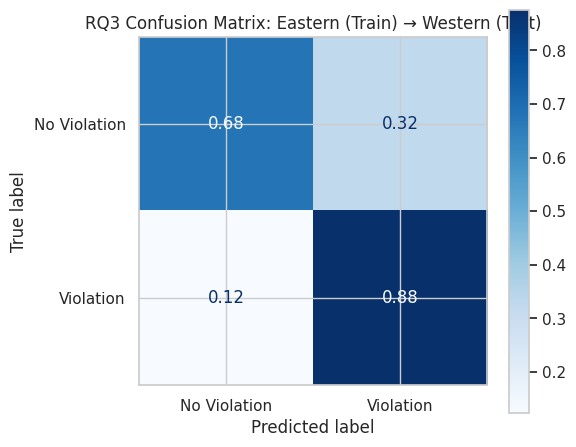

Confusion matrix saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq3_confusion_matrix_east_to_west.png

--- Western -> Eastern ---


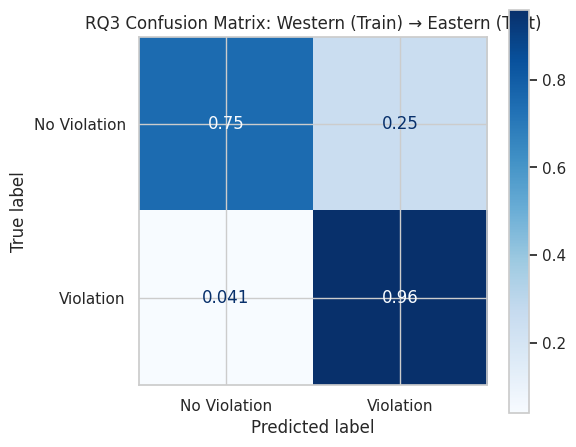

Confusion matrix saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq3_confusion_matrix_west_to_east.png

All confusion matrices for RQ3 Generalization Experiment (SVM) generated and saved.


In [ ]:
# ── Generate Confusion Matrices for SVM Generalization (RQ3) ──

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

print('Generating Confusion Matrices for RQ3 Generalization Experiment (SVM)...')
print('-' * 70)

# Re-define necessary parameters from cell UD_dgPxpFPYi
TEXT_COL  = 'law_text_clean'
TARGET    = 'finding'
STOPWORDS = custom_law_clean_stop_words # Assuming custom_law_clean_stop_words is defined

TFIDF_PARAMS = dict(
    stop_words=STOPWORDS,
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True,
)

# Ensure df_train_clean and df_test_clean are available

if 'df_art8' not in locals():
    print("Warning: df_art8 not found. Please ensure previous cells are run.")


df_rq3_base = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()

def assign_rq3_group(code):
    if code in RQ3_EASTERN_TRAIN: return 'Eastern'
    if code in RQ3_WESTERN_TEST:  return 'Western'
    return None

df_rq3_base['rq3_group'] = df_rq3_base['respondent_country'].apply(assign_rq3_group)

df_train    = df_rq3_base[df_rq3_base['rq3_group'] == 'Eastern'].copy()
df_test     = df_rq3_base[df_rq3_base['rq3_group'] == 'Western'].copy()

df_train_clean = df_train.dropna(subset=[TEXT_COL, TARGET]).copy()
df_test_clean  = df_test.dropna(subset=[TEXT_COL, TARGET]).copy()

X_east = df_train_clean[TEXT_COL];  y_east = df_train_clean[TARGET]
X_west = df_test_clean[TEXT_COL];   y_west = df_test_clean[TARGET]

# Define the SVM pipeline
svm_pipeline_rq3 = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
    )),
])

# 1. Eastern (Train) -> Western (Test)
print("\n--- Eastern -> Western ---")
svm_pipeline_rq3.fit(X_east, y_east)
y_pred_east_to_west = svm_pipeline_rq3.predict(X_west)

fig_ew, ax_ew = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_west, y_pred_east_to_west,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax_ew
)
ax_ew.set_title('RQ3 Confusion Matrix: Eastern (Train) → Western (Test)')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq3_confusion_matrix_east_to_west.png', dpi=150)
plt.show()
print(f'Confusion matrix saved to {SAVE_PATH}rq3_confusion_matrix_east_to_west.png')
# In this confusion matrix:
# - False Positive (FP): Actual is 'No Violation', Predicted is 'Violation'.
#   This means the model incorrectly identified a case as a 'Violation'.
# - False Negative (FN): Actual is 'Violation', Predicted is 'No Violation'.
#   This means the model failed to identify an actual 'Violation'.

# 2. Western (Train) -> Eastern (Test)
print("\n--- Western -> Eastern ---")
svm_pipeline_rq3.fit(X_west, y_west)
y_pred_west_to_east = svm_pipeline_rq3.predict(X_east)

fig_we, ax_we = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_east, y_pred_west_to_east,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax_we
)
ax_we.set_title('RQ3 Confusion Matrix: Western (Train) → Eastern (Test)')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq3_confusion_matrix_west_to_east.png', dpi=150)
plt.show()
print(f'Confusion matrix saved to {SAVE_PATH}rq3_confusion_matrix_west_to_east.png')
# In this confusion matrix:
# - False Positive (FP): Actual is 'No Violation', Predicted is 'Violation'.
#   This means the model incorrectly identified a case as a 'Violation'.
# - False Negative (FN): Actual is 'Violation', Predicted is 'No Violation'.
#   This means the model failed to identify an actual 'Violation'.

print('\n' + '=' * 70)
print('All confusion matrices for RQ3 Generalization Experiment (SVM) generated and saved.')

**Analysis**

These confusion matrices visually crystallize the performance asymmetry between the two regions. When the Eastern-trained model evaluates the Western docket, its precision collapses: it misclassifies 32% of actual "No Violation" cases as "Violations." The model is structurally predisposed to assume state fault, leading to a highly inflated False Positive rate.

In sharp contrast, the Western-trained model tested on the Eastern docket exhibits remarkable stability. It correctly identifies 96% of actual Violations and 75% of No Violations, maintaining a minimal False Negative rate of just 4.1%. The Western model possesses a sufficiently robust understanding of procedural balancing to handle Eastern cases, whereas the Eastern model lacks the vocabulary to appropriately identify justified state interference in the West.

Feature Importance


--- Analyzing Eastern-trained SVM model ---


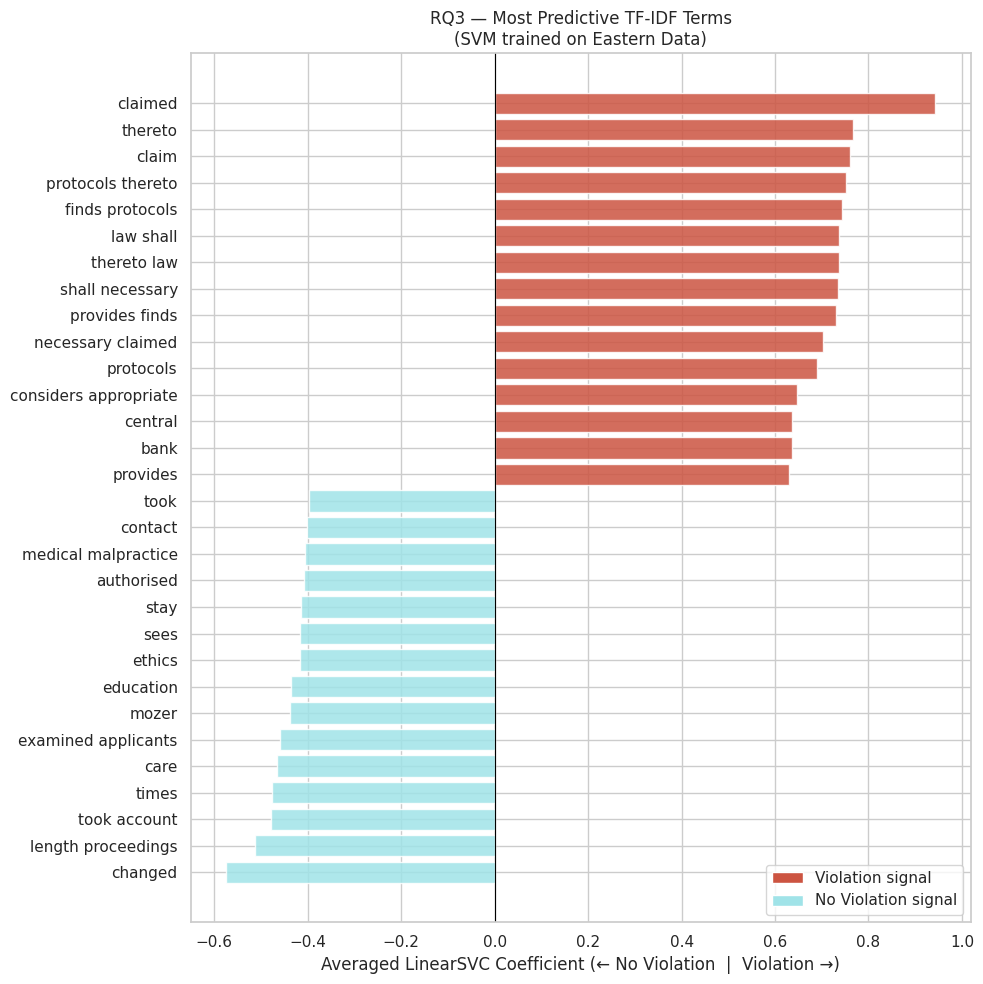

SVM feature importance chart for Eastern Data saved.

--- Analyzing Western-trained SVM model ---


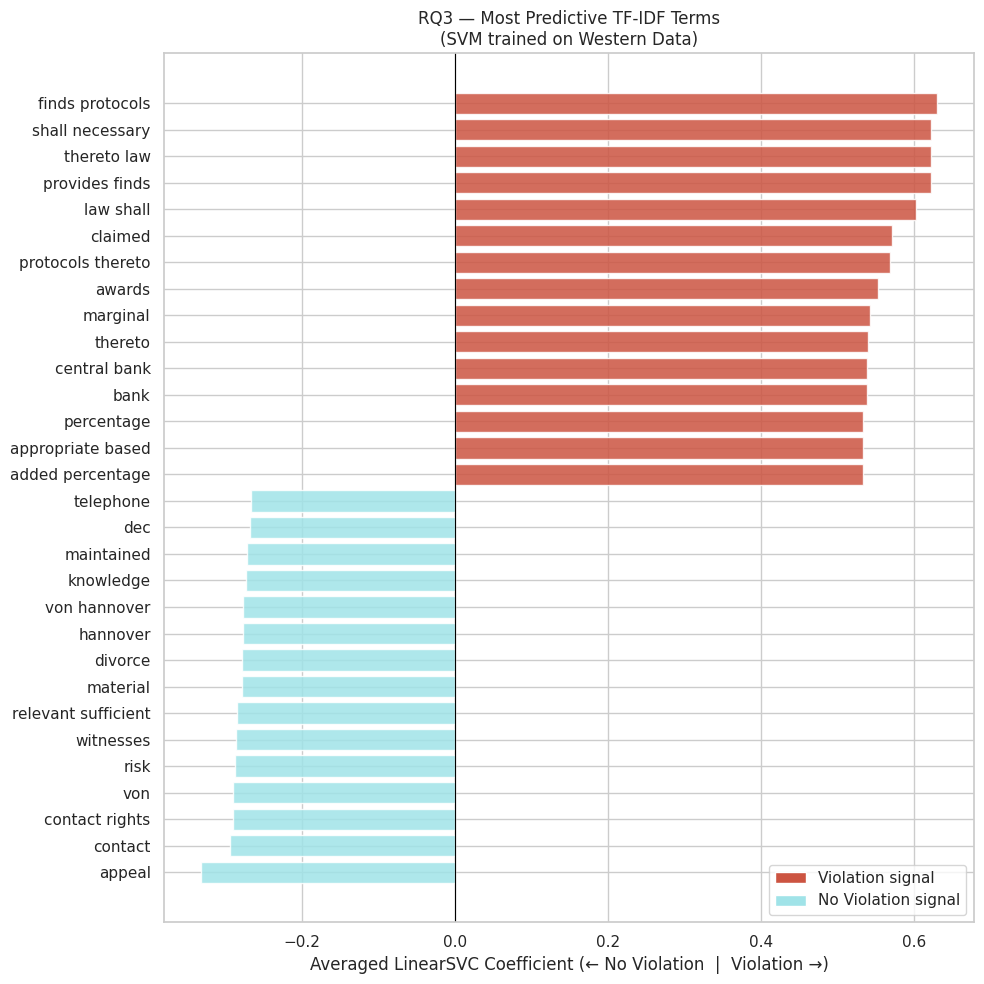

SVM feature importance chart for Western Data saved.

All feature importance diverging bar charts for RQ3 generated and saved.


In [ ]:
# ── Feature Importance — Diverging Coefficients for RQ3 Generalization ──
# Re-using TFIDF_PARAMS and RQ3_CLASSIFIERS from cell UD_dgPxpFPYi
# Re-using X_east, y_east, X_west, y_west from cell UD_dgPxpFPYi

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

n_top_words = 15 # Number of top words to display for each direction

def plot_diverging_coef(coef_series, title_suffix, filename_suffix):
    """Generates a diverging bar chart for coefficients."""
    top_violation    = coef_series.nlargest(n_top_words)
    top_no_violation = coef_series.nsmallest(n_top_words)

    diverging_df = pd.concat([
        top_violation.rename('coefficient'),
        top_no_violation.rename('coefficient')
    ]).sort_values()

    colors = [PALETTE['Violation'] if v > 0 else PALETTE['No Violation']
              for v in diverging_df.values]

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.barh(diverging_df.index, diverging_df.values,
            color=colors, alpha=0.85, edgecolor='white')
    ax.axvline(x=0, color='black', linewidth=0.8)
    ax.set_xlabel('Averaged LinearSVC Coefficient (← No Violation  |  Violation →)')
    ax.set_title(f'RQ3 — Most Predictive TF-IDF Terms\n(SVM trained on {title_suffix})', fontsize=12)

    legend_elements = [
        Patch(facecolor=PALETTE['Violation'],    label='Violation signal'),
        Patch(facecolor=PALETTE['No Violation'], label='No Violation signal')
    ]
    ax.legend(handles=legend_elements, loc='lower right')
    plt.tight_layout()
    plt.savefig(f'{SAVE_PATH}rq3_feature_importance_svm_{filename_suffix}.png', dpi=150)
    plt.show()
    print(f'SVM feature importance chart for {title_suffix} saved.')

# --- Eastern-trained Model Feature Importance ---
print("\n--- Analyzing Eastern-trained SVM model ---")
svm_pipeline_eastern = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['SVM']),
])
svm_pipeline_eastern.fit(X_east, y_east)

tfidf_vocab_east = svm_pipeline_eastern.named_steps['tfidf'].get_feature_names_out()
base_estimators_east = svm_pipeline_eastern.named_steps['clf'].calibrated_classifiers_
coef_matrix_east = np.array([est.estimator.coef_[0] for est in base_estimators_east])
coef_east = coef_matrix_east.mean(axis=0)
coef_series_east = pd.Series(coef_east, index=tfidf_vocab_east)

plot_diverging_coef(coef_series_east, 'Eastern Data', 'eastern_data')

# --- Western-trained Model Feature Importance ---
print("\n--- Analyzing Western-trained SVM model ---")
svm_pipeline_western = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['SVM']),
])
svm_pipeline_western.fit(X_west, y_west)

tfidf_vocab_west = svm_pipeline_western.named_steps['tfidf'].get_feature_names_out()
base_estimators_west = svm_pipeline_western.named_steps['clf'].calibrated_classifiers_
coef_matrix_west = np.array([est.estimator.coef_[0] for est in base_estimators_west])
coef_west = coef_matrix_west.mean(axis=0)
coef_series_west = pd.Series(coef_west, index=tfidf_vocab_west)

plot_diverging_coef(coef_series_west, 'Western Data', 'western_data')

print('\n' + '=' * 70)
print('All feature importance diverging bar charts for RQ3 generated and saved.')

**Analysis**

Examining the top predictive TF-IDF terms extracted from both regional SVM models exposes a critical structural limitation in the models' learning process: pervasive Article 41 "Just Satisfaction" leakage.

**The Violation Signal (Structural Contamination):** In both the Eastern and Western models, the strongest signals for a "Violation" prediction are not substantive doctrinal concepts, but rather procedural boilerplate associated with remedial awards. Terms such as "claimed," "finds protocols," "thereto law," "awards," "marginal," and "central bank" overwhelmingly dominate the positive coefficients. This indicates that, despite utilizing the "Law Clean" text variant, the models artificially inflate their predictive success by detecting the structural presence of financial damage clauses rather than genuine Article 8 legal reasoning.

**The No Violation Signal (Jurisprudential Divergence):** As "No Violation" cases lack remedial awards, their predictive features offer a much more honest reflection of regional legal reasoning. The Eastern model's "No Violation" signal relies heavily on procedural delays and specific factual scenarios, utilizing terms like "length proceedings," "medical malpractice," "education," and specific citations ("mozer").

**Western Balancing Tests:** The Western model's "No Violation" signal, however, captures highly specific social and privacy balancing concepts. Its top predictive terms include "contact rights," "divorce," "appeal," and "von hannover", which may be referencing the Court's landmark doctrine balancing individual privacy against press freedom.

This sharp contrast in "No Violation" vocabulary mathematically confirms that the factual baselines and legal thresholds for justifying state interference differ fundamentally between Eastern and Western European courts, directly setting the stage for our misclassification analysis which we will explore in the following section.

###Misclassification Analysis
SVM Model trained on Eastern, tested on Western resulted in:

* False Positive (predicted V | true NV) : 46 cases
* False Negative (predicted NV | true V) : 17 cases

The performance gap between the two regional models is best understood through a misclassification analysis, which directly illustrates how regional biases impact our precision and recall. When the Eastern-trained SVM was applied to the Western test set, it produced a high number of False Positives (46 cases) alongside False Negatives (17 cases).

We utilized Generative AI, specifically the Gemini 2.5 Flash Lite Large Language Model (LLM), to read all the text in misclassified cases and diagnose the semantic and jurisprudential blind spots of our Eastern-trained SVM. Gemini is chosen rather Ollama because it can works in Collab environment, meanwhile Ollama can only work in local environment. The version 2.5 Flash Lite is accessible in Free Tier Google AI Account. We try this technique so that rather than manually reviewing dozens of misclassified Western cases, we use AI to programmatically extracted text snippets from the model's False Positives (15 sample case ) and False Negatives (15 sample case) and fed them into the LLM via an API. By prompting the AI to act as a legal expert in ECHR Article 8 jurisprudence, we instructed it to analyze these specific case clusters and output its findings using a strict, predefined JSON schema. This structured approach forced the LLM to identify common linguistic patterns, explain the root causes of the SVM's predictive failure, and isolate the complex Western legal features, such as nuanced proportionality tests and specific procedural vocabulary, that the algorithm systematically failed to recognize.

In [ ]:
import google.generativeai as genai

# ============================================================
# RQ3 Misclassification Analysis — Gemini AI
# SVM Eastern → Western: False Positives & False Negatives
# ============================================================

try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get('GEMINI_API_KEY')
    print("API key loaded from Colab Secrets ✅")
except Exception:
    from getpass import getpass
    GEMINI_API_KEY = getpass("Secrets not found. Enter your Gemini API key: ")

genai.configure(api_key=GEMINI_API_KEY)

def validate_gemini_setup(model_name, api_key):
    try:
        # Attempt to list models to validate API key
        list(genai.list_models())
        print("API key is valid ✅")

        # Attempt a simple generate_content call to validate model access
        model_test = genai.GenerativeModel(model_name=model_name)
        model_test.generate_content("test")
        print(f"Model '{model_name}' is accessible ✅")
        return True
    except Exception as e: # Catching a general Exception for API-related errors
        print(f"❌ Gemini API Error during validation: {e}")
        print("Please check your API key and model name.")
        return False

# Initialize the Gemini model with JSON response type
MODEL_NAME = 'gemini-2.5-flash-lite'
model = genai.GenerativeModel(
    model_name=MODEL_NAME,
    generation_config={"response_mime_type": "application/json"}
)

# Validate API key and model access
if validate_gemini_setup(MODEL_NAME, GEMINI_API_KEY):
    print("Gemini ready ✅")
else:
    print("Gemini setup failed. Please review the errors above. ❌")

Secrets not found. Enter your Gemini API key: ··········
API key is valid ✅
Model 'gemini-2.5-flash-lite' is accessible ✅
Gemini ready ✅


In [ ]:
from pydantic import BaseModel, Field
import pandas as pd
import json
import time
from typing import List

# ============================================================
# Step 3b: Pydantic Schema + Gemini Prompt Functions for GROUP Analysis
# ============================================================

class GroupMisclassificationAnalysis(BaseModel):
    error_type:                    str = Field(..., description="'False Positive' or 'False Negative'")
    cases_ids:                     List[str] = Field(..., description="List of itemids included in this group analysis.")
    summary_of_common_factors:     str = Field(..., description="Overall summary of common linguistic, factual, or legal patterns across these misclassified cases (max 300 words).")
    why_model_failed_group:        str = Field(..., description="Group-level explanation why the Eastern-trained model failed on these Western cases, focusing on recurring vocabulary/linguistic patterns (max 300 words).")
    western_legal_features_group:  str = Field(..., description="Group-level description of common Western ECHR jurisprudence features (e.g., nuanced margin of appreciation, complex proportionality, unique procedural emphasis) that the Eastern model did not recognize (max 300 words).")
    regional_bias_insight_group:   str = Field(..., description="Group-level insights into structural differences in how Eastern vs. Western courts reason under Article 8, as revealed by these misclassifications (max 300 words).")
    key_legal_phrases_group:       List[str] = Field(..., description="A list of up to 5 key legal phrases (max 20 words each) that are prominent across these cases and likely contributed to the model's error.")

def analyze_misclassification_group(
    df_cases: pd.DataFrame,
    error_type: str,
    num_examples: int = 15,
    text_col: str = TEXT_COL,
    char_limit_per_case: int = 2500
) -> GroupMisclassificationAnalysis:

    case_ids = df_cases['itemid'].tolist()

    combined_case_texts = []
    for i, row in df_cases.head(num_examples).iterrows():
        case_text_snippet = row[text_col][:char_limit_per_case]
        combined_case_texts.append(
            f"Case ID: {row['itemid']}\n"
            f"Case Name: {row.get('title', row.get('docname', 'Unknown'))}\n"
            f"Text snippet:\n{case_text_snippet}\n---\n"
        )
    full_text_for_prompt = "\n".join(combined_case_texts)

    prompt = f"""
You are a legal expert specializing in ECHR Article 8 jurisprudence and NLP-based legal classification.

An SVM classifier trained ONLY on Eastern European ECHR Article 8 cases was tested on Western European cases and misclassified a group of them as '{error_type}'.

Error Type: {error_type}
Total Cases in Group: {len(df_cases)}

Here are snippets from the first {num_examples} cases in this group:
{full_text_for_prompt}

Your task is to analyze this group of misclassified Western European cases and explain WHY the Eastern-trained model failed on them.

Return a JSON object with EXACTLY these fields:
- "error_type":                    "{error_type}"
- "cases_ids":                     {json.dumps(case_ids)}
- "summary_of_common_factors":     Summarize common linguistic, factual, or legal patterns across these misclassified cases (max 300 words).
- "why_model_failed_group":        Explain why the Eastern-trained model failed on this group, focusing on recurring vocabulary or linguistic patterns (max 300 words).
- "western_legal_features_group":  Describe common Western ECHR jurisprudence features (e.g., nuanced margin of appreciation, complex proportionality framing, unique procedural emphasis) that the Eastern model likely did not recognize in these cases (max 300 words).
- "regional_bias_insight_group":   Provide insights into structural differences in how Eastern vs. Western courts reason under Article 8, as revealed by these misclassifications (max 300 words).
- "key_legal_phrases_group":       List up to 5 key legal phrases (max 20 words each) prominent across these cases that likely confused the model.
"""
    response = model.generate_content(prompt)
    result   = json.loads(response.text)

    # Prevent hallucination — pin ground truth fields
    result['error_type'] = error_type
    result['cases_ids']  = case_ids # Ensure all IDs are included, not just snippets

    return GroupMisclassificationAnalysis(**result)



In [ ]:
# ============================================================
# Step 4a: Identify False Positives (FP) and False Negatives (FN)
# for Eastern-trained SVM tested on Western cases
# ============================================================

# Ensure y_west, y_pred_east_to_west, and df_test_clean are available from previous cells
# These variables are defined in cell '5AkZt8kNGzJ4' (Generating Confusion Matrices for RQ3 Generalization Experiment (SVM))

# Create a DataFrame to hold actuals and predictions for easier filtering
misclassification_df = pd.DataFrame({
    'actual': y_west,
    'predicted': y_pred_east_to_west
}, index=df_test_clean.index)

# Filter for False Positives: Actual 'No Violation', Predicted 'Violation'
df_fp_indices = misclassification_df[
    (misclassification_df['actual'] == 'No Violation') &
    (misclassification_df['predicted'] == 'Violation')
].index
df_fp = df_test_clean.loc[df_fp_indices].copy()

# Filter for False Negatives: Actual 'Violation', Predicted 'No Violation'
df_fn_indices = misclassification_df[
    (misclassification_df['actual'] == 'Violation') &
    (misclassification_df['predicted'] == 'No Violation')
].index
df_fn = df_test_clean.loc[df_fn_indices].copy()

print(f"Identified {len(df_fp)} False Positive cases.")
print(f"Identified {len(df_fn)} False Negative cases.")


# ============================================================
# Step 4c: Analyze groups of False Positives and False Negatives
# Using the new group analysis function
# ============================================================

all_group_analyses = []

# Analyze False Positive Group
if not df_fp.empty:
    print(f"\nAnalyzing the group of {len(df_fp)} False Positive cases...")
    try:
        fp_group_analysis = analyze_misclassification_group(df_fp, "False Positive")
        all_group_analyses.append(fp_group_analysis.dict())
        print("--- False Positive Group Analysis Result ---")
        display(pd.DataFrame([fp_group_analysis.dict()]))
    except Exception as e:
        print(f"ERROR analyzing FP group: {e}")
        all_group_analyses.append({
            'error_type': 'False Positive',
            'cases_ids': df_fp['itemid'].tolist(),
            'summary_of_common_factors': f'ERROR: {e}',
            'why_model_failed_group': '',
            'western_legal_features_group': '',
            'regional_bias_insight_group': '',
            'key_legal_phrases_group': [],
        })
    time.sleep(6) # Respect API rate limits

# Analyze False Negative Group
if not df_fn.empty:
    print(f"\nAnalyzing the group of {len(df_fn)} False Negative cases...")
    try:
        fn_group_analysis = analyze_misclassification_group(df_fn, "False Negative")
        all_group_analyses.append(fn_group_analysis.dict())
        print("--- False Negative Group Analysis Result ---")
        display(pd.DataFrame([fn_group_analysis.dict()]))
    except Exception as e:
        print(f"ERROR analyzing FN group: {e}")
        all_group_analyses.append({
            'error_type': 'False Negative',
            'cases_ids': df_fn['itemid'].tolist(),
            'summary_of_common_factors': f'ERROR: {e}',
            'why_model_failed_group': '',
            'western_legal_features_group': '',
            'regional_bias_insight_group': '',
            'key_legal_phrases_group': [],
        })
    time.sleep(6) # Respect API rate limits

# Save all group analyses to CSV
df_group_analyses = pd.DataFrame(all_group_analyses)
if not df_group_analyses.empty:
    df_group_analyses.to_csv(f"{SAVE_PATH}rq3_group_misclassification_analyses.csv", index=False)
    print(f"\nAll group analyses saved to {SAVE_PATH}rq3_group_misclassification_analyses.csv")
else:
    print("\nNo group analyses were generated or saved.")

Identified 46 False Positive cases.
Identified 17 False Negative cases.

Analyzing the group of 46 False Positive cases...
--- False Positive Group Analysis Result ---


,error_type,cases_ids,summary_of_common_factors,why_model_failed_group,western_legal_features_group,regional_bias_insight_group,key_legal_phrases_group
0,False Positive,"[001-189641, 001-100293, 001-102940, 001-20044...",These cases frequently involve detailed discus...,The Eastern-trained SVM likely failed due to a...,Western European jurisprudence on Article 8 of...,The misclassification suggests Eastern Europea...,"[exhaustion of domestic remedies, manifestly i..."



Analyzing the group of 17 False Negative cases...
--- False Negative Group Analysis Result ---


,error_type,cases_ids,summary_of_common_factors,why_model_failed_group,western_legal_features_group,regional_bias_insight_group,key_legal_phrases_group
0,False Negative,"[001-106282, 001-99817, 001-199382, 001-113460...",These cases predominantly revolve around famil...,The Eastern-trained SVM likely failed due to v...,Western European jurisprudence under Article 8...,The misclassification suggests that the Easter...,"[respect for his private and family life, inte..."



All group analyses saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq3_group_misclassification_analyses.csv


Full CSV Results here : https://docs.google.com/spreadsheets/d/1ymbTNVKmjz9r4XcyoskYd4shrgHGQ_NbHbDjzziq72c/edit?usp=sharing

**Analysis**

**False Positives: The Procedural Blindspot:**

The high False Positive rate severely degraded the model's precision, as it incorrectly flagged numerous actual "No Violation" cases as "Violations". This misclassification stems from a fundamental vocabulary and phrasing bias rooted in the structural differences of how these regions reason under Article 8. Eastern European cases frequently focus on direct, substantive violations of rights, leading the Eastern-trained algorithm to over-rely on specific linguistic markers tied to those direct breaches.

However, Western European jurisprudence frequently employs a much more elaborate, procedural legal lexicon. Western cases involve robust engagement with the domestic legal system as a prerequisite to Strasbourg review, requiring careful navigation of procedural pathways. These cases feature intricate discussions on the "exhaustion of domestic remedies," time limits, and specific civil claims for redress. As the Eastern model was trained on a less procedurally complex dataset, it is structurally blind to sophisticated Western legal terms like "locus standi," "judicial review," "declaration of incompatibility," and "manifestly ill-founded". When faced with this dense procedural and comparative legal language, the model incorrectly interprets the complex navigation of domestic remedies as evidence of a state violation.

**False Negatives: The Proportionality and Family Life Blindspot:**

Conversely, the 17 False Negative cases, where the model failed to identify actual violations, highlight a secondary blindspot regarding substantive balancing tests. These misclassified cases predominantly revolve around complex "family life" issues, such as immigration, deportation, adoption, and child welfare.

In these contexts, Western courts apply a highly explicit and granular balancing exercise between an individual's rights and the state's legitimate aims. The Eastern model fails to recognize the nuanced legal terminology used in Western proportionality and necessity tests, missing the subtle variations in how Western courts elaborate on concepts like "necessary in a democratic society" or the "protection of health or morals". Furthermore, Western cases frequently explore the evolving nature of "family life" (e.g., step-families, single parents) and recognize the positive obligations of the state, heavily invoking the "margin of appreciation" to assess the state's room for maneuver. Since these violations are framed within intricate proportionality assessments rather than explicit descriptions of state overreach, the Eastern model fails to detect them as core Article 8 infringements.

Ultimately, this asymmetric generalisation failure highlights fundamentally divergent jurisprudential landscapes. The Eastern-trained model over-relied on specific linguistic markers and reasoning patterns prevalent in its own region. The Gemini analysis further confirmed this by identifying additional evidence of procedural vocabulary gaps. Consequently, the model failed to generalize beyond its specific regional "dialect" when faced with the elaborate jurisprudential frameworks, complex proportionality assessments, and unique procedural emphases characteristic of Western European courts.


### Exploration on Turkey
SVM and Prediction Scores on Turkey

In [ ]:
# ── Filter Turkey cases ──────────────────────────────────────
df_turkey = df_art8[df_art8['respondent_country'] == 'TUR'].copy()
df_turkey = df_turkey.dropna(subset=[TEXT_COL, TARGET]).copy()

X_turkey = df_turkey[TEXT_COL]
y_turkey = df_turkey[TARGET]

print(f"Turkey cases for testing: {len(df_turkey)} (Violations: {(y_turkey == 'Violation').sum()}, No Violations: {(y_turkey == 'No Violation').sum()})")

# --- Naive Bayes Pipelines for Turkey Evaluation ---
# Define Naive Bayes pipeline structure
nb_pipeline_base = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['Naive Bayes']),
])

# Create and fit Eastern-trained Naive Bayes model
nb_pipeline_eastern = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['Naive Bayes']),
])
nb_pipeline_eastern.fit(X_east, y_east)

# Create and fit Western-trained Naive Bayes model
nb_pipeline_western = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['Naive Bayes']),
])
nb_pipeline_western.fit(X_west, y_west)

# --- SVM Pipelines for Turkey Evaluation ---
# Define SVM pipeline structure
svm_pipeline_base = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['SVM']),
])

# Create and fit Eastern-trained SVM model
svm_pipeline_eastern = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['SVM']),
])
svm_pipeline_eastern.fit(X_east, y_east)

# Create and fit Western-trained SVM model
svm_pipeline_western = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['SVM']),
])
svm_pipeline_western.fit(X_west, y_west)


# ── Evaluate Eastern-trained Naive Bayes model on Turkey ─────
print("\nEvaluating Eastern-trained Naive Bayes on Turkey data...")
if 'nb_pipeline_eastern' in locals(): # Check if it was successfully created above
    y_pred_eastern_on_turkey_nb = nb_pipeline_eastern.predict(X_turkey)

    f1_east_nb = f1_score(y_turkey, y_pred_eastern_on_turkey_nb, average='macro')
    acc_east_nb = accuracy_score(y_turkey, y_pred_eastern_on_turkey_nb)
    prec_east_nb = precision_score(y_turkey, y_pred_eastern_on_turkey_nb, average='macro', zero_division=0)
    rec_east_nb = recall_score(y_turkey, y_pred_eastern_on_turkey_nb, average='macro')

    print(f"  Eastern-trained Naive Bayes on Turkey: F1_macro={f1_east_nb:.4f}, Accuracy={acc_east_nb:.4f}")
    print(classification_report(y_turkey, y_pred_eastern_on_turkey_nb, target_names=['No Violation', 'Violation'], labels=y_turkey.unique()))
else:
    print("Error: Eastern-trained Naive Bayes pipeline not found. Please ensure relevant cells were executed.")
    f1_east_nb = None

# ── Evaluate Eastern-trained SVM on Turkey ─────────────────
print("\nEvaluating Eastern-trained SVM on Turkey data...")
if 'svm_pipeline_eastern' in locals():
    y_pred_eastern_on_turkey_svm = svm_pipeline_eastern.predict(X_turkey)

    f1_east_svm = f1_score(y_turkey, y_pred_eastern_on_turkey_svm, average='macro')
    acc_east_svm = accuracy_score(y_turkey, y_pred_eastern_on_turkey_svm)
    prec_east_svm = precision_score(y_turkey, y_pred_eastern_on_turkey_svm, average='macro', zero_division=0)
    rec_east_svm = recall_score(y_turkey, y_pred_eastern_on_turkey_svm, average='macro')

    print(f"  Eastern-trained SVM on Turkey: F1_macro={f1_east_svm:.4f}, Accuracy={acc_east_svm:.4f}")
    print(classification_report(y_turkey, y_pred_eastern_on_turkey_svm, target_names=['No Violation', 'Violation'], labels=y_turkey.unique()))
else:
    print("Error: Eastern-trained SVM pipeline not found. Please ensure relevant cells were executed.")
    f1_east_svm = None





# ── Evaluate Western-trained Naive Bayes model on Turkey ─────
print("\nEvaluating Western-trained Naive Bayes on Turkey data...")
if 'nb_pipeline_western' in locals(): # Check if it was successfully created above
    y_pred_western_on_turkey_nb = nb_pipeline_western.predict(X_turkey)

    f1_west_nb = f1_score(y_turkey, y_pred_western_on_turkey_nb, average='macro')
    acc_west_nb = accuracy_score(y_turkey, y_pred_western_on_turkey_nb)
    prec_west_nb = precision_score(y_turkey, y_pred_western_on_turkey_nb, average='macro', zero_division=0)
    rec_west_nb = recall_score(y_turkey, y_pred_western_on_turkey_nb, average='macro')

    print(f"  Western-trained Naive Bayes on Turkey: F1_macro={f1_west_nb:.4f}, Accuracy={acc_west_nb:.4f}")
    print(classification_report(y_turkey, y_pred_western_on_turkey_nb, target_names=['No Violation', 'Violation'], labels=y_turkey.unique()))
else:
    print("Error: Western-trained Naive Bayes pipeline not found. Please ensure relevant cells were executed.")
    f1_west_nb = None

# ── Evaluate Western-trained SVM on Turkey ─────────────────
print("\nEvaluating Western-trained SVM on Turkey data...")
if 'svm_pipeline_western' in locals():
    y_pred_western_on_turkey_svm = svm_pipeline_western.predict(X_turkey)

    f1_west_svm = f1_score(y_turkey, y_pred_western_on_turkey_svm, average='macro')
    acc_west_svm = accuracy_score(y_turkey, y_pred_western_on_turkey_svm)
    prec_west_svm = precision_score(y_turkey, y_pred_western_on_turkey_svm, average='macro', zero_division=0)
    rec_west_svm = recall_score(y_turkey, y_pred_western_on_turkey_svm, average='macro')

    print(f"  Western-trained SVM on Turkey: F1_macro={f1_west_svm:.4f}, Accuracy={acc_west_svm:.4f}")
    print(classification_report(y_turkey, y_pred_western_on_turkey_svm, target_names=['No Violation', 'Violation'], labels=y_turkey.unique()))
else:
    print("Error: Western-trained SVM pipeline not found. Please ensure relevant cells were executed.")
    f1_west_svm = None

# ── Compare Performance ──────────────────────────────────────
print("\n" + "=" * 50)
print("RQ3 Generalisation: Eastern vs Western Model on Turkey")
print("=" * 50)

# Store results for easier comparison, with Naive Bayes models first
results_turkey = []

if f1_east_nb is not None:
    results_turkey.append({'Model': 'Eastern-trained Naive Bayes', 'F1_macro': f1_east_nb})
if f1_west_nb is not None:
    results_turkey.append({'Model': 'Western-trained Naive Bayes', 'F1_macro': f1_west_nb})
if f1_east_svm is not None:
    results_turkey.append({'Model': 'Eastern-trained SVM', 'F1_macro': f1_east_svm})
if f1_west_svm is not None:
    results_turkey.append({'Model': 'Western-trained SVM', 'F1_macro': f1_west_svm})

if results_turkey:
    df_results_turkey = pd.DataFrame(results_turkey) # Do not sort here to maintain insertion order
    print("F1_macro Scores on Turkey Data (Naive Bayes first, then SVM):")
    print(df_results_turkey.to_string(index=False))

    # Sort by F1_macro score to determine the overall best model
    best_model_turkey = df_results_turkey.sort_values('F1_macro', ascending=False).iloc[0]

else:
    print("Cannot compare: no models were evaluated successfully.")

Turkey cases for testing: 42 (Violations: 34, No Violations: 7)

Evaluating Eastern-trained Naive Bayes on Turkey data...
  Eastern-trained Naive Bayes on Turkey: F1_macro=0.3466, Accuracy=0.7619
              precision    recall  f1-score   support

No Violation       0.84      0.91      0.87        34
   Violation       0.20      0.14      0.17         7

    accuracy                           0.76        42
   macro avg       0.35      0.35      0.35        42
weighted avg       0.71      0.76      0.73        42


Evaluating Eastern-trained SVM on Turkey data...
  Eastern-trained SVM on Turkey: F1_macro=0.3182, Accuracy=0.6905
              precision    recall  f1-score   support

No Violation       0.80      0.82      0.81        34
   Violation       0.14      0.14      0.14         7

    accuracy                           0.69        42
   macro avg       0.31      0.32      0.32        42
weighted avg       0.67      0.69      0.68        42


Evaluating Western-trained Naive 

Cosine Similarity and TF-IDF Centroids Exploration on Turkey

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

print("-" * 60)
print("RQ3: Mapping Turkey's Jurisprudential Alignment via Cosine Similarity")
print("-" * 60)

# 1. Combine the texts to fit a unified TF-IDF vectorizer
# This ensures all regions are mapped into the exact same vector space
all_texts = pd.concat([X_east, X_west, X_turkey])

# 2. Initialize and fit the vectorizer
# We reuse the TFIDF_PARAMS you already defined for RQ3
vectorizer_centroid = TfidfVectorizer(**TFIDF_PARAMS)
vectorizer_centroid.fit(all_texts)

# 3. Transform the texts into TF-IDF matrices
tfidf_east = vectorizer_centroid.transform(X_east)
tfidf_west = vectorizer_centroid.transform(X_west)
tfidf_turkey = vectorizer_centroid.transform(X_turkey)

# 4. Calculate the centroids
# .mean(axis=0) collapses the matrix to find the "average" TF-IDF vector for each region
centroid_east = np.asarray(tfidf_east.mean(axis=0))
centroid_west = np.asarray(tfidf_west.mean(axis=0))
centroid_turkey = np.asarray(tfidf_turkey.mean(axis=0))

# 5. Compute Cosine Similarity
# We compare the angle of Turkey's centroid vector to both East and West
sim_turkey_east = cosine_similarity(centroid_turkey, centroid_east)[0][0]
sim_turkey_west = cosine_similarity(centroid_turkey, centroid_west)[0][0]

# 6. Display the Results
print(f"Cosine Similarity: Turkey vs. Eastern Europe : {sim_turkey_east:.4f}")
print(f"Cosine Similarity: Turkey vs. Western Europe : {sim_turkey_west:.4f}")

# 7. Verdict
print("-" * 60)
if sim_turkey_west > sim_turkey_east:
    print("VERDICT: Turkey aligns mathematically closer to Western Europe.")
else:
    print("VERDICT: Turkey aligns mathematically closer to Eastern Europe.")




------------------------------------------------------------
RQ3: Mapping Turkey's Jurisprudential Alignment via Cosine Similarity
------------------------------------------------------------
Cosine Similarity: Turkey vs. Eastern Europe : 0.8222
Cosine Similarity: Turkey vs. Western Europe : 0.7845
------------------------------------------------------------
VERDICT: Turkey aligns mathematically closer to Eastern Europe.


To further explore cross-regional generalisation, we isolated cases from Turkey (42 cases) as a boundary state and evaluated them against both regional models.

**Mathematical Alignment vs. Predictive Success**

We first sought to mathematically verify Turkey's alignment using Cosine Similarity. By calculating the TF-IDF centroid, the "average" mathematical representation of a judgment's vocabulary, we mapped the relative distances between regional clusters within our high-dimensional vector space. Turkey's semantic centroid generates a notably higher cosine similarity score when measured against Eastern Europe (0.8222) compared to Western Europe (0.7845). This indicates that the baseline factual scenarios, procedural posture, and general context of Turkish cases strongly mirror the Eastern European docket. This factual alignment with the Eastern docket reflects historical observations by scholars like Çalı (2010), who note that Turkey's human rights litigation profile at the ECtHR has traditionally mirrored the structural and systemic violation patterns seen in post-Soviet states.
However, the predictive metrics reveal a compelling paradox. Despite Turkey's factual alignment with the East, the Western-trained SVM achieved a higher Macro F1 score (0.455) on Turkish cases compared to the Eastern-trained SVM (0.318).

**Interpreting the Metrics: Precision, Recall, and the "Why"**

In understanding why the Western model outperformed the Eastern model on an "Eastern-leaning" docket, we must look beyond raw accuracy and examine how the models handled the dataset's severe class imbalance (34 "Violation" cases versus 7 "No Violation" cases). As established, the true "goodness" of a model in an imbalanced setting relies on its precision and recall for the minority class.
The Eastern-trained SVM struggled severely with the minority "Violation" class, achieving a dismal recall of 0.14 and a precision of 0.14. It essentially failed to catch the actual violations (poor recall) and made highly inaccurate predictions when it did flag them (poor precision). In contrast, the Western-trained SVM demonstrated vastly superior discriminative power, improving minority class recall to 0.57 and precision to 0.44. The Western model was far better at "retrieving" the true violations without aggressively misclassifying the rest of the docket. The weighted F1 score balances these metrics, proving the Western model is structurally superior at handling this specific dataset.

**The Root Cause: Generalisation vs. Overfitting**

This discrepancy perfectly illustrates our hypothesis regarding training balance and model generalisation. The Eastern European dataset is overwhelmingly dominated by cases from a single country (Russia) with a near-universal violation rate. Consequently, the Eastern-trained model becomes over-fitted to Russian factual boilerplate and systemic structural failures. It learns to memorize country-specific facts and assumes state interference automatically equals a violation.

Conversely, the Western dataset, while smaller, is geographically diverse and exhibits more balanced distribution of outcomes. This balanced training environment forces the Western-trained model to learn more applicable, generalized legal reasoning. To succeed on its own training data, the Western model had to learn the actual doctrinal boundaries of proportionality and the "margin of appreciation" rather than relying on factual shortcuts.

Ultimately, Turkey acts as a jurisprudential bridge. While its factual vocabulary is distinctly Eastern, the specific doctrinal language that separates a justified state action from a human rights violation requires the generalized legal learning that only the Western-trained model possesses.


##Topic-based SVMs and Feature Importance for Eastern Europe and Western Europe (with k=20)

Data Processing

In [ ]:
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

# 0. Rebuild the TF-IDF Matrices (Data Prep)
print("Preparing text data for Eastern and Western regions...")

# Eastern Data Prep
df_eastern = df_art8[df_art8['respondent_country'].isin(RQ3_EASTERN_TRAIN)].copy()
df_eastern = df_eastern[df_eastern['analysis_text'].str.len() > 50].copy()
tfidf_eastern_nmf = TfidfVectorizer(stop_words=list(custom_analysis_stop_words), max_features=5000, min_df=5, max_df=0.90, sublinear_tf=True, ngram_range=(1, 2))
X_eastern_nmf_full = tfidf_eastern_nmf.fit_transform(df_eastern['analysis_text'])

# Western Data Prep
df_western = df_art8[df_art8['respondent_country'].isin(RQ3_WESTERN_TEST)].copy()
df_western = df_western[df_western['analysis_text'].str.len() > 50].copy()
tfidf_western_nmf = TfidfVectorizer(stop_words=list(custom_analysis_stop_words), max_features=5000, min_df=5, max_df=0.90, sublinear_tf=True, ngram_range=(1, 2))
X_western_nmf_full = tfidf_western_nmf.fit_transform(df_western['analysis_text'])

# 1. Force NMF to k=20 for both regions
k_opt = 20
print(f"Extracting {k_opt} topics via NMF...")

# Eastern NMF
nmf_east_20 = NMF(n_components=k_opt, random_state=42, max_iter=400)
W_east_20 = nmf_east_20.fit_transform(X_eastern_nmf_full)
terms_east_20 = tfidf_eastern_nmf.get_feature_names_out()
labels_east_20 = [", ".join([terms_east_20[i] for i in topic.argsort()[:-6:-1]]) for topic in nmf_east_20.components_]

# Western NMF
nmf_west_20 = NMF(n_components=k_opt, random_state=42, max_iter=400)
W_west_20 = nmf_west_20.fit_transform(X_western_nmf_full)
terms_west_20 = tfidf_western_nmf.get_feature_names_out()
labels_west_20 = [", ".join([terms_west_20[i] for i in topic.argsort()[:-6:-1]]) for topic in nmf_west_20.components_]

Preparing text data for Eastern and Western regions...
Extracting 20 topics via NMF...


NMF and Top 15 words for each topic:

In [ ]:
n_top_words = 15 # Display top 15 words per topic
print(f"\n=== Eastern NMF Topics (k={k_opt}) — Top {n_top_words} Words ===\n")
topic_labels_eastern = {}

EASTERN_TOPIC_NAMES = [
    "Topic 1:  Constitutional Complaints & Remedies (Croatia)",
    "Topic 2:  Inadequate Detention Conditions (Russia Case-Law)",
    "Topic 3:  Non-Pecuniary Damages & Legal Expenses",
    "Topic 4:  Child Contact Rights & Enforcement",
    "Topic 5:  Secret Surveillance & Interception Measures",
    "Topic 6:  Council of Europe & Parliamentary Standards",
    "Topic 7:  Permanent Video Surveillance in Detention",
    "Topic 8:  Housing Rights, Eviction & Tenancy",
    "Topic 9:  Search, Seizure & Warrant Authorisation",
    "Topic 10: Residence Permits & Migration Services (Russia)",
    "Topic 11: Child Abduction & Hague Convention Returns",
    "Topic 12: Freedom of Expression, Press & Reputation",
    "Topic 13: Prison Overcrowding & Conditions of Detention",
    "Topic 14: Burial Rights & Anti-Terrorism Operations (Russia)",
    "Topic 15: Medical Treatment & Psychiatric Informed Consent",
    "Topic 16: Domestic & Sexual Violence Investigations",
    "Topic 17: Prison Visits & Restrictions on Convicted Persons",
    "Topic 18: Pre-Trial Detention & Length of Proceedings",
    "Topic 19: Default Interest Rates & Central Bank Lending",
    "Topic 20: Transnistria & Effective Control (Ilaşcu/Mozer)",
]


for topic_idx, topic in enumerate(nmf_east_20.components_):
    top_words = [terms_east_20[i] for i in topic.argsort()[-n_top_words:][::-1]]
    topic_str = f"Topic {topic_idx+1}: {' | '.join(top_words)}"
    print(topic_str)

    # Map the topic label using EASTERN_TOPIC_NAMES
    if topic_idx < len(EASTERN_TOPIC_NAMES):
        # Extract only the descriptive part of the topic name
        topic_labels_eastern[topic_idx] = EASTERN_TOPIC_NAMES[topic_idx].split(':', 1)[1].strip()
    else:
        topic_labels_eastern[topic_idx] = f"T{topic_idx+1}" # Fallback if list is shorter than topics



=== Eastern NMF Topics (k=20) — Top 15 Words ===

Topic 1: constitutional | official gazette | gazette | zakon | municipal | sud | croatian | constitutional complaint | act zakon | act | croatia | republike | zagreb | remedies | county
Topic 2: appended table | appended | table | wellestablished caselaw | wellestablished | examined material | applications | russia | indicated appended | inadequate conditions | russia nos | having examined | detention | raised complaints | complaints
Topic 3: eur | plus tax | tax chargeable | chargeable | plus | tax | costs | damage | nonpecuniary damage | expenses | nonpecuniary | eur nonpecuniary | costs expenses | eur costs | damage plus
Topic 4: child | childs | contact | parent | father | parents | parental | mother | enforcement | contact rights | best interests | children | best | enforcement proceedings | interests child
Topic 5: zubkov | surveillance | secret surveillance | russia november | surveillance measures | secret | covert surveillance

In [ ]:
n_top_words = 15 # Display top 15 words per topic
print(f"\n=== Western NMF Topics (k={k_opt}) — Top {n_top_words} Words ===\n")
topic_labels_western = {}

WESTERN_TOPIC_NAMES = [
    "Topic 1:  Child Abduction & Hague Convention",
    "Topic 2:  Criminal Convictions & Deportation",
    "Topic 3:  Foster Care & Social Welfare (Nordic)",
    "Topic 4:  Same-Sex Partnership & Legal Recognition",
    "Topic 5:  Press Freedom & Von Hannover Doctrine",
    "Topic 6:  Costs, Expenses & Non-Pecuniary Damage",
    "Topic 7:  Discrimination & Difference in Treatment",
    "Topic 8:  Search, Seizure & Criminal Procedure",
    "Topic 9:  Paternity Establishment & Legal Certainty",
    "Topic 10: Immigration Appeals & Residence Permits (Norway)",
    "Topic 11: Expulsion & Re-entry Bans (Denmark)",
    "Topic 12: Surveillance & Communications Interception",
    "Topic 13: Medical Autonomy & End-of-Life Decisions",
    "Topic 14: Surrogacy & Legal Parent-Child Relationship",
    "Topic 15: Biological Paternity & Social Relationships (Germany)",
    "Topic 16: Asylum & Risk of Inhuman/Degrading Treatment",
    "Topic 17: Children's Social Services & Administrative Appeals",
    "Topic 18: Judicial Review & Local Authority Schemes (UK)",
    "Topic 19: Personal Data Retention & Protection (Marper)",
    "Topic 20: Religious Freedom & Church Employment Disputes",
]

for topic_idx, topic in enumerate(nmf_west_20.components_):
    top_words = [terms_west_20[i] for i in topic.argsort()[-n_top_words:][::-1]]
    topic_str = f"Topic {topic_idx+1}: {' | '.join(top_words)}"
    print(topic_str)

    # Map the topic label using WESTERN_TOPIC_NAMES
    if topic_idx < len(WESTERN_TOPIC_NAMES):
        # Extract only the descriptive part of the topic name
        topic_labels_western[topic_idx] = WESTERN_TOPIC_NAMES[topic_idx].split(':', 1)[1].strip()
    else:
        topic_labels_western[topic_idx] = f"T{topic_idx+1}" # Fallback if list is shorter than topics



=== Western NMF Topics (k=20) — Top 15 Words ===

Topic 1: hague | custody | removal retention | return child | child | abduction | childs | child abduction | enforcement | wrongful | childs return | mother | youth | italian | district
Topic 2: expulsion | expelled | country expelled | deportation | prison | ner | convicted | offence committed | offences | ties | boultif | sentenced | offence | encounter country | social cultural
Topic 3: child welfare | care order | foster home | foster | county social | welfare board | welfare services | xs | county | contact sessions | board | welfare act | welfare | contact rights | placement
Topic 4: samesex | partnership | samesex couples | registered partnership | partnerships | differentsex | marry | legal recognition | couples | schalk | schalk kopf | sexual orientation | kopf | partners | orientation
Topic 5: freedom expression | media | publication | reputation | expression | freedom | press | hannover | von hannover | debate | right freedo

**Analysis**

In order for us to better understand the semantic divergence between the regions, we applied Non-Negative Matrix Factorization (NMF) to extract latent legal topics from the text. A recognized limitation of NMF is hyperparameter rigidity, specifically, the requirement to pre-define the number of topics (k). We deliberately constrained the model to exactly 20 topics (k=20) for both the Eastern and Western corpora. While the "true" optimal number of legal themes might organically differ between the two regions, forcing k=20 is a necessary stabilizing mechanism given the smaller, partitioned regional datasets. This threshold provides enough granularity to capture substantive legal doctrines while preventing "topic splintering", where coherent concepts break into noisy, meaningless fragments, and avoiding the high dimensionality that would cause the subsequent SVM to overfit the training data.

An analysis of the top 15 words per topic confirms that k=20 successfully extracts highly distinct, interpretable legal themes that highlight the fundamental differences between the dockets. The Eastern topics are heavily dominated by vocabulary reflecting physical state overreach and systemic infrastructural failures (e.g., "appended table/inadequate conditions," "secret surveillance/zubkov," "cell/overcrowding," and "armed/terrorist/killed"). In contrast, the Western topics reveal a jurisprudence centered on administrative, technological, and evolving social rights (e.g., "samesex/partnership," "freedom expression/von hannover," "personal data/marper," and "surrogacy"). This confirms that the baseline factual matrix of what constitutes a human rights dispute differs fundamentally depending on the region.

Training and Confusion Matrices

Training SVMs on Topic Weights...

--- Evaluation for Eastern Topics SVM ---
Classification Report (Eastern Topics SVM):
              precision    recall  f1-score   support

No Violation       0.31      0.72      0.44       132
   Violation       0.94      0.74      0.83       809

    accuracy                           0.74       941
   macro avg       0.63      0.73      0.63       941
weighted avg       0.85      0.74      0.77       941



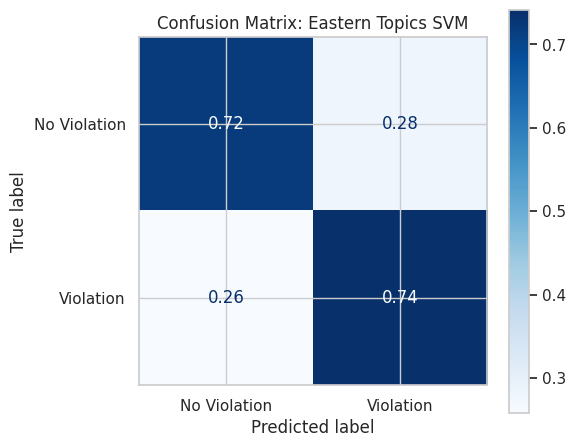


--- Evaluation for Western Topics SVM ---
Classification Report (Western Topics SVM):
              precision    recall  f1-score   support

No Violation       0.76      0.69      0.72       143
   Violation       0.70      0.77      0.73       137

    accuracy                           0.73       280
   macro avg       0.73      0.73      0.73       280
weighted avg       0.73      0.73      0.73       280



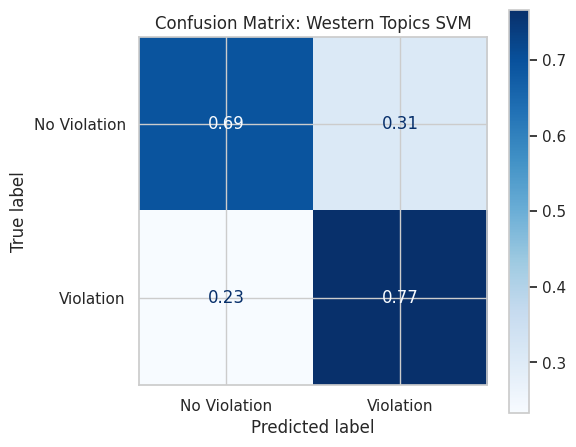

In [ ]:

# 2. Train SVM on Topic Weights
print("Training SVMs on Topic Weights...")

# Filter only to decided cases (Violation / No Violation) for SVM training
east_mask = df_eastern['finding'].isin(['Violation', 'No Violation'])
west_mask = df_western['finding'].isin(['Violation', 'No Violation'])

svm_east_topics = SVC(kernel='linear', class_weight='balanced', random_state=42)
svm_east_topics.fit(W_east_20[east_mask], df_eastern.loc[east_mask, 'finding'])

svm_west_topics = SVC(kernel='linear', class_weight='balanced', random_state=42)
svm_west_topics.fit(W_west_20[west_mask], df_western.loc[west_mask, 'finding'])

print("\n--- Evaluation for Eastern Topics SVM ---")
y_pred_east = svm_east_topics.predict(W_east_20[east_mask])
print("Classification Report (Eastern Topics SVM):")
print(classification_report(df_eastern.loc[east_mask, 'finding'], y_pred_east))

fig_east, ax_east = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    df_eastern.loc[east_mask, 'finding'], y_pred_east,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax_east
)
ax_east.set_title('Confusion Matrix: Eastern Topics SVM')
plt.tight_layout()
plt.show()

print("\n--- Evaluation for Western Topics SVM ---")
y_pred_west = svm_west_topics.predict(W_west_20[west_mask])
print("Classification Report (Western Topics SVM):")
print(classification_report(df_western.loc[west_mask, 'finding'], y_pred_west))

fig_west, ax_west = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    df_western.loc[west_mask, 'finding'], y_pred_west,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax_west
)
ax_west.set_title('Confusion Matrix: Western Topics SVM')
plt.tight_layout()
plt.show()

In addition, we trained separate Linear SVMs on the topic weights for each region, to help us determine if these 20 thematic topics are sufficient to train a predictive model. The confusion matrices demonstrate that these 20 topics provide a remarkably robust training signal when the models are evaluated on their native jurisprudence.

Despite the severe class imbalance inherent to the dataset, the Eastern Topics SVM correctly classifies 74% of actual violations and 72% of actual "No Violations". Similarly, the Western Topics SVM successfully identifies 77% of actual violations and 69% of actual "No Violations". The fact that both models maintain strong diagonal performance and avoid collapsing into majority-class prediction proves that the 20 extracted topics effectively capture the critical decision boundaries needed to predict outcomes within their specific regional contexts.


Feature Importance and Topic Weights Analysis

Generating Feature Importance Plots...


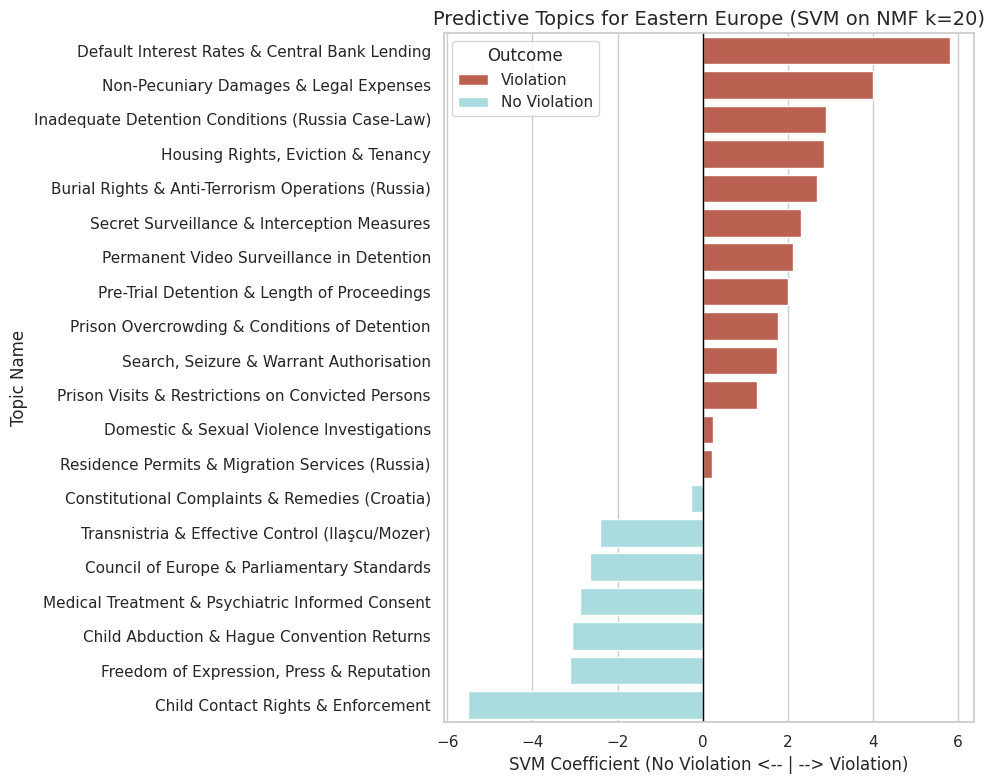

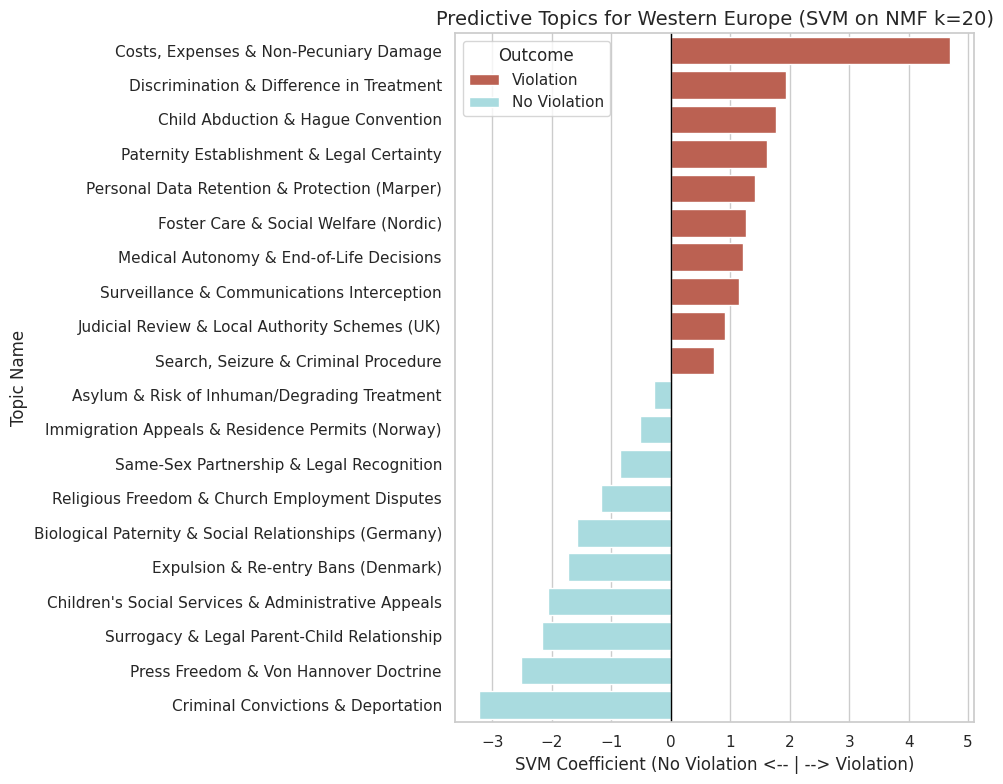

In [ ]:
# 3. Function to Plot Topic Importances
def plot_topic_importance(svm_model, topic_label_map, region_name):
    # Extract coefficients
    coefs = svm_model.coef_[0]

    # Create DataFrame, mapping topic indices to descriptive labels
    df_imp = pd.DataFrame({'Topic_Index': range(len(coefs)), 'Weight': coefs})
    df_imp['Topic'] = df_imp['Topic_Index'].map(topic_label_map)
    df_imp = df_imp.sort_values(by='Weight', ascending=False)

    # Map colors: Positive = Violation, Negative = No Violation
    df_imp['Outcome'] = df_imp['Weight'].apply(lambda x: 'Violation' if x > 0 else 'No Violation')
    palette_map = {'Violation': '#CC5441', 'No Violation': '#A0E3E8'}

    plt.figure(figsize=(10, 8))
    sns.barplot(data=df_imp, x='Weight', y='Topic', hue='Outcome', palette=palette_map, dodge=False)
    plt.axvline(0, color='black', linewidth=1)
    plt.title(f'Predictive Topics for {region_name} (SVM on NMF k={k_opt})', fontsize=14)
    plt.xlabel('SVM Coefficient (No Violation <-- | --> Violation)')
    plt.ylabel('Topic Name') # Changed label to 'Topic Name'
    plt.tight_layout()
    plt.show()

# 4. Generate Plots
print("Generating Feature Importance Plots...")
plot_topic_importance(svm_east_topics, topic_labels_eastern, "Eastern Europe") # Changed labels_east_20 to topic_labels_eastern
plot_topic_importance(svm_west_topics, topic_labels_western, "Western Europe") # Changed labels_west_20 to topic_labels_western

To understand the semantic divergence between Eastern and Western European ECHR Article 8 cases, we trained separate Linear SVM classifiers on the 20 NMF-generated topic features for each region. The resulting feature importance charts measured by the SVM coefficients reveal stark differences in the types of cases that drive "Violation" versus "No Violation" findings in each bloc.

Setting aside this structural artifact, the substantive predictive topics clearly illustrate the diverging jurisprudential landscapes:

**Eastern Europe: Systemic Failures vs. Family Disputes**

The Eastern European model reveals a jurisprudence heavily weighted by structural and physical state interference.

**Predictive of Violation:** Setting aside the dominant outcome-leakage topic ("eur, plus tax"), the Eastern violation topics are characterized by severe, systemic, and physical breaches of rights. The most predictive topics include Russian batch applications and boilerplate ("appended table"), state surveillance ("zubkov, secret surveillance"), extreme prison conditions ("cell, conditions detention", "permanent video"), police overreach ("search, warrant, police, seizure"), and lethal state action ("burial, deceased, armed, terrorist").

**Predictive of No Violation:** The strongest predictors for a "No Violation" in the East center on private family matters. Topics like "child, contact, parent" and "hague, removal retention" indicate that when Eastern states adjudicate child custody or family contact disputes, the ECtHR frequently finds that the domestic authorities operated within their margin of appreciation.

**Western Europe: Nuanced Rights vs. Migration Margin**

The Western European model maps a vastly different legal landscape, focused more on administrative, technological, and evolving social rights.

**Predictive of Violation:** Again, ignoring the outcome-leakage topic ("expenses, costs"), the Western violation topics are highly administrative and specific. They include "data protection, processing, personal data," "paternity act, putative," and "difference treatment, discrimination." Interestingly, "hague, custody, removal retention" is a strong violation predictor in the West, directly contrasting with the East where it reliably predicted No Violation.

**Predictive of No Violation:** The Western model's non-violation boundary is defined almost entirely by areas where the Court grants states a wide margin of appreciation. The strongest predictors include migration and deportation ("expulsion, expelled, deportation", "asylum, aliens, residence permit", "danish, reentry ban"), as well as evolving social issues lacking a European consensus, such as "samesex, partnership" and "surrogacy, adoption".

While the Topic-Based SVM provides a highly interpretable mechanism for mapping the jurisprudential divide between Eastern and Western Europe, it is imperative to acknowledge the methodological limitations inherent to this approach. Addressing these constraints is essential for preserving the construct validity of our findings and ensuring we do not conflate mathematical artefacts with genuine legal inference. By transparently defining where the NMF and SVM architecture falls short, we can accurately contextualize our predictive metrics, avoid overstating the model's capacity for substantive legal reasoning, and establish a rigorous theoretical foundation for the deep semantic analysis that follows. While NMF clustering provides excellent interpretability and successfully exposes these regional differences, this specific application is constrained by three distinct limitations:

**The "Just Satisfaction" Outcome Leakage:** As established in our RQ1 and RQ2 analyses, the same structural caveat regarding Article 41 heavily applies here. In the feature importance charts, the absolute strongest predictors of a Violation are topics dominated by financial remedy boilerplate rather than substantive law. This directly corroborates the findings of Medvedeva et al. (2020), who warned that ECtHR predictive models often suffer from "future leakage." As the Court drafts its judgments retroactively, algorithms easily learn to identify the structural presence of Article 41 damages rather than the substantive legal arguments that led to them. For the Eastern model, the top predictor is "Default Interest Rates & Central Bank Lending," followed closely by "Non-Pecuniary Damages & Legal Expenses." For the Western model, the strongest predictor is "Costs, Expenses & Non-Pecuniary Damage." As noted for RQ2, leakage topics like Default Interest Rate, Legal Costs Reimbursement, Pecuniary Damages, and Remedies & Damages carry a 100% violation signal and function as near-perfect violation predictors in the topic weight feature matrix. Therefore, a proportion of the models' predictive success is attributable to these leakage-contaminated features rather than genuine legal thematic discrimination. Again to reiterate, this leakage can be mitigated by explicitly excising all 'just satisfaction' paragraphs before feeding the corpus into the NMF model. Taking this preprocessing step is essential to ensure that our predictive metrics reflect genuine jurisprudential themes rather than superficial formatting artifacts.

**Hyperparameter Rigidity (k=20):** We constrained the NMF algorithm to find exactly 20 topics for both the East and the West. While the true "optimal" number of legal themes likely differs between regions, this hyperparameter adjustment is necessary due to the reduced size of the partitioned regional corpora. Maintaining a higher $k$ on these smaller subsets would risk "topic splintering" and introduce high dimensionality, causing the subsequent Linear SVM to overfit the training data. Forcing $k=20$ provides an optimal balance, ensuring the extracted features represent dense, substantive legal doctrines rather than mathematical noise, even if it risks minor "topic collapsing" (mashing distinct concepts into one).

**Static Word Representation:** NMF is essentially a sophisticated "bag-of-words" approach. It groups words that frequently co-occur, but it does not understand context or syntax. For example, the word "child" appears in both violation and non-violation topics, but NMF cannot tell us how the word is being used. To truly understand how the Court's reasoning changes, for instance, how the exact phrase "margin of appreciation" is applied differently in the East versus the West, we must move beyond static topic distributions and examine the semantic neighborhoods of the words themselves.

This final limitation directly necessitates the use of neural word embeddings, which we will explore in RQ4 using Word2Vec.


###Alternative to Pycaret: Comparing models on NMF Topic Features


As we look to evaluate the predictive power of our 20 NMF topics, we utilized a multi-model cross-validation approach. Due to PyCaret's strict dependency limitations with Google Colab's native Python 3.12 environment, we engineered a custom Scikit-Learn evaluation pipeline to replicate the ‘compare_models’ technique, testing our topic features against five distinct algorithmic baselines.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_validate, StratifiedKFold
import pandas as pd

print("Preparing to run multi-model comparison...")

# Define a function that mimics PyCaret's compare_models()
def mini_pycaret(X, y):
    models = {
        'SVM (Linear)': SVC(kernel='linear', class_weight='balanced', random_state=42),
        'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
        'Gradient Boosting': GradientBoostingClassifier(random_state=42),
        'Naive Bayes': GaussianNB()
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    results = []

    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'f1_macro', 'precision_macro', 'recall_macro'])
        results.append({
            'Model': name,
            'Accuracy': scores['test_accuracy'].mean(),
            'Prec. (macro)': scores['test_precision_macro'].mean(),
            'Recall (macro)': scores['test_recall_macro'].mean(),
            'F1 (macro)': scores['test_f1_macro'].mean()
        })

    # Return leaderboard sorted by F1 (macro)
    df_results = pd.DataFrame(results).sort_values(by='F1 (macro)', ascending=False).reset_index(drop=True)
    return df_results.round(4)

# 1. Run Eastern Shootout
print("\n" + "="*60)
print("LEADERBOARD: EASTERN EUROPE (20 NMF TOPICS)")
print("="*60)
east_mask = df_eastern['finding'].isin(['Violation', 'No Violation'])
east_leaderboard = mini_pycaret(W_east_20[east_mask], df_eastern.loc[east_mask, 'finding'])
display(east_leaderboard)

# 2. Run Western Shootout
print("\n" + "="*60)
print("LEADERBOARD: WESTERN EUROPE (20 NMF TOPICS)")
print("="*60)
west_mask = df_western['finding'].isin(['Violation', 'No Violation'])
west_leaderboard = mini_pycaret(W_west_20[west_mask], df_western.loc[west_mask, 'finding'])
display(west_leaderboard)


Preparing to run multi-model comparison...

LEADERBOARD: EASTERN EUROPE (20 NMF TOPICS)


,Model,Accuracy,Prec. (macro),Recall (macro),F1 (macro)
0,Random Forest,0.9426,0.9132,0.8404,0.8703
1,Gradient Boosting,0.9362,0.8904,0.8364,0.8583
2,Logistic Regression,0.7333,0.6243,0.7242,0.6272
3,Naive Bayes,0.6940,0.6391,0.7779,0.6197
4,SVM (Linear),0.7206,0.6202,0.7198,0.6180



LEADERBOARD: WESTERN EUROPE (20 NMF TOPICS)


,Model,Accuracy,Prec. (macro),Recall (macro),F1 (macro)
0,Random Forest,0.8429,0.8479,0.8422,0.8420
1,Gradient Boosting,0.8393,0.8439,0.8388,0.8386
2,Logistic Regression,0.6679,0.6715,0.6677,0.6655
3,Naive Bayes,0.6464,0.6500,0.6472,0.6445
4,SVM (Linear),0.6321,0.6393,0.6312,0.6190


**Analysis :**

The leaderboard revealed a substantial performance gap: non-linear ensemble methods like Random Forest dominated the task, achieving a Macro F1 score of 0.87 in the East and 0.84 in the West. These ensemble methods significantly outperformed linear models like the SVM, which achieved F1 scores of 0.61 in the East and 0.62 in the West.
This performance disparity indicates that the relationship between legal topics and ECtHR outcomes is highly non-linear. The Court likely bases its decisions on complex intersections of multiple topics rather than isolated thematic features. However, while Random Forest excels predictively, it functions as a "black box," making it mathematically difficult to extract directional relationships between topics and legal outcomes.
As our primary objective is interpretability, specifically identifying which regional themes drive the Court toward a "Violation" versus a "No Violation", we deliberately utilized the Linear SVM to generate our feature importance visualizations. Trading raw predictive performance for transparency and being able to see what the algorithm is thinking, allows us to extract clear, directional coefficients that map the distinct jurisprudential priorities of the Eastern and Western blocs.



**Conclusion**

The cross-regional generalisation experiment reveals a pronounced and asymmetric answer to RQ3. A model trained on Western European cases generalises strongly to the Eastern corpus, achieving a macro F1 of 0.85, while a model trained on Eastern European cases generalises substantially less well to the Western corpus, achieving a macro F1 of 0.77.

The confusion matrices clarify what drives this asymmetry. The Eastern-trained model applied to Western cases achieves a recall of 0.88 for actual violations but only 0.68 for actual no-violation cases, meaning it misclassifies 32% of genuine no-violation outcomes as violations. The model is structurally predisposed to predict state fault regardless of whether Western legal reasoning supports that conclusion. The Western-trained model applied to Eastern cases suffers no comparable collapse, correctly identifying 96% of violations and 75% of no-violation cases. The failure is therefore directional, the Eastern model lacks the vocabulary to recognise justified state interference in Western cases, while the Western model possesses sufficient generalised legal reasoning to handle Eastern cases adequately.

The feature importance analysis identifies two explanations for this pattern. The first is structural, both models are partially contaminated by Article 41 leakage, with the strongest violation-side predictors in both the Eastern and Western classifiers being remedial boilerplate terms such as "claimed", "finds protocols", "thereto law" and "awards" rather than substantive legal reasoning vocabulary. This inflates both models' apparent performance and means that a portion of the predictive signal in each direction reflects the presence or absence of just satisfaction language rather than genuine doctrinal discrimination. The second explanation is respondent state concentration. The Eastern corpus is dominated by Russian cases carrying near-universal violation rates, causing the Eastern-trained model to learn country-specific factual patterns rather than transferable legal principles. When faced with Western cases that involve complex proportionality assessments and elaborate domestic remedy procedures, the Eastern model misreads procedural complexity as evidence of violation.

The no-violation feature vocabulary makes this divergence concrete. The Eastern model's strongest no-violation predictors are procedural delay terms and specific factual scenarios, including "length proceedings", "medical malpractice" and "education" as well as a named-case citation ("mozer"). The Western model's no-violation signal is anchored in substantive social rights and privacy balancing concepts, including "contact rights", "divorce", "appeal”. These are not interchangeable legal vocabularies. A classifier trained on the Eastern signal has no basis for recognising Western proportionality reasoning as a no-violation marker.

The Turkey analysis strengthens this interpretation. Turkey's TF-IDF centroid is factually closer to the Eastern corpus, with a cosine similarity of 0.8222 against 0.7845 for the Western corpus, yet the Western-trained model outperforms the Eastern-trained model on Turkish cases, achieving Macro F1 of 0.45 against 0.31. Turkey acts as a jurisprudential boundary state: its cases share the factual vocabulary of Eastern European litigation but require the doctrinal balancing analysis that the Western model has learned to apply. The Eastern model's failure on Turkish cases despite their factual alignment with Eastern docket patterns confirms that the generalisation gap is not primarily a factual vocabulary problem but a legal reasoning problem rooted in Russia-specific overfitting.

In answer to RQ3, the generalisation capacity of Article 8 classifiers is asymmetric and corpus-dependent. Western-trained models generalise effectively to Eastern cases because they have learned a more broadly applicable doctrinal framework. Eastern-trained models fail to generalise to Western cases because they have learned a regionally specific pattern of state interference that does not transfer to the proportionality-centred reasoning characteristic of Western jurisprudence. A genuinely portable Article 8 classifier would require a balanced, geographically diverse training corpus with Article 41 text removed prior to feature extraction.


#**RQ4 : Semantic Analysis between Region**


---

In RQ3, we found that a model trained on Russian/Eastern cases generalises poorly to Western European cases. RQ4 asks the natural follow-up question: why?

Our hypothesis is that the gap is not only about which topics appear across regions, but also about how the same legal concepts are used in practice. Terms like **“margin of appreciation” and “proportionality”** appear in nearly every Article 8 judgment, regardless of outcome or country, but that does not necessarily mean they carry the same legal meaning in each regional context. For example, when an Eastern European court invokes **“proportionality,”** it may do so in a different doctrinal setting than a Western European court. Our hypothesis are : If these core concepts carry different semantic weight across regions, that would help explain why a classifier trained on one region struggles to generalise to the other.



To examine this, we move beyond bag-of-words methods such as NMF and use Word2Vec. Although Word2Vec is still a static embedding model, it captures local semantic and syntactic relationships by placing words in a high-dimensional semantic space. By training separate Word2Vec models on the Eastern and Western corpora, we can compare the semantic neighborhoods of key doctrinal terms such as **“margin,” “private_life,” and “family_life.”** This gives us a vocabulary-level picture of semantic drift across the full text of judgments, and it provides a useful final layer for understanding the cross-regional generalisation gap identified in this study.


A more advanced next step would be to use BERT, since contextualized models can capture meaning more accurately in legal text and are especially well suited to ECHR analysis, including pretrained models developed specifically on ECHR cases. However, we do not pursue that route here because of limited GPU access. Still, if resources allow, BERT would be an interesting option for follow-up work or future improvement of this study.


##Word2Vec Embedding Model
Preprocessing

In [ ]:
# ============================================================
# RQ4 — PREPROCESSING
# Text column : law_text
# One stop word list : W2V_STOPWORDS
# One phrase pipeline : bigram (Phraser) + known trigrams
# This cell prepares tokenized and phrased sentences (east_sents_phrased, west_sents_phrased)
# for subsequent Word2Vec model training, which generates word embeddings for t-SNE visualization.
# ============================================================

import re
import pickle
import nltk
from nltk.stem import WordNetLemmatizer
from gensim.models.phrases import Phrases, Phraser

nltk.download('punkt',       quiet=True)
nltk.download('wordnet',     quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('punkt_tab', quiet=True)

# ── CONFIG ───────────────────────────────────────────────────
TEXTCOL        = 'law_text_w2v_raw' # UPDATED to use the new raw text column
MIN_SENT_WORDS_INITIAL_FILTER = 3 # Reduced from 5 to allow shorter sentences initially
MIN_SENT_WORDS_FINAL_FILTER = 3  # Reduced from 7 to allow shorter sentences after cleaning
SAMPLE_FRACTION = 1.0

# ── MASTER CONCEPT LIST — edit only here ────────────────────
MASTER_CONCEPT_LIST = [
    # Single words
    "necessary", "proportionate",
    "democratic", "correspondence", "security",
    "safety", "integrity", "margin", "home", "correspondence",
    # Multi-word phrases as tuples
    ("margin",   "appreciation"),
    ("private",  "life"),
    ("family",   "life"),
    ("positive", "obligation"),

]

# Derived — DO NOT EDIT
CORE_W2V_SINGLE_WORDS = {
    t for t in MASTER_CONCEPT_LIST if isinstance(t, str)
}
DEFINED_MULTIWORD_PHRASES_MAPPING = {
    t: "_".join(t)
    for t in MASTER_CONCEPT_LIST if isinstance(t, tuple)
}
PHRASE_VERIFICATION_LIST = list(DEFINED_MULTIWORD_PHRASES_MAPPING.values())
FOCAL_TERMS_ALL = (
    list(CORE_W2V_SINGLE_WORDS) +
    PHRASE_VERIFICATION_LIST
)

print(f"Single terms  : {sorted(CORE_W2V_SINGLE_WORDS)}")
print(f"Phrase tokens : {PHRASE_VERIFICATION_LIST}")
print(f"Total focal   : {len(FOCAL_TERMS_ALL)}")

# ── CORPUS SPLIT ─────────────────────────────────────────────
df_rq4 = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()
df_rq4['cluster'] = df_rq4['respondent_country'].apply(assign_rq3_group)
df_rq4 = df_rq4[df_rq4['cluster'].isin(['Eastern', 'Western'])].copy()
df_rq4 = df_rq4.dropna(subset=[TEXTCOL]).copy()
df_rq4 = df_rq4[df_rq4[TEXTCOL].str.len() > 200].copy()

if SAMPLE_FRACTION < 1.0:
    df_rq4 = df_rq4.sample(frac=SAMPLE_FRACTION, random_state=42).copy()

df_east = df_rq4[df_rq4['cluster'] == 'Eastern'].copy()
df_west = df_rq4[df_rq4['cluster'] == 'Western'].copy()

print(f"\nEastern cases : {len(df_east)}")
print(f"Western cases : {len(df_west)}")

# ── TOKENISATION ─────────────────────────────────────────────
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Only handle unicode characters and convert to lowercase initially
    # Punctuation removal will happen per sentence after tokenization
    text = text.replace('\u00a0', ' ').replace('\u2013', '-').replace('\u2014', '-')
    return text.lower().strip()

def tokenise_sentences(text, stopwords, exclude_terms, min_sentence_len_initial):
    sentences_raw = nltk.sent_tokenize(text) # Tokenize sentences first
    processed = []
    seen = set()

    for s_raw in sentences_raw:
        # First, remove only numbers from the raw sentence (after lowercase)
        s_no_numbers = re.sub(r'[0-9]', '', s_raw.lower())
        # Clean up extra spaces that might result from number removal
        s_cleaned = re.sub(r'\s+', ' ', s_no_numbers).strip()

        if not s_cleaned or len(s_cleaned.split()) < min_sentence_len_initial:
            continue

        tokens = [
            lemmatizer.lemmatize(w)
            for w in nltk.word_tokenize(s_cleaned)
            if w not in stopwords
            and w not in exclude_terms
        ]
        if not tokens:
            continue
        t = tuple(tokens)
        if t not in seen:
            seen.add(t)
            processed.append(tokens)
    return processed

class SentenceStream:
    def __init__(self, df, textcol, stopwords, exclude_terms, min_initial_words, min_final_words):
        self.df           = df
        self.textcol      = textcol
        self.stopwords    = stopwords
        self.exclude_terms = exclude_terms
        self.min_initial_words = min_initial_words
        self.min_final_words = min_final_words

    def __iter__(self):
        for _, row in self.df.iterrows():
            # Pass the raw text (only unicode/lowercase handled by clean_text) to tokenise_sentences
            # to allow nltk.sent_tokenize to work properly.
            # The internal cleaning will then handle punctuation per sentence.
            for sent in tokenise_sentences(
                clean_text(row[self.textcol]), self.stopwords, self.exclude_terms, self.min_initial_words
            ):
                if len(sent) >= self.min_final_words:
                    yield sent

# ── COLLECT SENTENCES ─────────────────────────────────────────
print("\nCollecting sentences...")
east_sents = list(SentenceStream(
    df_east, TEXTCOL, custom_w2v_stop_words, [], MIN_SENT_WORDS_INITIAL_FILTER, MIN_SENT_WORDS_FINAL_FILTER
))
west_sents = list(SentenceStream(
    df_west, TEXTCOL, custom_w2v_stop_words, [], MIN_SENT_WORDS_INITIAL_FILTER, MIN_SENT_WORDS_FINAL_FILTER
))
print(f"  Eastern : {len(east_sents):>6,} sentences from {len(df_east)} cases")
print(f"  Western : {len(west_sents):>6,} sentences from {len(df_west)} cases")

# ── BIGRAM DETECTION ─────────────────────────────────────────
print("\nDetecting bigrams...")
bigram_east = Phrases(east_sents, min_count=5, threshold=10,
                      connector_words=frozenset(['of', 'in', 'and', 'a']))
bigram_west = Phrases(west_sents, min_count=5, threshold=10,
                      connector_words=frozenset(['of', 'in', 'and', 'a']))

phraser_east = Phraser(bigram_east)
phraser_west = Phraser(bigram_west)
del bigram_east, bigram_west

east_sents_phrased = [phraser_east[s] for s in east_sents]
west_sents_phrased = [phraser_west[s] for s in west_sents]

# ── PHRASE COUNT VERIFICATION ─────────────────────────────────
print("\nPhrase occurrence counts:")
print(f"  {'Phrase':<35} {'East':>8} {'West':>8}  Status")
print("  " + "─" * 60)
for ph in PHRASE_VERIFICATION_LIST:
    e = sum(1 for s in east_sents_phrased if ph in s)
    w = sum(1 for s in west_sents_phrased if ph in s)
    status = "✅" if e >= 5 and w >= 5 else ("⚠️ low" if e > 0 or w > 0 else "❌ missing")
    print(f"  {ph:<35} {e:>8} {w:>8}  {status}")

# ── SAVE TO DRIVE ─────────────────────────────────────────────
with open(f"{SAVE_PATH}east_sents_phrased.pkl", "wb") as f:
    pickle.dump(east_sents_phrased, f)
with open(f"{SAVE_PATH}west_sents_phrased.pkl", "wb") as f:
    pickle.dump(west_sents_phrased, f)

print(f"\n✅ Preprocessing complete.")
print(f"   east_sents_phrased → {SAVE_PATH}east_sents_phrased.pkl")
print(f"   west_sents_phrased → {SAVE_PATH}west_sents_phrased.pkl")

Single terms  : ['correspondence', 'democratic', 'home', 'integrity', 'margin', 'necessary', 'proportionate', 'safety', 'security']
Phrase tokens : ['margin_appreciation', 'private_life', 'family_life', 'positive_obligation']
Total focal   : 13

Eastern cases : 937
Western cases : 277

  Eastern : 123,151 sentences from 937 cases
  Western : 46,094 sentences from 277 cases

Detecting bigrams...

Phrase occurrence counts:
  Phrase                                  East     West  Status
  ────────────────────────────────────────────────────────────
  margin_appreciation                      576      604  ✅
  private_life                            1325      799  ✅
  family_life                             2643     1555  ✅
  positive_obligation                     1007      357  ✅

✅ Preprocessing complete.
   east_sents_phrased → /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/east_sents_phrased.pkl
   west_sents_phrased → /content/drive/MyDrive/LL 55

Training

In [ ]:
from gensim.models import Word2Vec

# Configuration for Word2Vec models
W2V_DIM     = 100    # Dimensionality of the word vectors
WINDOW_SIZE = 10     # Context window size
MIN_COUNT   = 5      # Ignores all words with total frequency lower than this
EPOCHS      = 10     # Number of training iterations
SG          = 1      # Skip-gram (1) vs CBOW (0) — skip-gram often better for rare words
WORKERS     = 4      # Number of CPU cores to use

# Train Word2Vec model for Eastern European cases
print("Training Word2Vec for Eastern cases...")
w2v_east = Word2Vec(
    east_sents_phrased,
    vector_size=W2V_DIM,
    window=WINDOW_SIZE,
    min_count=MIN_COUNT,
    sg=SG,
    epochs=EPOCHS,
    workers=WORKERS,
    seed=42
)
print("Eastern Word2Vec model training complete.")

# Train Word2Vec model for Western European cases
print("\nTraining Word2Vec for Western cases...")
w2v_west = Word2Vec(
    west_sents_phrased,
    vector_size=W2V_DIM,
    window=WINDOW_SIZE,
    min_count=MIN_COUNT,
    sg=SG,
    epochs=EPOCHS,
    workers=WORKERS,
    seed=42
)
print("Western Word2Vec model training complete.")

# Save the models
w2v_east.save(f"{SAVE_PATH}w2v_east.model")
w2v_west.save(f"{SAVE_PATH}w2v_west.model")
print(f"Models saved to {SAVE_PATH}")

Training Word2Vec for Eastern cases...
Eastern Word2Vec model training complete.

Training Word2Vec for Western cases...
Western Word2Vec model training complete.
Models saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/


###dG & dL Score
* **collumn dG measures global semantic displacement**. It captures how far a word moves in the overall embedding space between the East and West corpora after alignment.

* **collumn dL measures local neighbourhood change**. It captures how much the word’s nearest neighbours change between the two corpora.(calculated based on k nearest neighbour = 25, refer to Hamilton paper)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# --- Configuration for drift calculation ---
N_NEIGHBOURS_FOR_DRIFT = 25 # Number of top neighbors to consider for dL and nn_columns

# Initialize a list to store results for df_drift
drift_data = []

print("Calculating semantic drift and nearest neighbors for focal terms...")

for term in FOCAL_TERMS_ALL:
    if term in w2v_east.wv and term in w2v_west.wv:
        vec_east = w2v_east.wv[term]
        vec_west = w2v_west.wv[term]

        # Calculate Global Drift (dG) - Cosine Distance between word vectors
        # Reshape for cosine_similarity which expects 2D arrays
        dG = 1 - cosine_similarity(vec_east.reshape(1, -1), vec_west.reshape(1, -1))[0][0]

        # Get nearest neighbors for Local Drift (dL) and visualization
        # gensim returns (word, similarity) tuples
        nn_east_raw = w2v_east.wv.most_similar(term, topn=N_NEIGHBOURS_FOR_DRIFT)
        nn_west_raw = w2v_west.wv.most_similar(term, topn=N_NEIGHBOURS_FOR_DRIFT)

        nn_east_words = [word for word, _ in nn_east_raw]
        nn_west_words = [word for word, _ in nn_west_raw]

        # Calculate Local Drift (dL) - Jaccard Distance between neighbor sets
        set_east = set(nn_east_words)
        set_west = set(nn_west_words)
        intersection_size = len(set_east.intersection(set_west))
        union_size = len(set_east.union(set_west))

        dL = 1 - (intersection_size / union_size) if union_size > 0 else 1.0 # Jaccard Distance

        drift_data.append({
            'term': term,
            'dG': dG,
            'dL': dL,
            'nn_east_top25': ','.join(nn_east_words), # Store as comma-separated string
            'nn_west_top25': ','.join(nn_west_words)  # Store as comma-separated string
        })
    else:
        print(f"Warning: Skipping '{term}' as it's not in both vocabularies (this should not happen with focal_terms_in_vocab if generated correctly).")

# Create df_drift
df_drift = pd.DataFrame(drift_data)

# Sort df_drift by dL in descending order, then by dG in descending order
df_drift = df_drift.sort_values(by=['dL', 'dG'], ascending=[False, False]).reset_index(drop=True)

print(f"df_drift created with {len(df_drift)} terms.")
# Display the full DataFrame instead of just the head
display(df_drift)

# Also save df_drift to drive for persistence
df_drift.to_csv(f"{SAVE_PATH}df_drift_rq4.csv", index=False)
print(f"df_drift saved to {SAVE_PATH}df_drift_rq4.csv")

Calculating semantic drift and nearest neighbors for focal terms...
df_drift created with 13 terms.


,term,dG,dL,nn_east_top25,nn_west_top25
0,necessary,1.072190,1.000000,"doe_consider,ascertain_requirement,review_comp...","authorised_purpose,interest_national,need_know..."
1,family_life,0.988912,1.000000,"right_private,primary_object,authority_monory,...","host_outset,aware_immigration,allegation_failu..."
2,correspondence,0.846433,1.000000,"correspondence_monitored,monitoring,monitoring...","niemietz_cited,protects_confidentiality,niemie..."
3,safety,0.944752,0.979592,"section_interment,safe,endanger,security,urban...","diver_health,posed,escape,risk_posed,alarming,..."
4,security,0.929747,0.979592,"constant_supervision,tighter,safety,providing_...","detecting_crime,safeguarding_economic,interest..."
5,democratic,0.914119,0.979592,"democracy,restore_trust,governance,undemocrati...","legitimation,uniform,diversity,medical_science..."
6,home,1.049988,0.958333,"eviction,gajeva_street,dormitory_building,hous...","eviction_demolition,muslim_foster,schooling,ho..."
7,proportionate,0.939729,0.936170,"lawful_pursued,aim_safeguarding,preventing_cri...","pursuit_legitimate,aim_sought,gateway_b,mean_e..."
8,margin,0.931698,0.913043,"usually_wide,embracing_legislation,allowed_cor...","broad_margin,state_council,usually_wide,dickso..."
9,integrity,0.856775,0.913043,"includes_person,end_maintain,context_concept,m...","physical_moral,moral_integrity,one_image,perso..."


df_drift saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/df_drift_rq4.csv


**Note :**   Repeated runs of Word2Vec model proven to be bit unstable probably caused by lack of cases. The value of dG and dL can slightly changes and cause the rank also shift. It means we should be cautious during analysis, not relying so much on the score and rank, but more towards overview looks of the data.

**Normalization for dG & dL**

output/normalized_drift_scores.csv
output/normalized_drift_comparison_scatter.jpg


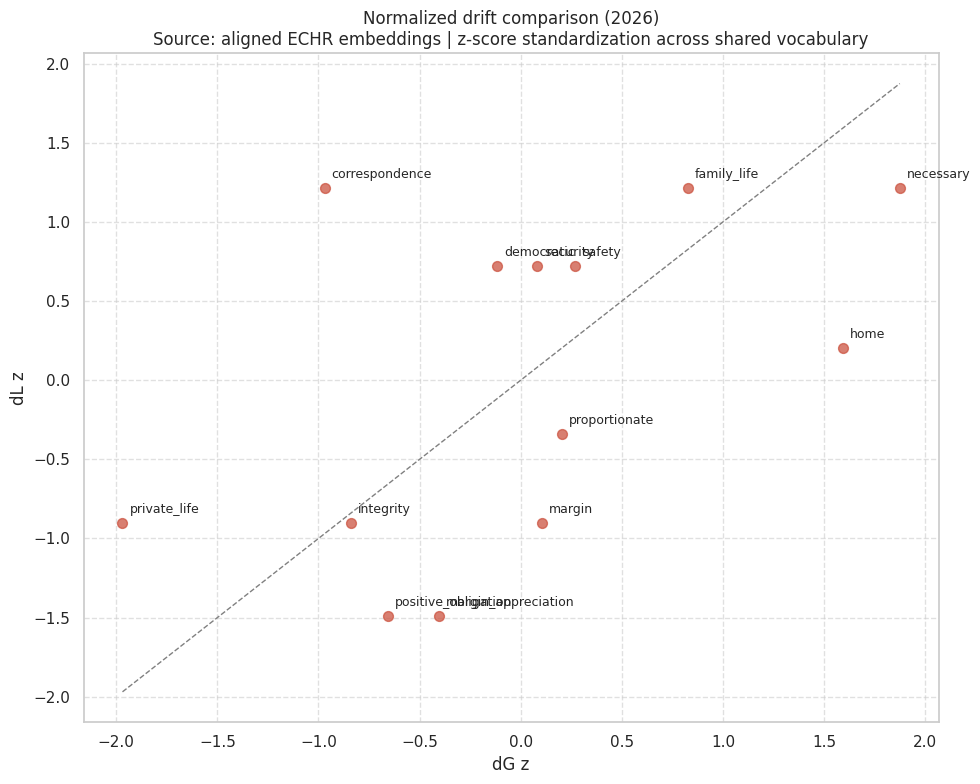

In [ ]:
import os, numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

outdir = "output"
os.makedirs(outdir, exist_ok=True)

c1 = "dG"
c2 = "dL"

if "df_drift" not in globals():
    raise NameError("df_drift not found. Create df_drift first with columns term, dG, dL.")

work = df_drift[["term", c1, c2]].copy().dropna()

scaler = StandardScaler()
work[[f"{c1}_z", f"{c2}_z"]] = scaler.fit_transform(work[[c1, c2]])

work[f"{c1}_mm"] = (work[c1] - work[c1].min()) / (work[c1].max() - work[c1].min() + 1e-12)
work[f"{c2}_mm"] = (work[c2] - work[c2].min()) / (work[c2].max() - work[c2].min() + 1e-12)

work["abs_gap_z"] = (work[f"{c1}_z"] - work[f"{c2}_z"]).abs()
work["abs_gap_mm"] = (work[f"{c1}_mm"] - work[f"{c2}_mm"]).abs()

csv_path = os.path.join(outdir, "normalized_drift_scores.csv")
work.sort_values("abs_gap_z", ascending=False).to_csv(csv_path, index=False)

# Scatter plot using Matplotlib
fig, ax = plt.subplots(figsize=(10, 8))

# Plot points
ax.scatter(work[f"{c1}_z"], work[f"{c2}_z"], s=50, alpha=0.75)

# Add text labels
for i, term in enumerate(work["term"]):
    ax.annotate(term, (work[f"{c1}_z"].iloc[i], work[f"{c2}_z"].iloc[i]),
                textcoords="offset points", xytext=(5,5), ha='left', va='bottom', fontsize=9)

# Add diagonal line
min_val = min(work[f"{c1}_z"].min(), work[f"{c2}_z"].min())
max_val = max(work[f"{c1}_z"].max(), work[f"{c2}_z"].max())
ax.plot([min_val, max_val], [min_val, max_val], color="gray", linestyle="--", linewidth=1)

ax.set_title("Normalized drift comparison (2026)\nSource: aligned ECHR embeddings | z-score standardization across shared vocabulary", fontsize=12)
ax.set_xlabel("dG z")
ax.set_ylabel("dL z")
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save scatter plot as a static JPG image
static_image_path = os.path.join(outdir, "normalized_drift_comparison_scatter.jpg")
plt.savefig(static_image_path, dpi=150)


print(csv_path)
print(static_image_path)

* **Top-right: high dG, high dL**
Words here show both strong global movement and strong neighbour change. These are your strongest semantic-shift candidates because the word moves in the overall space and also changes its local company.

* **Top-left: low dG, high dL**
Words here have stable global position but changed local neighbours. This suggests a more localised semantic reconfiguration: the word still sits in roughly the same part of the embedding space, but its immediate semantic associates changed.

* **Bottom-right: high dG, low dL**
Words here show global displacement without strong neighbour change. This can indicate a broader doctrinal or contextual shift where the word’s overall position changes, but its closest semantic neighbours remain relatively similar.

* **Bottom-left: low dG, low dL**
Words here are relatively stable on both measures. They are less likely to be interesting drift terms because both their overall location and local neighbourhood are close to the corpus average

**Note** : Because the values are z-scored, negative numbers do not mean “reverse drift”; they only mean below the mean drift level in the comparison set. So the interpretation should always be relative to the dataset average, not absolute meaning change

**Analysis** :

The normalized drift chart suggests that **necessary, home, family_life, and correspondence** are the clearest drift terms, while **private_life, integrity, margin, and margin_appreciation** are relatively more stable. This means some concepts shift mainly in their regional context, but the core doctrinal terms still remain semantically recognizable across both corpora

Based on these findings, we recognize that the model exhibits low instability; consequently, the analysis should avoid over-reliance on the specific numerical ranking of drift magnitudes. However, we have identified evidence of systematic semantic drift across several key terms. While further claims regarding judicial bias between Eastern and Western corpora would require more extensive datasets and a broader range of terms for observation, the present data confirms significant divergence in regional usage.



###t-SNE Visualization
This visualization will only visualize what dL is about (showing nearest neighbours). The chart won't show its global position (dG) in the E / W corpus.

In [ ]:
# ============================================================
# RQ4 ‒ CELL 5: Interactive t-SNE per Focal Term
# Hover shows: word, cosine similarity
# HUDOC lookup: https://hudoc.echr.coe.int/eng#{%22docname%22:[%22{doc_id}%22]}
# ============================================================
import numpy as np
import plotly.graph_objects as go
from sklearn.manifold import TSNE

HUDOC_BASE = "https://hudoc.echr.coe.int/eng#{{%22docname%22:[%22{doc_id}%22]}}"

# User-defined parameters for focal and probe terms, and top-N neighbours
# Updated FOCAL_TERMS to use bigram format detected by Gensim's Phrases model
TOP_N = 20 # Retain original TOP_N value

# Define your custom list of focal terms for t-SNE visualization here.
# These terms must be present in the globally defined FOCAL_TERMS list
# (derived from MASTER_CONCEPT_LIST and available in both W2V models).
CUSTOM_FOCAL_TERMS_FOR_TSNE = [
    'margin','democratic', 'security' , 'necessary' , 'family_life',
    'private_life', 'home',
    'safety'
]


PROBE_TERMS = [] # Initialize as empty list
EXCLUDE_TERMS = [] # Initialize as empty list
models = {'Eastern': w2v_east, 'Western': w2v_west} # Map models for use

def build_tsne_plot(focal_term, cluster, model, topn=TOP_N, perplexity=30, n_iter_val=7000):
    # Ensure probe terms are available in the model's vocabulary
    # PROBE_TERMS is globally defined and was earlier set to an empty list, so this will be empty too.
    probe_in_vocab = [p for p in PROBE_TERMS if p in model.wv]

    # Ensure focal_term is in the model's vocabulary
    if focal_term not in model.wv:
        return None

    # Get initial neighbours and filter out excluded terms (EXCLUDE_TERMS is globally defined)
    initial_neighbours = [w for w, _ in model.wv.most_similar(focal_term, topn=topn)]
    neighbours = [w for w in initial_neighbours if w not in EXCLUDE_TERMS]

    all_words = list(dict.fromkeys([focal_term] + neighbours + probe_in_vocab))

    # Vectors
    vectors = np.array([model.wv[w] for w in all_words])

    # t-SNE
    # Ensure perplexity is valid for the number of points
    actual_perplexity = min(perplexity, len(all_words) - 1)
    if actual_perplexity <= 1:
        print(f"Warning: Not enough points for perplexity={perplexity}. Using actual_perplexity=2 for focal_term='{focal_term}'")
        actual_perplexity = 2 # t-SNE requires perplexity > 1

    tsne = TSNE(n_components=2, perplexity=actual_perplexity, random_state=42, n_iter=n_iter_val)
    coords = tsne.fit_transform(vectors)

    # Cosine similarities to focal term
    focal_vec = model.wv[focal_term]
    cos_sims  = {w: float(np.dot(model.wv[w], focal_vec) /
                          (np.linalg.norm(model.wv[w]) * np.linalg.norm(focal_vec)))
                 for w in all_words}

    # Assign roles
    traces = []
    role_config = {
        'focal':     {'words': [focal_term],       'color': '#CC5441', 'size': 18, 'symbol': 'star'},
        'neighbour': {'words': neighbours,          'color': '#4C9BE8', 'size': 10, 'symbol': 'circle'},
        'probe':     {'words': probe_in_vocab,      'color': '#2CA02C', 'size': 12, 'symbol': 'diamond'},
    }

    for role, cfg in role_config.items():
        xs, ys, texts, hovers = [], [], [], []
        for w in cfg['words']:
            if w not in all_words:
                continue
            idx = all_words.index(w)
            xs.append(coords[idx, 0])
            ys.append(coords[idx, 1])
            texts.append(w)

            hovers.append(
                f"<b>{w}</b><br>" +
                f"Role: {role}<br>" +
                f"Cosine sim to '{focal_term}': {cos_sims.get(w, 0.0):.4f}" + "<br>"
            )
        traces.append(go.Scatter(
            x=xs, y=ys,
            mode='markers+text',
            text=texts,
            textposition='top center',
            hovertext=hovers,
            hoverinfo='text',
            name=role.capitalize(),
            marker=dict(color=cfg['color'], size=cfg['size'],
                        symbol=cfg['symbol'],
                        line=dict(width=1, color='white')),
        ))

    fig = go.Figure(traces)
    fig.update_layout(
        title=f"RQ4 ‒ '{focal_term}' semantic neighbourhood | {cluster} corpus (p={actual_perplexity}, i={n_iter_val})",
        xaxis=dict(showticklabels=False, title='t-SNE dim 1'),
        yaxis=dict(showticklabels=False, title='t-SNE dim 2'),
        legend=dict(orientation='h', yanchor='bottom', y=1.02),
        width=900, height=650,
        hoverlabel=dict(bgcolor='white', font_size=12),
    )
    return fig

# ‒‒ Generate all plots for the CUSTOM list ‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒

# Fixed parameters for display as requested
selected_perplexity = 30
selected_n_iter_val = 7500

print(f"Generating t-SNE plots using perplexity={selected_perplexity} and n_iter={selected_n_iter_val} for each focal term and cluster.")
for focal in CUSTOM_FOCAL_TERMS_FOR_TSNE:
    if focal not in FOCAL_TERMS_ALL:
        print(f"⚠️  '{focal}' is not a valid focal term or not present in both models' vocabularies ‒ skipping")
        continue

    for cluster in ['Eastern', 'Western']:
        print(f"\n--- Generating t-SNE for '{focal}' in {cluster} with perplexity={selected_perplexity}, n_iter={selected_n_iter_val} ---")
        fig = build_tsne_plot(focal, cluster, models[cluster], topn=TOP_N, perplexity=selected_perplexity, n_iter_val=selected_n_iter_val)
        if fig:
            fig.show()
            fname = f"{SAVE_PATH}rq4_tsne_{focal}_{cluster.lower()}_p{selected_perplexity}_i{selected_n_iter_val}.html"
            fig.write_html(fname)
            print(f"Saved: {fname}")
        else:
            print(f"⚠️  '{focal}' not in {cluster} vocab ‒ skipping")

Generating t-SNE plots using perplexity=30 and n_iter=7500 for each focal term and cluster.

--- Generating t-SNE for 'margin' in Eastern with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_margin_eastern_p30_i7500.html

--- Generating t-SNE for 'margin' in Western with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_margin_western_p30_i7500.html

--- Generating t-SNE for 'democratic' in Eastern with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_democratic_eastern_p30_i7500.html

--- Generating t-SNE for 'democratic' in Western with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_democratic_western_p30_i7500.html

--- Generating t-SNE for 'security' in Eastern with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_security_eastern_p30_i7500.html

--- Generating t-SNE for 'security' in Western with perplexity=30, n_iter=7500 ---


... (7 outputs left out)

Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_home_eastern_p30_i7500.html

--- Generating t-SNE for 'home' in Western with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_home_western_p30_i7500.html

--- Generating t-SNE for 'safety' in Eastern with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_safety_eastern_p30_i7500.html

--- Generating t-SNE for 'safety' in Western with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_safety_western_p30_i7500.html


**Analysis :**

* **MARGIN**

the Western corpus places it near balancing and proportionality language, while the Eastern corpus surrounds it with discretion, flexibility, and contextual-variation terms, suggesting a more state-deferential framing in the East

* **NECESSARY**

Western neighbors point to formal necessity testing and adequacy, while Eastern neighbors point to control, justification, and case-based reasoning, which indicates different legal uses of the same concept

* **FAMILY LIFE**

the Western neighborhood is dominated by immigration, recognition, residence, and dependency language, whereas the Eastern neighborhood is centered on family reunion, parental deprivation, and close-family relations. This supports the view that family-life disputes are framed through different factual pathways in the two corpora, with Western cases leaning more toward status and residence issues and Eastern cases leaning more toward family separation and reunification.

* **HOME**

The Western plot shows more associated with eviction, demolition, dwelling, and quiet enjoyment, while the Eastern plot is more centered on house/flat occupation, eviction execution, and lawful occupancy. This suggests that Western usage frames “home” more as a protected private-space concept, whereas Eastern usage is more tied to concrete eviction and housing disputes.



###PCA


Eastern

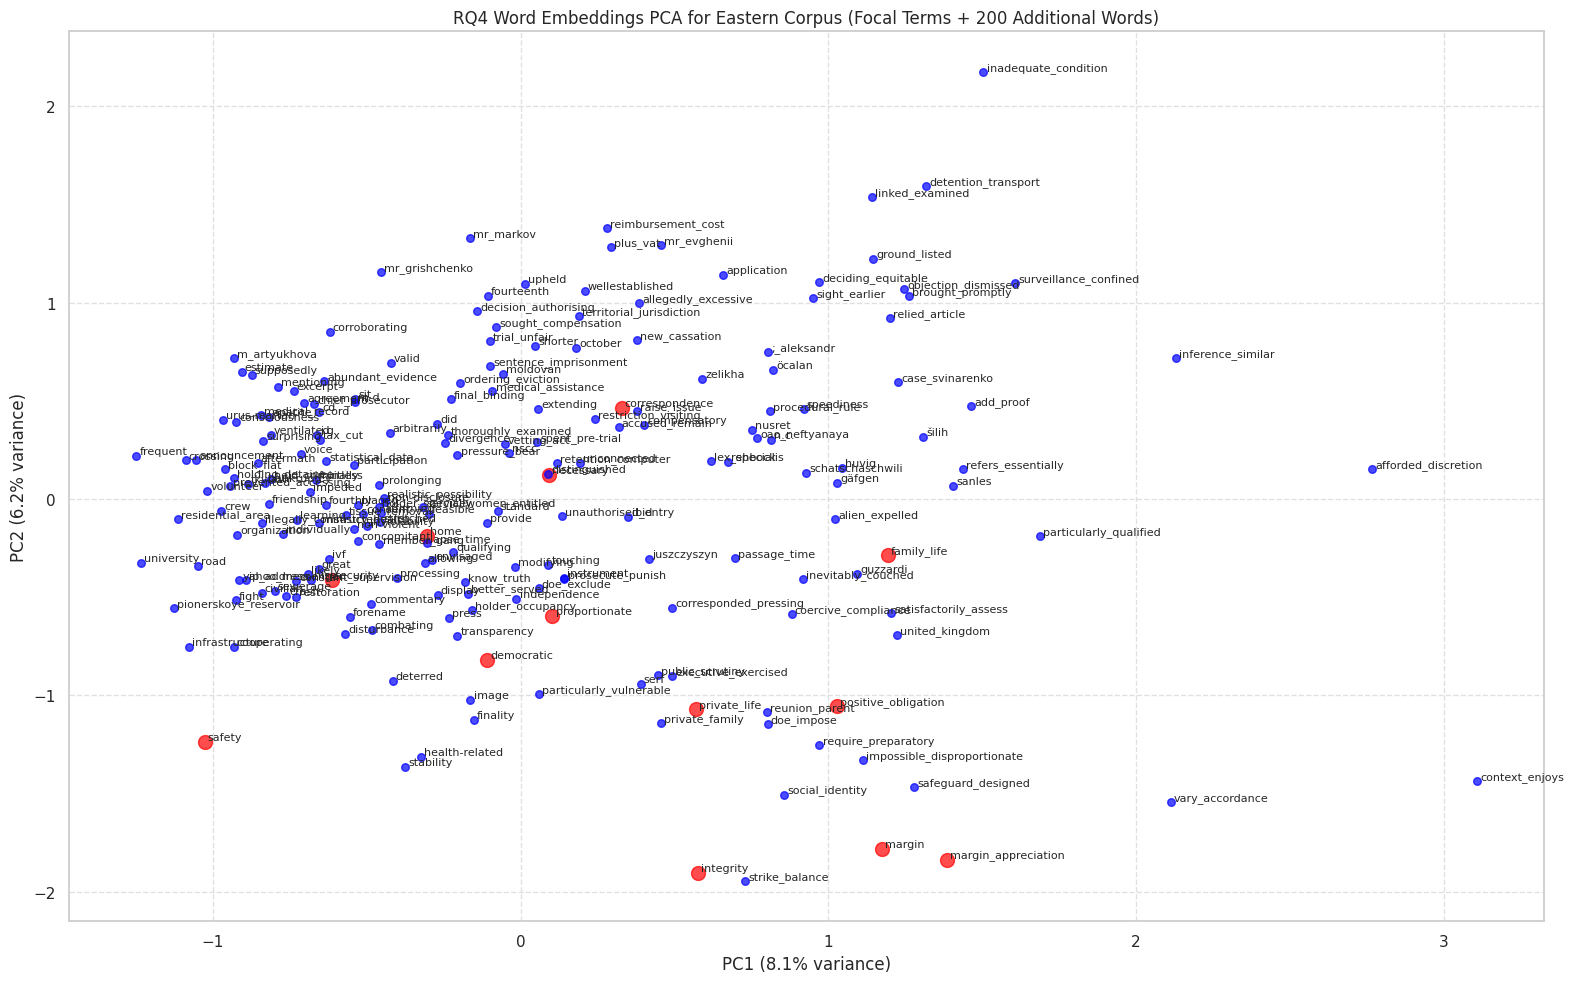

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np # For potential array operations if needed
import random # Import random module

# --- Configuration ---
# Choose which Word2Vec model to use (Eastern or Western)
selected_w2v_model = w2v_east # Options: w2v_east, w2v_west
model_name = "Eastern" if selected_w2v_model == w2v_east else "Western"

# Define the words for PCA visualization
# Using FOCAL_TERMS_ALL as these are the key terms for RQ4 analysis
# Filter out any terms that might not be in the selected model's vocabulary
focal_terms_in_model = [term for term in FOCAL_TERMS_ALL if term in selected_w2v_model.wv]

# --- Option to include additional words from the corpus ---
# Set to True to include a random sample of other words, False to only show focal terms
include_additional_words = True
num_additional_words = 200 # Number of additional random words to include if include_additional_words is True

words_for_pca = list(focal_terms_in_model) # Start with focal terms

if include_additional_words:
    all_vocab_words = list(selected_w2v_model.wv.key_to_index.keys())
    # Ensure uniqueness and avoid duplicates by excluding focal terms already in the list
    non_focal_words = [word for word in all_vocab_words if word not in FOCAL_TERMS_ALL and word not in focal_terms_in_model]

    if len(non_focal_words) > num_additional_words:
        additional_words = random.sample(non_focal_words, num_additional_words)
        words_for_pca.extend(additional_words)
    else:
        words_for_pca.extend(non_focal_words)
        print(f"Warning: Not enough non-focal words to sample {num_additional_words}. Included all {len(non_focal_words)} available non-focal words.")

if not words_for_pca:
    print(f"No words found in the {model_name} model's vocabulary for PCA.")
else:
    # Get vectors for the selected words
    vectors = [selected_w2v_model.wv[w] for w in words_for_pca]

    # Reduce dimensions using PCA
    pca = PCA(n_components=2, random_state=42) # Added random_state for reproducibility
    coords = pca.fit_transform(vectors)

    # Plotting
    plt.figure(figsize=(16,10)) # Increased figure size for more words
    for i, word in enumerate(words_for_pca):
        x, y = coords[i]
        color = 'red' if word in focal_terms_in_model else 'blue' # Differentiate focal terms
        size = 100 if word in focal_terms_in_model else 30 # Make focal terms larger
        plt.scatter(x, y, s=size, color=color, alpha=0.7)
        plt.text(x+0.01, y+0.01, word, fontsize=8) # Offset text slightly

    plt.title(f'RQ4 Word Embeddings PCA for {model_name} Corpus (Focal Terms + {len(words_for_pca) - len(focal_terms_in_model)} Additional Words)')
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

Western

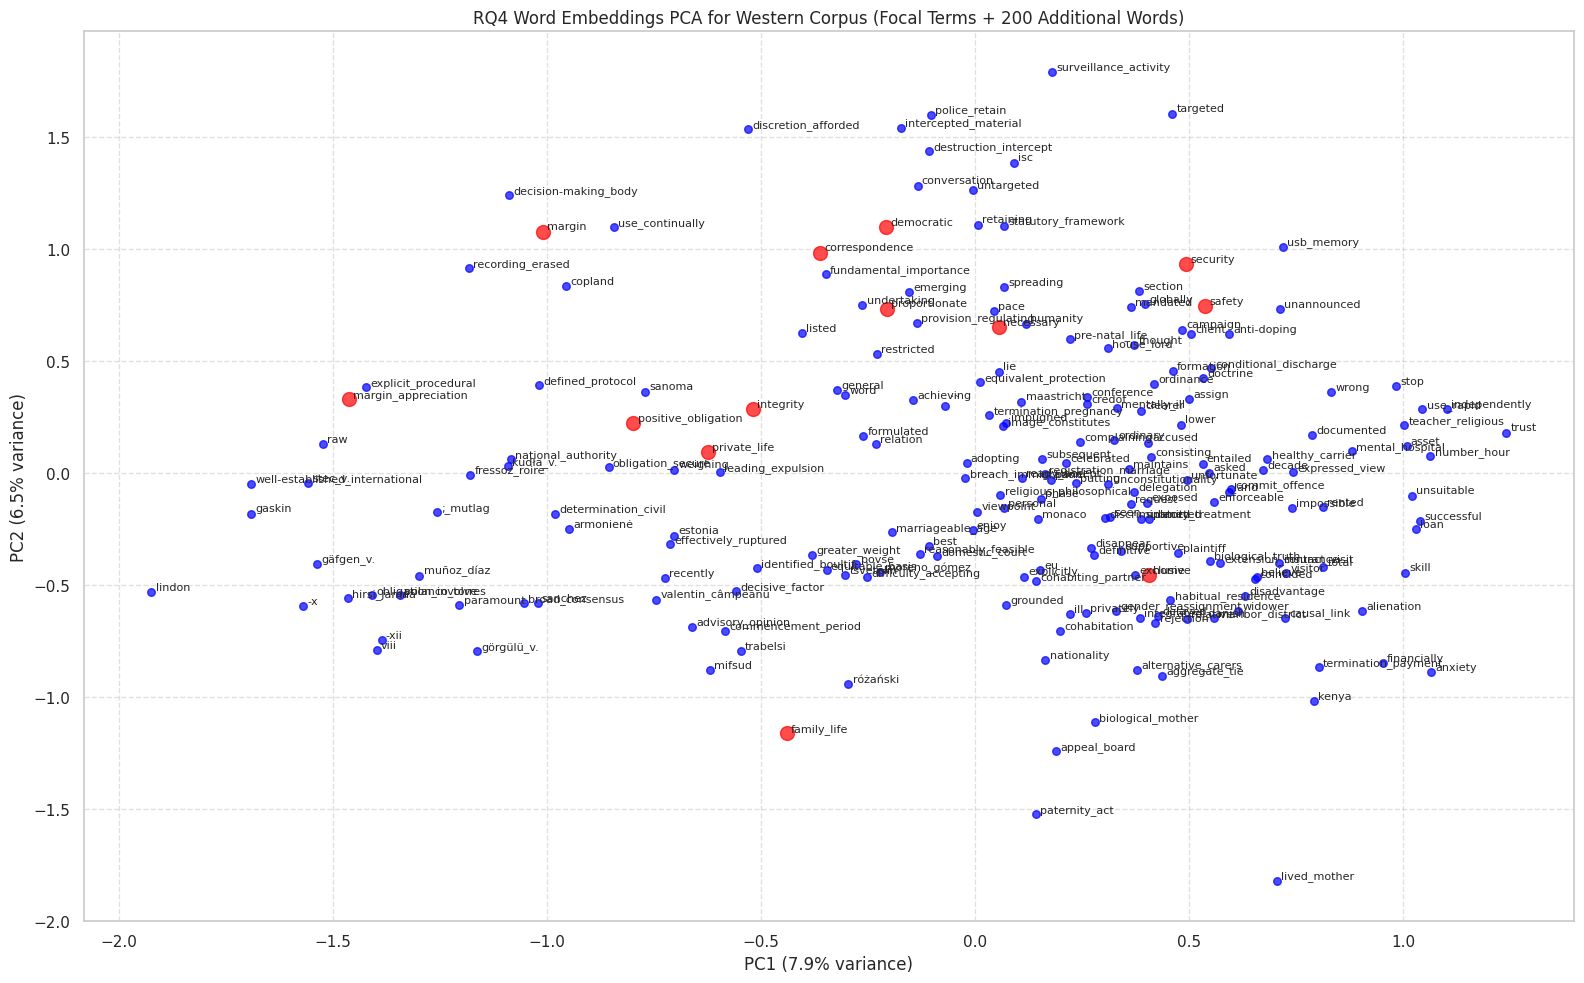

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np # For potential array operations if needed
import random # Import random module

# --- Configuration ---
# Choose which Word2Vec model to use (Eastern or Western)
selected_w2v_model = w2v_west # Options: w2v_east, w2v_west
model_name = "Eastern" if selected_w2v_model == w2v_east else "Western"

# Define the words for PCA visualization
# Using FOCAL_TERMS_ALL as these are the key terms for RQ4 analysis
# Filter out any terms that might not be in the selected model's vocabulary
focal_terms_in_model = [term for term in FOCAL_TERMS_ALL if term in selected_w2v_model.wv]

# --- Option to include additional words from the corpus ---
# Set to True to include a random sample of other words, False to only show focal terms
include_additional_words = True
num_additional_words = 200 # Number of additional random words to include if include_additional_words is True

words_for_pca = list(focal_terms_in_model) # Start with focal terms

if include_additional_words:
    all_vocab_words = list(selected_w2v_model.wv.key_to_index.keys())
    # Ensure uniqueness and avoid duplicates by excluding focal terms already in the list
    non_focal_words = [word for word in all_vocab_words if word not in FOCAL_TERMS_ALL and word not in focal_terms_in_model]

    if len(non_focal_words) > num_additional_words:
        additional_words = random.sample(non_focal_words, num_additional_words)
        words_for_pca.extend(additional_words)
    else:
        words_for_pca.extend(non_focal_words)
        print(f"Warning: Not enough non-focal words to sample {num_additional_words}. Included all {len(non_focal_words)} available non-focal words.")

if not words_for_pca:
    print(f"No words found in the {model_name} model's vocabulary for PCA.")
else:
    # Get vectors for the selected words
    vectors = [selected_w2v_model.wv[w] for w in words_for_pca]

    # Reduce dimensions using PCA
    pca = PCA(n_components=2, random_state=42) # Added random_state for reproducibility
    coords = pca.fit_transform(vectors)

    # Plotting
    plt.figure(figsize=(16,10)) # Increased figure size for more words
    for i, word in enumerate(words_for_pca):
        x, y = coords[i]
        color = 'red' if word in focal_terms_in_model else 'blue' # Differentiate focal terms
        size = 100 if word in focal_terms_in_model else 30 # Make focal terms larger
        plt.scatter(x, y, s=size, color=color, alpha=0.7)
        plt.text(x+0.01, y+0.01, word, fontsize=8) # Offset text slightly

    plt.title(f'RQ4 Word Embeddings PCA for {model_name} Corpus (Focal Terms + {len(words_for_pca) - len(focal_terms_in_model)} Additional Words)')
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

**Analysis for PCA**

The PCA plots show a shared Article 8 semantic core, but the surrounding clusters differ across Eastern and Western corpora. In particular, **margin and margin_appreciatio**n remain close in both corpora, yet Western usage is more tied to balancing and proportionality, while Eastern usage is more linked to discretion and contextual variation. PCA also shows that **necessary, home, family_life, and correspondence** occupy more separated regions, which supports the idea of issue-specific semantic specialization rather than one uniform Article 8 space.


**Conclusion :**

RQ4 asked whether the semantic representation of key Article 8 doctrinal concepts differs systematically between the Eastern and Western corpora, and whether any such drift accounts for the generalisation failure identified in RQ3. The Word2Vec analysis provides a qualified affirmative answer to both parts of the question, though the strength of the conclusion is bounded by the limitations of static embedding models trained on partitioned and imbalanced datasets.

On the first question, the evidence supports the existence of systematic semantic drift in a subset of core doctrinal terms. The normalised drift analysis identifies **"necessary," "home," "family life," and "correspondence"** as the terms with the clearest regional divergence, while **"margin," "margin of appreciation," "private life," and "integrity**" are comparatively stable as a shared semantic core. The stability of the margin of appreciation terms at the surface level is, however, deceptive. The t-SNE neighbourhood visualisations reveal that although "margin" occupies a similar position in both corpora, its semantic neighbourhood differs substantially, while Western usage is anchored to balancing and proportionality language, Eastern usage is surrounded by discretion, flexibility, and contextual variation vocabulary. The same surface term is therefore embedded in a different doctrinal operation depending on the regional corpus. A parallel divergence is visible for **"necessary,"** where the Western corpus operationalises the concept through formal adequacy testing and commensurateness, while the Eastern corpus frames it through control, factual justification, and case-by-case reasoning. For **family life" and "home** the divergence is less about doctrinal operation and more about the factual pathways through which the protected interest is engaged: Western cases consistently invoke questions of legal status, recognition, and quiet enjoyment, while Eastern cases centre on physical separation, direct interference, and concrete occupancy disputes.

On the second question, the semantic drift findings offer a partial but meaningful explanation for the generalisation failure. The RQ3 cross-regional experiment showed that the Eastern-trained model collapsed when applied to Western cases, generating a high false positive rate by treating Western procedural complexity as evidence of violation. The t-SNE results suggest why: the Eastern model learns that **"necessary," "margin,"** and related terms function as markers of state overreach and factual control, because that is the doctrinal logic in which those terms appear in the Eastern corpus. When the same terms appear in Western cases embedded in a proportionality balancing framework, the model misreads the vocabulary as carrying the Eastern meaning. The semantic neighbourhood of the concept, not just the concept itself, is what the classifier is implicitly learning, and that neighbourhood does not transfer.

This account is consistent with but does not fully exhaust the explanation for the generalisation gap. The RQ3 analysis also identified Russia-specific overfitting as a structural driver: the Eastern corpus is so heavily concentrated on Russian cases with near-universal violation rates that the model acquires country-specific factual boilerplate rather than generalisable legal reasoning patterns. Semantic drift and respondent state concentration are therefore complementary explanations rather than competing ones. The drift analysis explains why the model fails at the level of doctrinal language; the overfitting analysis explains why the training signal was distorted in the first place.

The appropriate conclusion is that there is meaningful evidence of systematic semantic drift in the use of key Article 8 concepts across the two regional corpora, and that this drift contributes to the model's inability to generalise across jurisdictional boundaries. The core doctrinal vocabulary of Article 8 is shared, but the legal work it performs differs by region in ways that a bag-of-words or static embedding classifier cannot reliably detect. Resolving this limitation would require a contextualised representation model such as BERT, which captures how the same term functions differently depending on the surrounding sentence structure and legal framing. That step remains outside the scope of the present study but is the natural direction for future work.


##Final Critical Reflections and Limitations

While this project successfully establishes foundational predictive models for European Court of Human Rights decisions (RQ1), extracts overarching legal themes (RQ2), and maps the semantic and jurisprudential divides between Eastern and Western European Article 8 cases (RQ3), it is critical to acknowledge the boundaries of our methodology to ensure we do not conflate mathematical artifacts with genuine legal reasoning.

First, across our initial baseline models and topic analyses in RQ1, RQ2 and RQ3, the predictive modeling suffers from data contamination and future leakage due to the presence of Article 41 just satisfaction awards. Because the Court retroactively includes financial remedy boilerplate only when a violation is found, the models learned to identify this structural text rather than the substantive legal arguments, meaning future research must explicitly excise these paragraphs prior to feature extraction.

Second, our cross-regional generalization experiment exposed a severe geographic dataset bias, as the Eastern European corpus is overwhelmingly dominated by Russian cases with a near-universal violation rate. This imbalance caused the Eastern-trained models to overfit to country-specific factual boilerplate, learning a factual shortcut that automatically equates state interference with a violation rather than learning generalizable doctrinal boundaries.

Third, in RQ3, our feature extraction methodology necessitated rigid hyperparameter tuning, specifically constraining the Non-Negative Matrix Factorization to exactly 20 topics to prevent high-dimensionality overfitting on our smaller regional datasets. While necessary, this forced topic collapsing, mashing distinct, nuanced legal concepts together into single mathematical features and sacrificing granular doctrinal precision for macro-level interpretability.

Fourth, in RQ4, our models suffer from algorithmic blindspots because both the NMF topic modeling and the Word2Vec semantic drift analysis rely on static word representations. These bag-of-words and local-window approaches successfully map broad vocabulary differences but cannot understand sentence-level context, such as how the Court dynamically applies phrases like the margin of appreciation, directly necessitating a transition to contextualized large language models like BERT in future studies.

Finally, our reliance on Generative AI in RQ3—specifically the Gemini 2.5 Flash Lite model—to conduct the misclassification analysis introduces a significant interpretative risk. While prompting the LLM to act as a legal expert efficiently identified error clusters, it risks projecting sophisticated human jurisprudential reasoning onto what are fundamentally just the SVM's statistical classification errors. The LLM may hallucinate complex legal rationales for misclassifications that are actually driven by simple mathematical noise or vocabulary gaps, meaning its diagnostic outputs must be viewed as an unverified approximation rather than authoritative legal truth.


# References

**Academic Papers**

* Akdemir, I. (2023). Essays on Law and Natural Language Processing.
*   Aletras, N., Tsarapatsanis, D., Preotiuc-Pietro, D., & Lampos, V. (2016). Predicting judicial decisions of the European Court of Human Rights: A natural language processing perspective. PeerJ Computer Science, 2, e93. https://doi.org/10.7717/peerj-cs.93
* Calı, B. (2010). The Logics of Supranational Human Rights Litigation, Official Acknowledgment, and Resolving the Problem of Structural Human Rights Violations. Law & Social Inquiry, 35(2), 311-337.
* Chalkidis, I., Androutsopoulos, I., &
Aletras, N. (2019). Neural legal judgment prediction in English. In Proceedings of the 57th Annual Meeting of the Association for Computational Linguistics (pp. 4317–4323). Association for Computational Linguistics. https://doi.org/10.18653/v1/P19-1424
* Hamilton, W.L., Leskovec, J. and Jurafsky, D., 2016. Cultural shift or linguistic drift? Comparing two computational measures of semantic change. In Proceedings of EMNLP 2016, pp. 2116–2121.
* Medvedeva, M., Vols, M., & Wieling, M. (2020). Using machine learning to predict decisions of the European Court of Human Rights. Artificial Intelligence and Law, 28(2), 237–266. https://doi.org/10.1007/s10506-019-09255-y
* O'Sullivan, C., & Beel, J. (2019). Predicting the outcome of judicial decisions made by the European Court of Human Rights. ADAPT Centre, Trinity College Dublin.



**ECHR Cases**

* Big Brother Watch and Others v. the United Kingdom, App. Nos. 58170/13, 62322/14 and 24960/15 (European Court of Human Rights Grand Chamber, 25 May 2021). https://hudoc.echr.coe.int
* Bou Hassoun v. Bulgaria, App. No. 72893/14 (European Court of Human Rights, 2020). https://hudoc.echr.coe.int
* Breyer v. Germany, App. No. 50001/12 (European Court of Human Rights, 30 January 2020). https://hudoc.echr.coe.int
* El-Masri v. The Former Yugoslav Republic of Macedonia, App. No. 39630/09 (European Court of Human Rights Grand Chamber, 13 December 2012). https://hudoc.echr.coe.int
* Ivinović v. Croatia, App. No. 13006/13 (European Court of Human Rights, 18 September 2014). https://hudoc.echr.coe.int
* Keegan v. Ireland, App. No. 16969/90 (European Court of Human Rights, 26 May 1994). https://hudoc.echr.coe.int
* Lebbink v. The Netherlands, App. No. 45582/99 (European Court of Human Rights, 1 June 2004). https://hudoc.echr.coe.int
* Marckx v. Belgium, App. No. 6833/74 (European Court of Human Rights, 13 June 1979). https://hudoc.echr.coe.int
* Oliari and Others v. Italy, App. Nos. 18766/11 and 36030/11 (European Court of Human Rights, 21 July 2015). https://hudoc.echr.coe.int
* Roman Zakharov v. Russia, App. No. 47143/06 (European Court of Human Rights Grand Chamber, 4 December 2015). https://hudoc.echr.coe.int
* Schalk and Kopf v. Austria, App. No. 30141/04 (European Court of Human Rights, 24 June 2010). https://hudoc.echr.coe.int
X v. Finland, App. No. 34806/04 (European Court of Human Rights, 3 July 2012). https://hudoc.echr.coe.int